## False Negative Ereignisse untersuchen ##

In [1]:
from pathlib import Path
import datetime as dt

import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import zarr
import pandas as pd

from data_registry import Bibliography
from domino.core import LaggedAnalyser, PatternFilter, IndexGenerator
from domino.prediction import PredictionTest
from domino import agg
from coords_workflow_utils import PreparedCoordsLoader, NUTSMaskTools
from scipy.stats import ks_2samp
from sklearn.metrics import roc_curve, auc

import cartopy.crs as ccrs
import cmocean.cm as cm

## Configuration ##

In [2]:
# -----CONFIGURATION----------
bib = Bibliography(Path("data"))
bib.add("energy", "WON", "daily", "subcountry", "prepared/WON_daily_subcountry_prepared_DJF.csv")
# bib.add("energy", "SPV", "daily", "subcountry", "prepared/SPV_daily_subcountry_prepared_DJF.csv")
bib.add("atmosphere", "mean_sea_level_pressure", "daily", "subcountry", "ERA5/prepared/DJF_anom/mean_sea_level_pressure")
# bib.add("atmosphere", "geopotential", "daily", "subcountry", "ERA5/prepared/DJF_anom/geopotential500")
# bib.add("atmosphere", "wind_speed", "daily", "subcountry", "ERA5/prepared/DJF_anom/wind_speed")
# bib.add("atmosphere", "v_component_of_wind", "daily", "subcountry", "ERA5/prepared/DJF_anom/v_component_of_wind")
# bib.add('atmosphere', 'total_column_water_vapour', 'daily', 'global', 'ERA5/prepared/DJF_anom/total_column_water_vapour')
# bib.add('atmosphere', '2m_temperature', 'daily', 'global', 'ERA5/prepared/DJF_anom/2m_temperature')
# bib.add('atmosphere', 'relative_humidity', 'daily', 'global', 'ERA5/prepared/DJF_anom/relative_humidity700')

# -----VARIABLES-----------
erstelldatum = dt.date.today()
lags = [-4,-3,-2,-1,0] # [-6, -5, -4, -3, -2, -1, 0]
region_ziel = "TenneT"  # region der ziel variablen
region_prec = "EUROPE"  # welche Daten werden als precursor verwendet
timeperiod = "1979-2025"  # zeitraum der analysierten daten
quant = 0.1  # welches quantile => def extreme event
extreme_event = "l"  # l=low 0.1, h=high 0.9
cv_version = ''
maskierung = '_noMask'
test_version = 'tso_cv'
test_version_region = '_TenneT-with-50Hertz'

# -----OPTIONS-----------
use_deseasonalization = True  # Deseasonalisierung durchführen?
deseasonalization_agg = "dayofyear"  # Aggregationsmethode: 'dayofyear', 'month', etc.
deseasonalization_smooth = 30  # Glättungsfenster für deseasonalization
use_bootstrap = False  # Bootstrap Significance Test durchführen?
bootstrap_num = 100  # Anzahl Bootstrap-Samples
bootstrap_p = 0.05  # Signifikanzniveau
min_connected_size = 10

energy_entries = bib.get_by_category("energy")
atm_entries = bib.get_by_category("atmosphere")

In [3]:
# load event and precursor data to set up analyser
energy_entry = energy_entries[0]
atm_entry = atm_entries[0]

event = PreparedCoordsLoader.load_energy_event_from_prepared(
    path=energy_entry.path,
    energy_name=energy_entry.name,
    region_ziel=region_ziel,
    quant=quant,
    extreme_event=extreme_event,
)
print(event)

<xarray.DataArray 'WON' (time: 4211)> Size: 34kB
array([0, 0, 0, ..., 0, 0, 0], shape=(4211,))
Coordinates:
  * time     (time) datetime64[us] 34kB 1979-01-01 1979-01-02 ... 2025-02-28


In [4]:
from regionalmeancalculator import RegionalMeanCalculator
@staticmethod
def load_energy_values_from_prepared(
    path: Path,
    energy_name: str,
    region_ziel: str | None,
) -> xr.DataArray:
    """
    Load prepared energy data (long format) and return absolute values
    (no thresholding, no binarization).

    Expected CSV format:
    Date, NUTS_ID, <energy_name>, lon, lat
    """
    import pandas as pd
    import xarray as xr

    df = pd.read_csv(path, parse_dates=["Date"])

    if energy_name not in df.columns:
        raise ValueError(f"Spalte '{energy_name}' fehlt in {path}")

    # long → wide
    df_wide = (
        df.pivot_table(
            index="Date",
            columns="NUTS_ID",
            values=energy_name,
            aggfunc="mean"
        )
        .sort_index()
    )

    # Regionale Aggregation
    if region_ziel is not None:
        calculator = RegionalMeanCalculator()
        series = calculator.calculate_mean(df=df_wide, region_name=region_ziel)
    else:
        series = df_wide.mean(axis=1)
        series.name = energy_name

    values_da = xr.DataArray(
        series.to_numpy(),
        dims="time",
        coords={"time": series.index.to_numpy()},
        name=energy_name,
    )

    return values_da

In [5]:
event_abs = load_energy_values_from_prepared(
    path=energy_entry.path,
    energy_name=energy_entry.name,
    region_ziel=region_ziel
)
print(event_abs)

<xarray.DataArray 'WON' (time: 4211)> Size: 34kB
array([0.44610972, 0.28472988, 0.39577783, ..., 0.23814105, 0.18630457,
       0.09620564], shape=(4211,))
Coordinates:
  * time     (time) datetime64[us] 34kB 1979-01-01 1979-01-02 ... 2025-02-28


In [6]:
# lade einzelne atm variablen als xr.Dataset
atm_entry = atm_entries[0]
ATM_NAME = atm_entry.name # "geopotential", "mean_sea_level_pressure", "2m_temperature"
LEVEL = '' # '' for non level data
WEATHERBENCH_DAILY_PATH = atm_entry.path
print(WEATHERBENCH_DAILY_PATH)
print("[INFO] Merging all years into a single dataset...")
files = sorted(WEATHERBENCH_DAILY_PATH.glob("*.nc")) #era5_daily_
ds_all = xr.open_mfdataset(
    files, combine="by_coords",
    chunks={"time": 50, "latitude":50, "longitude":50} # changed time from 365 for deseason
).load()
print("[INFO] Loaded and merged WeatherBench dailymeans dataset")

ds_djf = ds_all.sel(time=ds_all.time.dt.month.isin([12, 1, 2]))#ds_all.sel(init_time=ds_all.init_time.dt.month.isin([12, 1, 2]))
ds_all = ds_djf
month_idx = '_DJF'
del ds_djf
ds_msl = ds_all

data\ERA5\prepared\DJF_anom\mean_sea_level_pressure
[INFO] Merging all years into a single dataset...
[INFO] Loaded and merged WeatherBench dailymeans dataset


In [7]:
# # lade einzelne atm variablen als xr.Dataset
# atm_entry = atm_entries[1]
# ATM_NAME = atm_entry.name # "geopotential", "mean_sea_level_pressure", "2m_temperature"
# LEVEL = '' # '' for non level data
# WEATHERBENCH_DAILY_PATH = atm_entry.path
# print(WEATHERBENCH_DAILY_PATH)
# print("[INFO] Merging all years into a single dataset...")
# files = sorted(WEATHERBENCH_DAILY_PATH.glob("*.nc")) #era5_daily_
# ds_all = xr.open_mfdataset(
#     files, combine="by_coords",
#     chunks={"time": 50, "latitude":50, "longitude":50} # changed time from 365 for deseason
# ).load()
# print("[INFO] Loaded and merged WeatherBench dailymeans dataset")

# ds_djf = ds_all.sel(time=ds_all.time.dt.month.isin([12, 1, 2]))#ds_all.sel(init_time=ds_all.init_time.dt.month.isin([12, 1, 2]))
# ds_all = ds_djf
# month_idx = '_DJF'
# del ds_djf
# ds_z500 = ds_all

In [8]:
# # lade einzelne atm variablen als xr.Dataset
# atm_entry = atm_entries[2]
# ATM_NAME = atm_entry.name # "geopotential", "mean_sea_level_pressure", "2m_temperature"
# LEVEL = '' # '' for non level data
# WEATHERBENCH_DAILY_PATH = atm_entry.path
# print(WEATHERBENCH_DAILY_PATH)
# print("[INFO] Merging all years into a single dataset...")
# files = sorted(WEATHERBENCH_DAILY_PATH.glob("*.nc")) #era5_daily_
# ds_all = xr.open_mfdataset(
#     files, combine="by_coords",
#     chunks={"time": 50, "latitude":50, "longitude":50} # changed time from 365 for deseason
# ).load()
# print("[INFO] Loaded and merged WeatherBench dailymeans dataset")

# ds_djf = ds_all.sel(time=ds_all.time.dt.month.isin([12, 1, 2]))#ds_all.sel(init_time=ds_all.init_time.dt.month.isin([12, 1, 2]))
# ds_all = ds_djf
# month_idx = '_DJF'
# del ds_djf
# ds_ws = ds_all

In [9]:
# rechne longitudes bei allen um
# ds_ws = ds_ws.assign_coords(
#     longitude=((ds_ws.longitude + 180) % 360) - 180
# ).sortby("longitude")
# ds_msl = ds_msl.assign_coords(
#     longitude=((ds_msl.longitude + 180) % 360) - 180
# ).sortby("longitude")
# ds_z500 = ds_z500.assign_coords(
#     longitude=((ds_z500.longitude + 180) % 360) - 180
# ).sortby("longitude")

In [10]:
ds_all = ds_msl#xr.merge([ds_msl, ds_z500, ds_ws])

## Analyser ##

In [11]:
# split into training and test data
training_predictor=ds_all.sel(time=slice('1980','2010'))
training_event=event.sel(time=slice('1980','2010'))
test_predictor=ds_all.sel(time=slice('2011','2022'))
test_event=event.sel(time=slice('2011','2022')) 
# training_predictor=ds_all.sel(time=slice('1992','2022'))
# training_event=event.sel(time=slice('1992','2022'))
# test_predictor=ds_all.sel(time=slice('1980','1991'))
# test_event=event.sel(time=slice('1980','1991'))
# test_predictor = ds_all.sel(time=slice("1990", "2001"))
# test_event = event.sel(time=slice("1990", "2001"))
# training_predictor = xr.concat([ds_all.sel(time=slice("1979", "1989")), ds_all.sel(time=slice("2002", "2022"))],dim="time")
# training_event = xr.concat([event.sel(time=slice("1979", "1989")), event.sel(time=slice("2002", "2022"))], dim="time")
# test_predictor = ds_all.sel(time=slice("2000", "2011"))
# test_event = event.sel(time=slice("2000", "2011"))
# training_predictor = xr.concat([ds_all.sel(time=slice("1979", "1999")), ds_all.sel(time=slice("2012", "2022"))],dim="time")
# training_event = xr.concat([event.sel(time=slice("1979", "1999")), event.sel(time=slice("2012", "2022"))], dim="time")

In [12]:
analyser = LaggedAnalyser(event=training_event, variables=training_predictor)
analyser.lag_variables(lags, offset_unit='days', mode='past')

In [13]:
composites = xr.open_dataset(f'data//domino_output_coords_weatherbench/{energy_entry.name}/{energy_entry.name}-{extreme_event}_{region_ziel}_{ATM_NAME}_{region_prec}_1979_lags_{"_".join(map(str, lags))}_composites_coords_deseasonalized_DJF_anom.nc')#analyser.compute_composites(as_anomaly=True)
lagged_means = xr.open_dataset(f'data//domino_output_coords_weatherbench/{energy_entry.name}/{energy_entry.name}-{extreme_event}_{region_ziel}_{ATM_NAME}_{region_prec}_1979_lags_{"_".join(map(str, lags))}_lagged-means_coords_deseasonalized_DJF_anom.nc')

In [14]:
analyser.composites = composites
analyser.lagged_means = lagged_means
analyser.composites_are_anomaly = True
analyser.composite_func = (agg.mean_ds, agg.cat_occ_ds)

In [15]:
atm_entry = atm_entries[0]
ATM_NAME = atm_entry.name
S = xr.open_dataset(f'data//domino_output_coords_weatherbench/{energy_entry.name}/100/{energy_entry.name}-{extreme_event}_{region_ziel}_{ATM_NAME}_{region_prec}_1979_lags_{"_".join(map(str, lags))}_bootstrap-composites_deseasonalized_DJF_anom.nc')

In [16]:
S = S.assign_coords(
    longitude=((S.longitude + 180) % 360) - 180
).sortby("longitude")
analyser.composite_sigs = S
masked_composite=S

In [17]:
# S=analyser.bootstrap_significance(2,p=0.1)
# masked_composite=composites.where(S==1)

In [18]:
PF = PatternFilter(analyser=analyser)
thresh_dict=dict(relative_humidity=0.05, total_column_water_vapour=1.0, **{'2m_temperature': 1.}, mean_sea_level_pressure=250, geopotential=300, wind_speed=2.5)

def abs_amplitude_over_threshold(val_ds,thresh_dict):
    return abs(val_ds)>xr.Dataset(thresh_dict)

PF.apply_value_mask(abs_amplitude_over_threshold,thresh_dict,mode='intersection')
mask1=PF.get_mask() #retrieve the new mask for plotting later.

In [19]:
composites

<xarray.Dataset> Size: 6MB
Dimensions:                  (lag: 5, index_val: 2, latitude: 289,
                              longitude: 561)
Coordinates:
  * lag                      (lag) int64 40B -4 -3 -2 -1 0
  * index_val                (index_val) int64 16B 0 1
  * latitude                 (latitude) float32 1kB 84.0 83.75 ... 12.25 12.0
  * longitude                (longitude) float32 2kB 270.0 270.2 ... 49.75 50.0
Data variables:
    mean_sea_level_pressure  (lag, index_val, latitude, longitude) float32 6MB ...

## Index Generator ##

In [20]:
IG=IndexGenerator()

In [21]:
data_vars = [atm_entries[0].name]#, 'geopotential', 'wind_speed'] mean_sea_level_pressure 2m_temperature total_column_water_vapour relative_humidity
var_name = data_vars[0]
training_predictor_partial = training_predictor[var_name]
test_predictor_partial = test_predictor[var_name]
masked_composite_partial = masked_composite[[var_name]]
masked_ds = composites #masked_composite_partial.where(mask1) #mask1 anwenden

In [22]:
# index berechnen für lags mit trainings daten
# index parameter abspeichern nach system: data/index_parameters/energy_variable/event/WON-l-predictor-index-1-training.nc
index_timelags = [-4,-3,-2,-1] #-4,-3,-2,-1,
for lag_id in index_timelags:
    print(f"Calculating index for lag {lag_id}...")
    index_slices=[dict(index_val=1,lag=lag_id)]
    indices=IG.generate(masked_ds,training_predictor_partial,dim='time',slices=index_slices)
    print(indices.data_vars)
    standardisation_params=IG.get_standardisation_params()
    print(standardisation_params)
    index_params_path = Path(f"data/index_parameters/{test_version}/{region_ziel}/{energy_entry.name}/{extreme_event}/{energy_entry.name}-{extreme_event}-{var_name}-index-{lag_id}-training{cv_version}{maskierung}{test_version_region}.nc")
    index_params_path.parent.mkdir(parents=True, exist_ok=True)
    standardisation_params.to_netcdf(index_params_path)
    print(f"Saved index parameters to {index_params_path}")

Calculating index for lag -4...
Data variables:
    mean_sea_level_pressure_index_val1_lag-4  (time) float32 11kB 0.2975 ... ...
<xarray.Dataset> Size: 48B
Dimensions:                                   (param: 2)
Coordinates:
  * param                                     (param) <U4 32B 'mean' 'std'
Data variables:
    mean_sea_level_pressure_index_val1_lag-4  (param) float64 16B 2.313e+08 8...
Saved index parameters to data\index_parameters\tso_cv\TenneT\WON\l\WON-l-mean_sea_level_pressure-index--4-training_noMask_TenneT-with-50Hertz.nc
Calculating index for lag -3...
Data variables:
    mean_sea_level_pressure_index_val1_lag-3  (time) float32 11kB 0.2541 ... ...
<xarray.Dataset> Size: 48B
Dimensions:                                   (param: 2)
Coordinates:
  * param                                     (param) <U4 32B 'mean' 'std'
Data variables:
    mean_sea_level_pressure_index_val1_lag-3  (param) float64 16B 2.846e+08 9...
Saved index parameters to data\index_parameters\tso_cv\Ten

In [23]:
stop here

SyntaxError: invalid syntax (4067800170.py, line 1)

## False Positve/ Negative Ereignisse finden

Calculating index for lag -4 on test data...
best treshold: 0.44870951061886
0.7719298245614035 0.33436532507739936
best treshold with FPR < 0.1: 1.2869789384595967


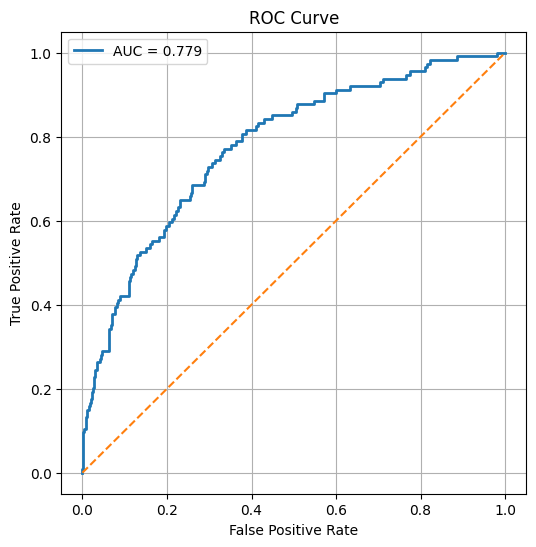

390
Calculating index for lag -3 on test data...
best treshold: 0.5463991507600736
0.7368421052631579 0.2930856553147575
best treshold with FPR < 0.1: 1.228606019420249


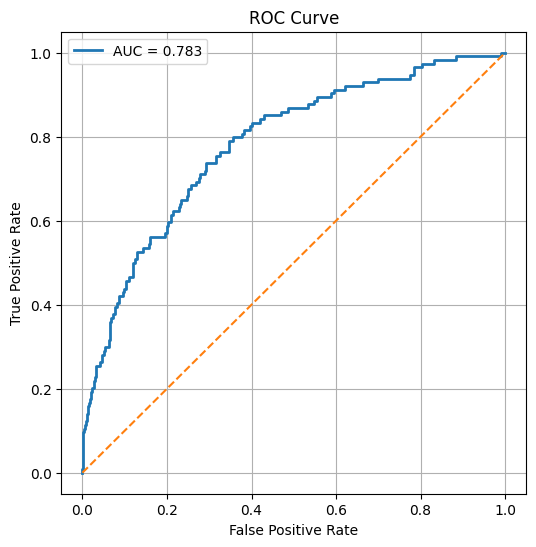

387
Calculating index for lag -2 on test data...
best treshold: 0.2815245370651847
0.8508771929824561 0.391124871001032
best treshold with FPR < 0.1: 1.2654199083095634


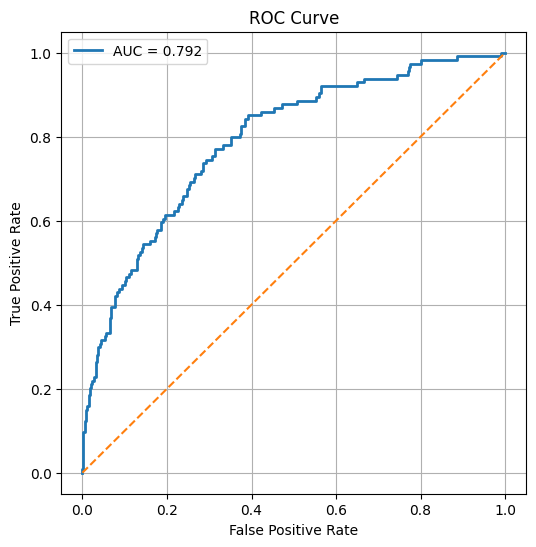

387
Calculating index for lag -1 on test data...
best treshold: 0.3528367591991708
0.8596491228070176 0.3570691434468524
best treshold with FPR < 0.1: 1.2616791546677284


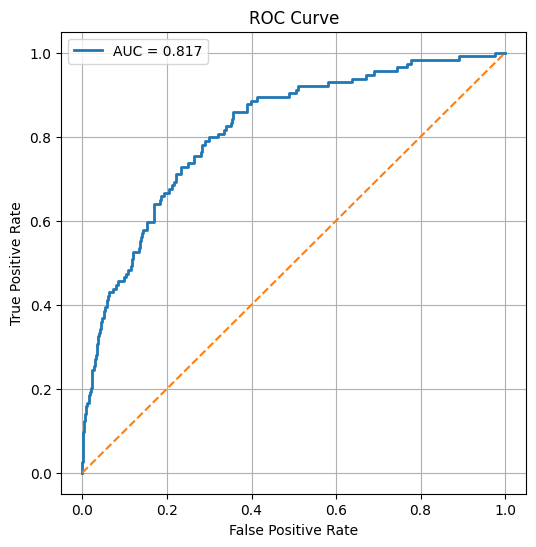

385
Calculating index for lag 0 on test data...
best treshold: 0.5704685867904007
0.8508771929824561 0.28173374613003094
best treshold with FPR < 0.1: 1.2330118454605532


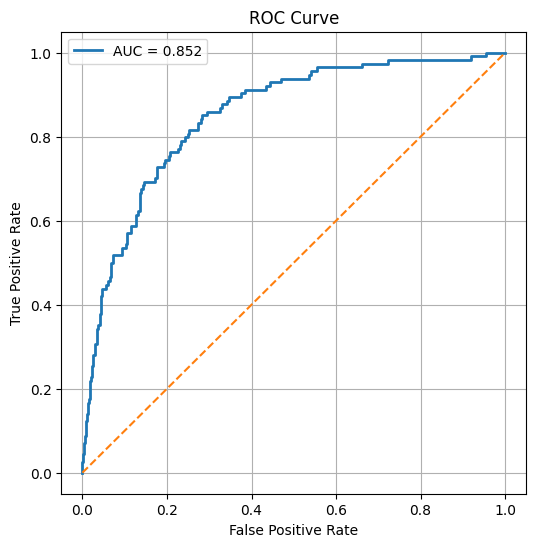

391


In [ ]:
# berechne index für test zeitreihe
# index_timelags = [0]
for lag_id in index_timelags:
    print(f"Calculating index for lag {lag_id} on test data...")
    index_slices=[dict(index_val=1,lag=lag_id)]
    # index parameter laden
    index_params_path = Path(f"data/index_parameters/{energy_entry.name}/{extreme_event}/{energy_entry.name}-{extreme_event}-{var_name}-index-{lag_id}-training.nc")
    index_params_ds = xr.open_dataset(index_params_path)
    mean = index_params_ds.sel(param='mean')
    std = index_params_ds.sel(param='std')
    # index_params_ds.close()
    # index berechnen
    test_index=IG.generate(masked_ds,test_predictor_partial,dim='time',slices=index_slices, ix_means=mean,ix_stds=std)

    y_score = test_index[f'{var_name}_index_val1_lag{lag_id}'].values
    y_true = test_event.values
    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)

    J = tpr - fpr
    best_idx = np.argmax(J)
    best_threshold = thresholds[best_idx]
    print('best treshold:',best_threshold)
    print(tpr[best_idx], fpr[best_idx])

    idx = np.where(fpr < 0.1)[0]
    best_idx = idx[np.argmax(tpr[idx])]
    threshold = thresholds[best_idx]
    print('best treshold with FPR < 0.1:',threshold)

    plt.figure(figsize=(6,6))
    plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.3f}')
    plt.plot([0,1], [0,1], '--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()
    plt.grid()
    savepath_fig = Path(f"fig/index_computation/{energy_entry.name}/{extreme_event}/{var_name}/ROC_Curve-testindex_{var_name}_lag{lag_id}.png")
    savepath_fig.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(savepath_fig)
    plt.show()

    # filtere alle index werte heraus, die über einem bestimmten threshold liegen (z.B. 0.5)
    t=0.5
    mask = (test_index[f'{var_name}_index_val1_lag{lag_id}'] > t)
    zeitpunkte = test_index.time.where(mask, drop=True)
    df_index = pd.DataFrame({
        "time": test_index.time.values,
        "index": test_index[f'{var_name}_index_val1_lag{lag_id}'].values,
        "event": test_event.values
    })
    df_sel = df_index[mask.values]
    savepath_zeitpunkte = Path(f"data/index_parameters/{energy_entry.name}/{extreme_event}/{energy_entry.name}-{extreme_event}-{var_name}-index-{lag_id}-false_positives-timeslots-threshold{t}.csv")
    savepath_zeitpunkte.parent.mkdir(parents=True, exist_ok=True)
    df_sel.to_csv(savepath_zeitpunkte, index=False)
    # speichere auch alle index werte
    savepath_df_index = Path(f"data/index_parameters/{energy_entry.name}/{extreme_event}/{energy_entry.name}-{extreme_event}-{var_name}-index-{lag_id}-test_index-threshold{t}.csv")
    df_index.to_csv(savepath_df_index, index=False)
    print(len(zeitpunkte))

In [ ]:
# zeitreihen einlesen und die false positive zeitpunkte untersuchen
df_lag0 = pd.read_csv(Path(f"data/index_parameters/{energy_entry.name}/{extreme_event}/WON-{extreme_event}-mean_sea_level_pressure-index-0-test_index-threshold0.5.csv"))

In [ ]:
event_abs_test = event_abs.sel(time=test_event.time)
won_df = event_abs_test.to_dataframe(name="WON").reset_index()
df_lag0["time"] = pd.to_datetime(df_lag0["time"])
won_df["time"] = pd.to_datetime(won_df["time"])
df_lag0_won = df_lag0.merge(won_df, on="time", how="left")

In [ ]:
print(df_lag0_won)
df_lag0_won.to_csv(
    Path(f"data/index_parameters/{energy_entry.name}/{extreme_event}/WON-{extreme_event}-mean_sea_level_pressure-index-0-test_index-threshold0.5_excel.csv"),
    index=False,
    sep=";",          # Excel in Deutschland mag oft Semikolon
    decimal=",",      # deutsches Dezimaltrennzeichen
    encoding="utf-8-sig"
)

           time     index  event       WON
0    2011-01-01 -0.474707      0  0.866324
1    2011-01-02 -0.757775      0  0.428604
2    2011-01-03 -0.663986      0  0.183389
3    2011-01-04 -0.639793      0  0.470639
4    2011-01-05 -0.604898      0  0.659014
...         ...       ...    ...       ...
1078 2022-12-27  0.538063      0  0.816615
1079 2022-12-28  0.788749      1  0.957178
1080 2022-12-29  1.037709      1  0.960084
1081 2022-12-30  1.103320      0  0.920930
1082 2022-12-31  1.213528      0  0.854558

[1083 rows x 4 columns]


In [ ]:
df_lag0_won.event.sum()

np.int64(114)

In [ ]:
# mean / std für index für event = 1 und event = 0 vergleichen
mean_event_1 = df_lag0_won[df_lag0_won['event'] == 1]['index'].mean()
std_event_1 = df_lag0_won[df_lag0_won['event'] == 1]['index'].std()
mean_event_0 = df_lag0_won[df_lag0_won['event'] == 0]['index'].mean()
std_event_0 = df_lag0_won[df_lag0_won['event'] == 0]['index'].std()

print(f"Event = 1: mean = {mean_event_1}, std = {std_event_1}")
print(f"Event = 0: mean = {mean_event_0}, std = {std_event_0}")

Event = 1: mean = 1.2206913414425504, std = 0.778901762820267
Event = 0: mean = 0.01108130490637294, std = 0.8961817379158464


In [ ]:
# mean / std für WON für event = 1 und event = 0 vergleichen
mean_won_event_1 = df_lag0_won[df_lag0_won['event'] == 1]['WON'].mean()
std_won_event_1 = df_lag0_won[df_lag0_won['event'] == 1]['WON'].std()
mean_won_event_0 = df_lag0_won[df_lag0_won['event'] == 0]['WON'].mean()
std_won_event_0 = df_lag0_won[df_lag0_won['event'] == 0]['WON'].std()
print(f"WON when event = 1: mean = {mean_won_event_1}, std = {std_won_event_1}")
print(f"WON when event = 0: mean = {mean_won_event_0}, std = {std_won_event_0}")

WON when event = 1: mean = 0.9522768933450293, std = 0.01209163608157282
WON when event = 0: mean = 0.46329053344639226, std = 0.2625424363820203


In [ ]:
# mean / std für WON wenn index > 0.5
mean_won_index_gt_0_5 = df_lag0_won[df_lag0_won['index'] > 0.5]['WON'].mean()
median_won_index_gt_0_5 = df_lag0_won[df_lag0_won['index'] > 0.5]['WON'].median()
std_won_index_gt_0_5 = df_lag0_won[df_lag0_won['index'] > 0.5]['WON'].std()
print(f"WON when index > 0.5: mean = {mean_won_index_gt_0_5}, median = {median_won_index_gt_0_5}, std = {std_won_index_gt_0_5}")

WON when index > 0.5: mean = 0.7481918051417207, median = 0.8130739904166667, std = 0.20825921802632988


In [ ]:
# mean / std für WON wenn index > 0.5 und event = 0
mean_won_index_gt_0_5_event_0 = df_lag0_won[(df_lag0_won['index'] > 0.5) & (df_lag0_won['event'] == 0)]['WON'].mean()
median_won_index_gt_0_5_event_0 = df_lag0_won[(df_lag0_won['index'] > 0.5) & (df_lag0_won['event'] == 0)]['WON'].median()
std_won_index_gt_0_5_event_0 = df_lag0_won[(df_lag0_won['index'] > 0.5) & (df_lag0_won['event'] == 0)]['WON'].std()
print(f"WON when index > 0.5 and event = 0: mean = {mean_won_index_gt_0_5_event_0}, median = {median_won_index_gt_0_5_event_0}, std = {std_won_index_gt_0_5_event_0}")

WON when index > 0.5 and event = 0: mean = 0.6799548821800209, median = 0.7180951798333334, std = 0.19808717557851427


In [ ]:
# max wert WON wenn event = 1
max_won_event_1 = df_lag0_won[df_lag0_won['event'] == 1]['WON'].max()
print(f"Max WON when event = 1: {max_won_event_1}")

Max WON when event = 1: 0.9659179845833334


In [ ]:
# min wert WON wenn event = 1
min_won_event_1 = df_lag0_won[df_lag0_won['event'] == 1]['WON'].min()
print(f"Min WON when event = 1: {min_won_event_1}")

Min WON when event = 1: 0.9254724338333334


In [ ]:
# liste mit daten wo index > 0.5 und event = 0
df_false_positives = df_lag0_won[(df_lag0_won['index'] > 0.5) & (df_lag0_won['event'] == 0)]

In [ ]:
# liste mit daten wo index < 0.5 und event = 1
df_false_negative = df_lag0_won[(df_lag0_won['index'] < -0.5) & (df_lag0_won['event'] == 1)]

In [ ]:
df_false_negative

,time,index,event,WON
453,2016-01-03,-1.236506,1,0.942644
915,2021-01-13,-0.525344,1,0.940368
940,2021-02-07,-1.482861,1,0.965290


2011-02-01 00:00:00


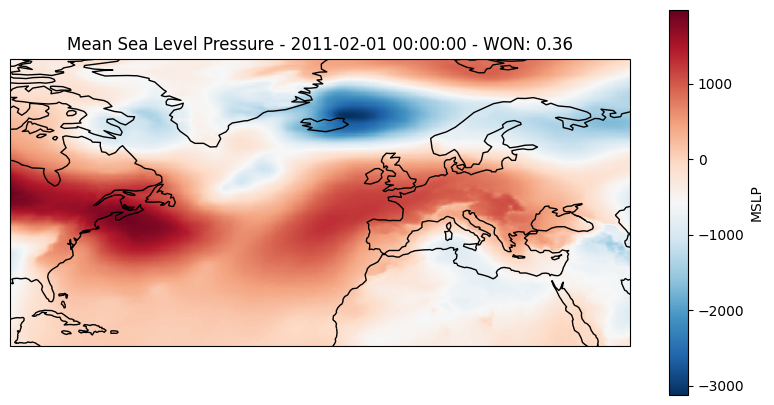

2011-02-02 00:00:00


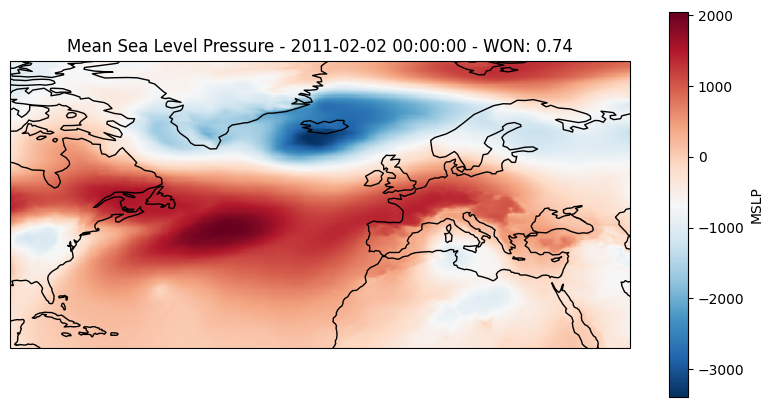

2011-02-03 00:00:00


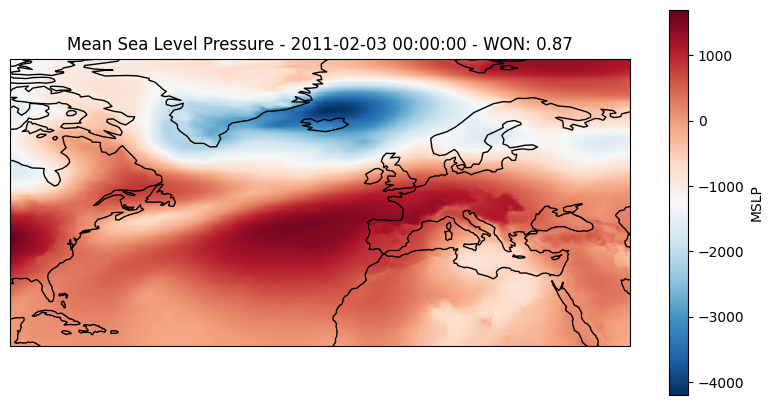

2011-02-05 00:00:00


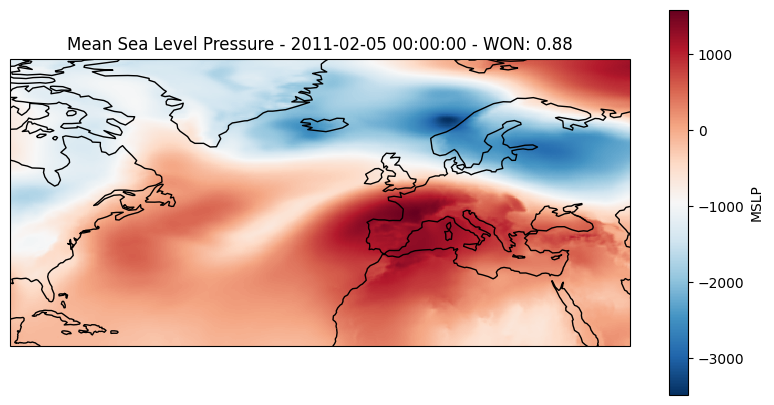

2011-02-06 00:00:00


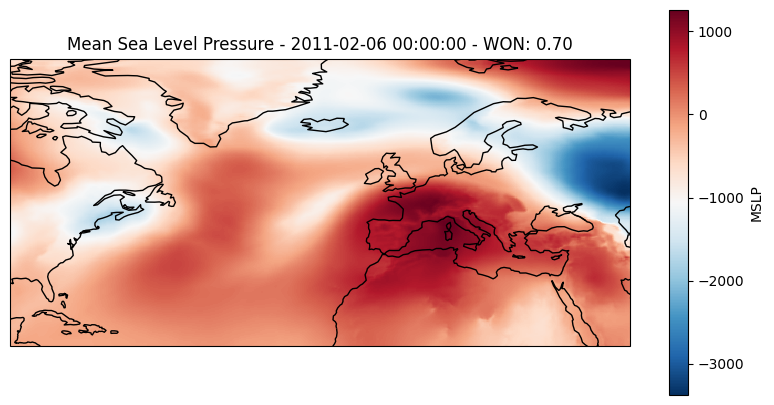

2011-02-08 00:00:00


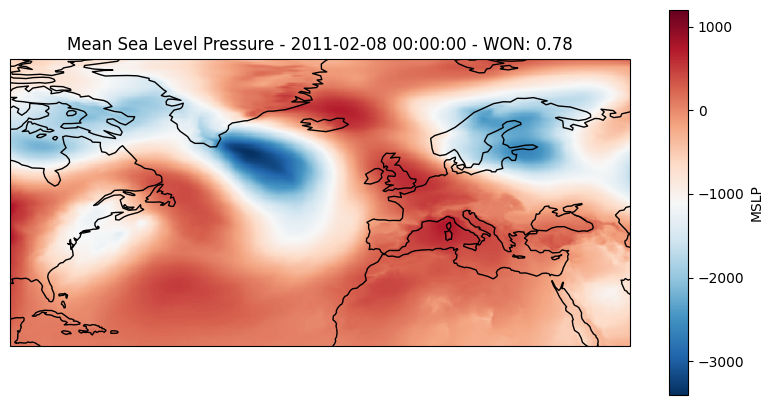

2011-12-01 00:00:00


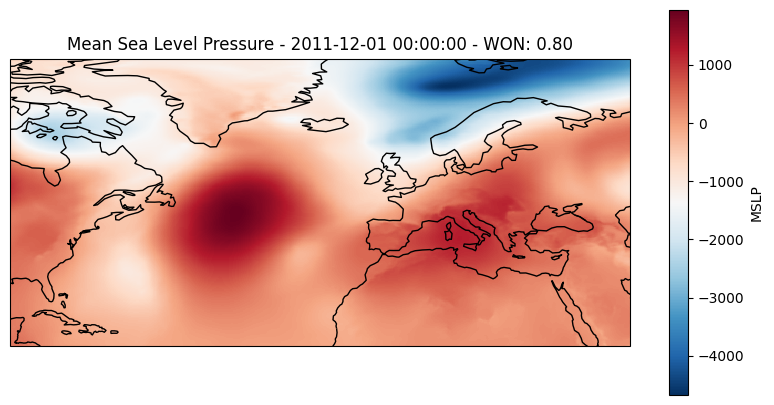

2011-12-02 00:00:00


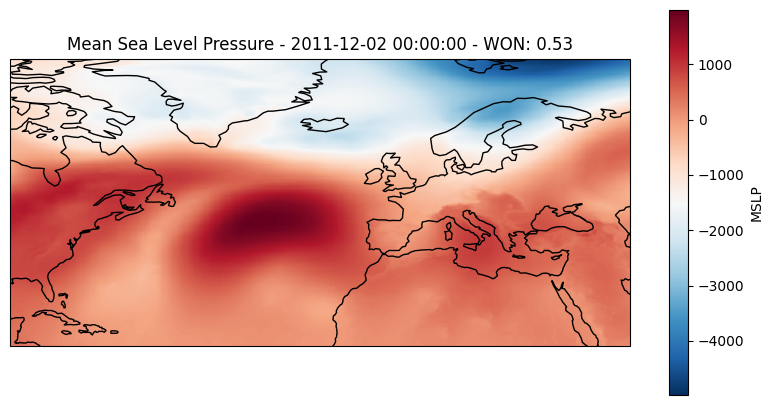

2011-12-04 00:00:00


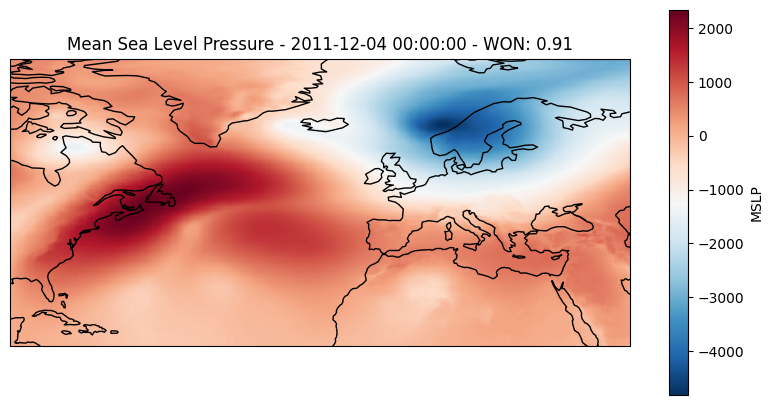

2011-12-05 00:00:00


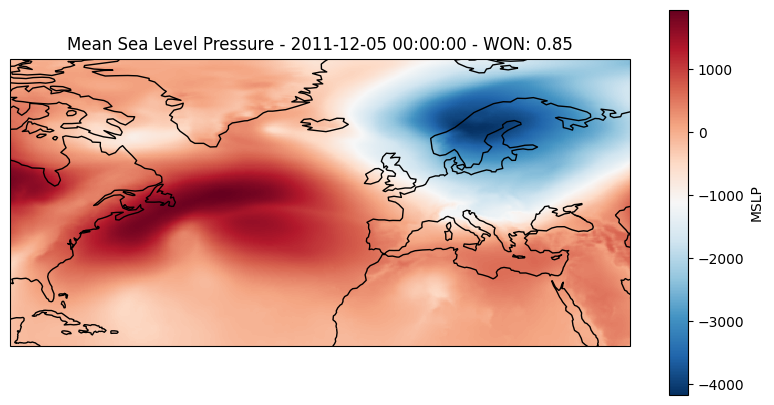

2011-12-06 00:00:00


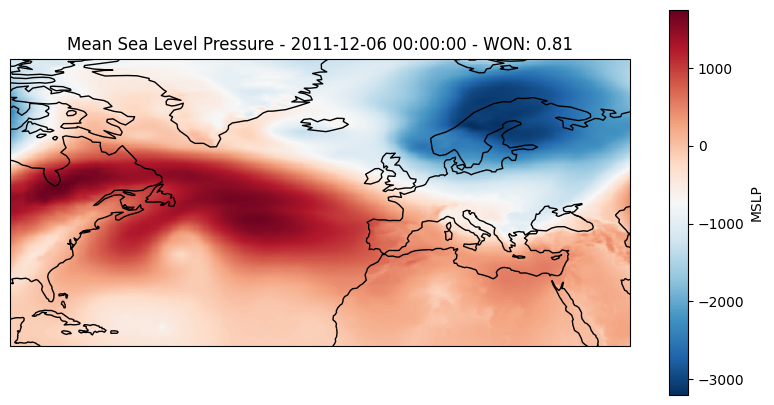

2011-12-07 00:00:00


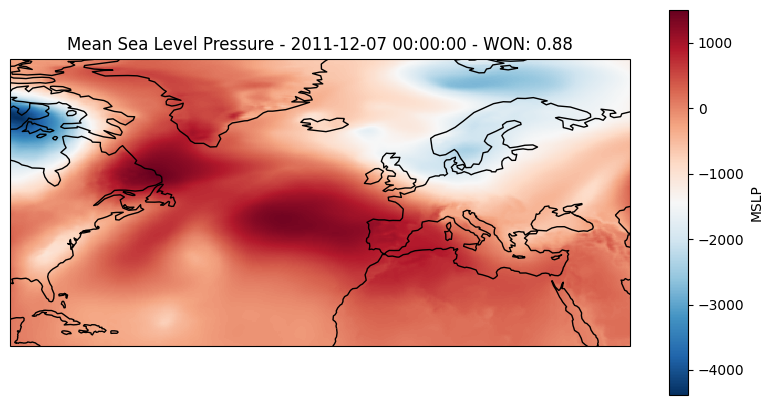

2011-12-08 00:00:00


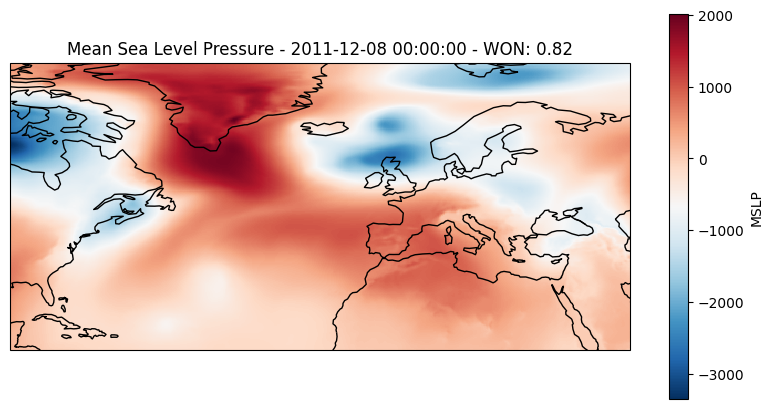

2011-12-10 00:00:00


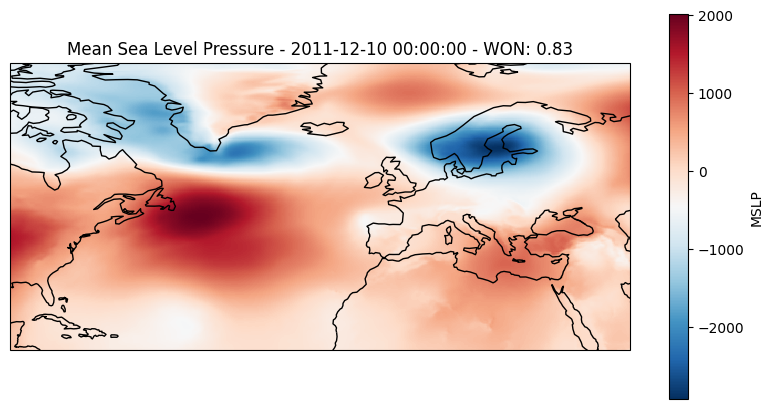

2011-12-11 00:00:00


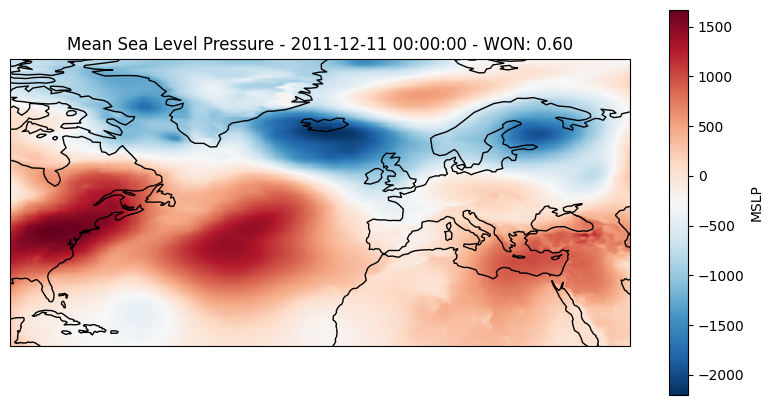

2011-12-12 00:00:00


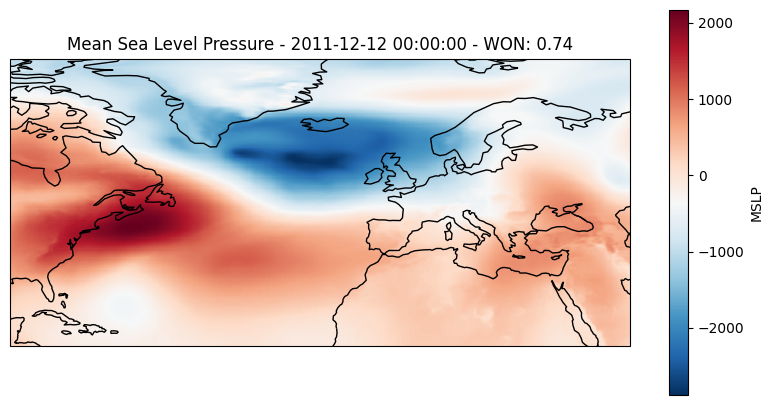

2011-12-14 00:00:00


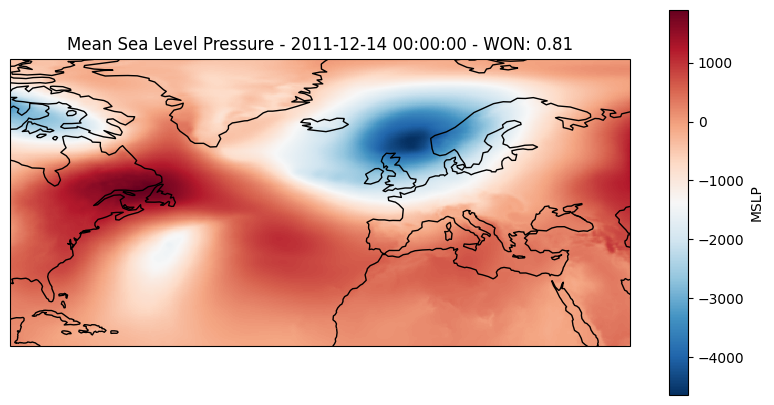

2011-12-15 00:00:00


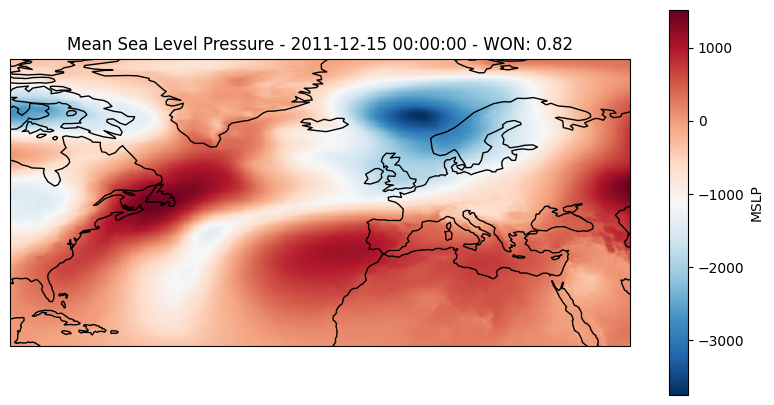

2011-12-16 00:00:00


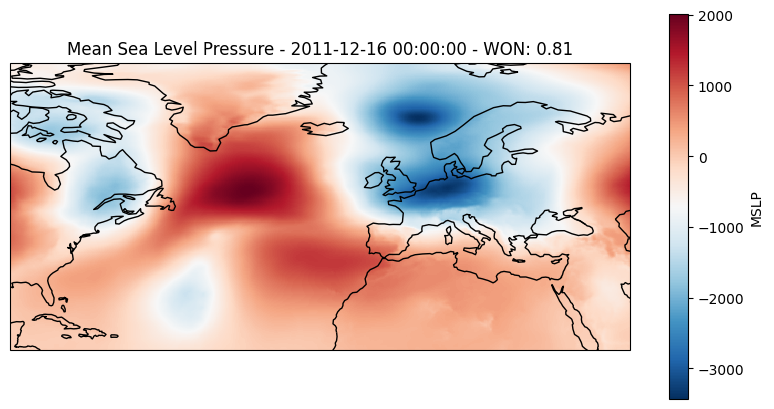

2011-12-17 00:00:00


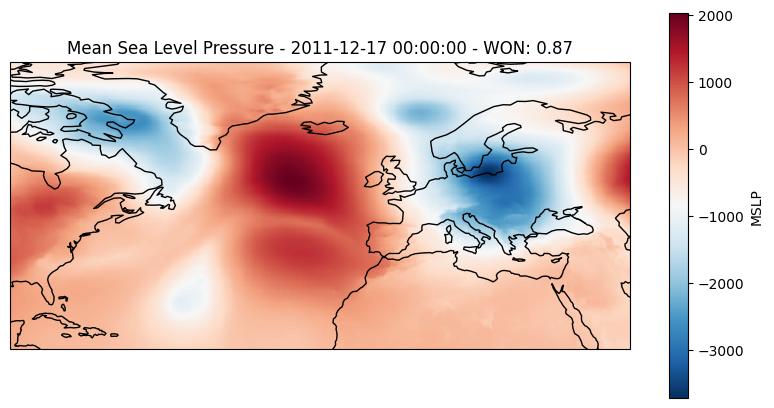

2011-12-18 00:00:00


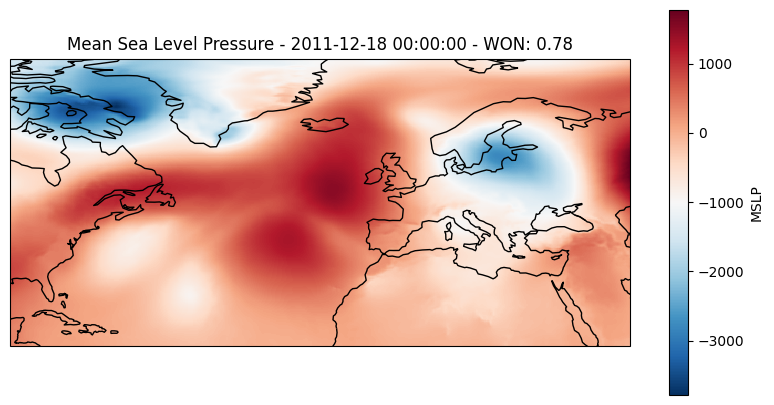

2011-12-23 00:00:00


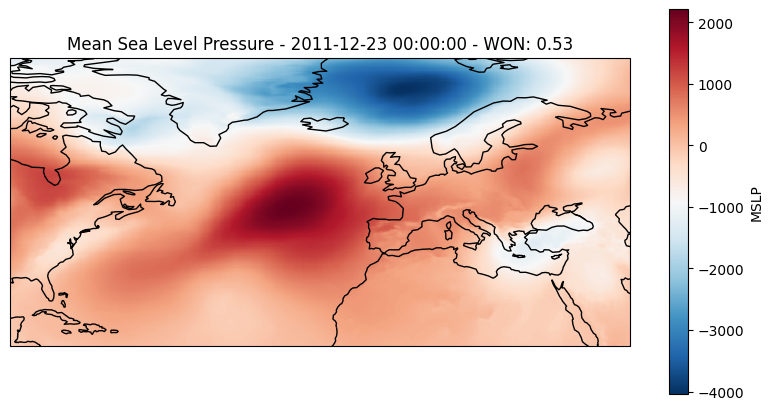

2011-12-24 00:00:00


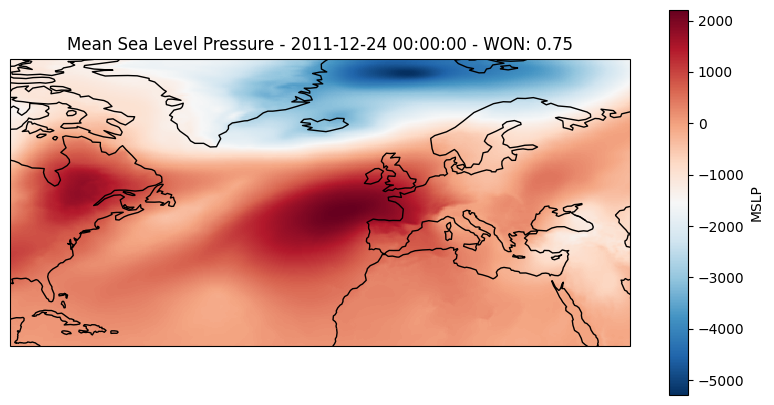

2011-12-25 00:00:00


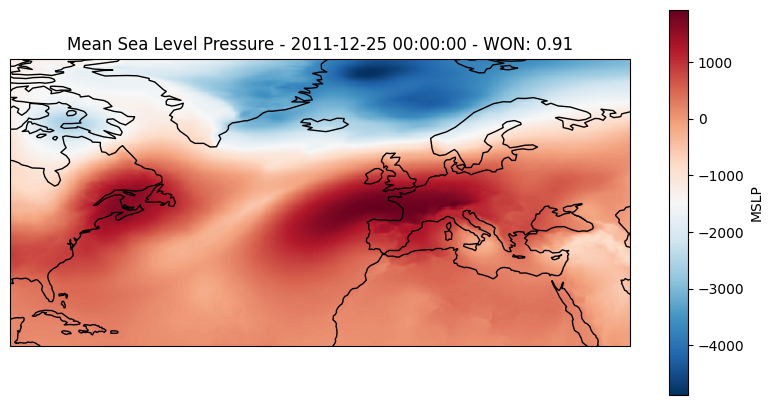

2011-12-26 00:00:00


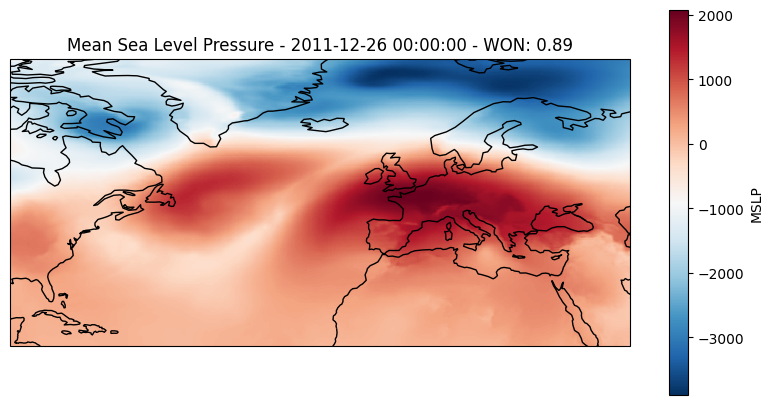

2011-12-27 00:00:00


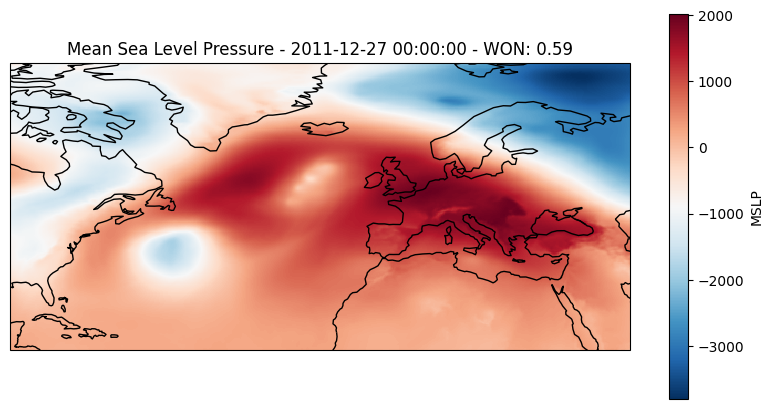

2011-12-28 00:00:00


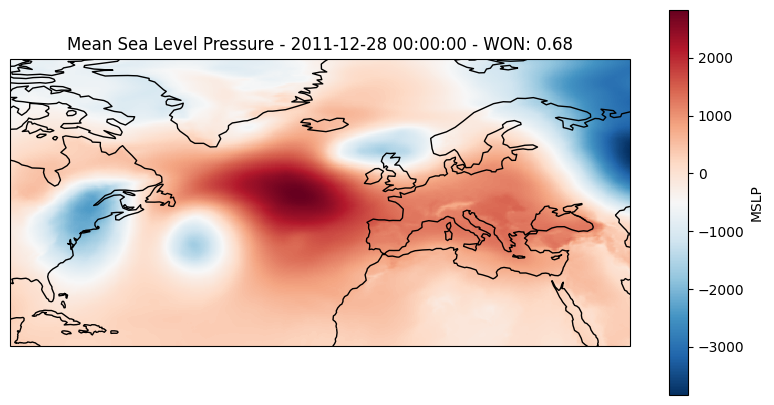

2011-12-30 00:00:00


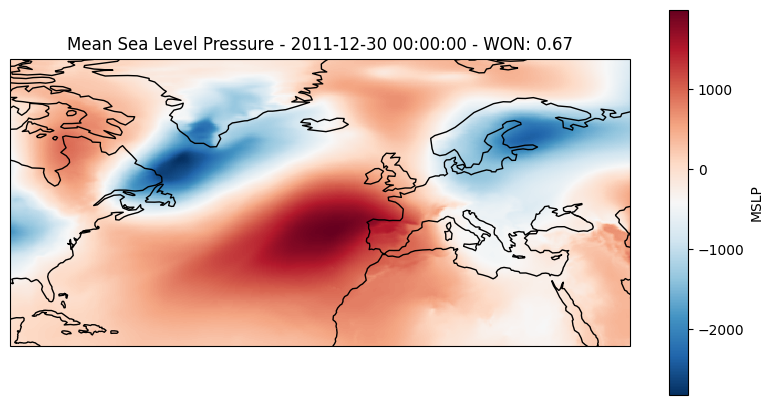

2011-12-31 00:00:00


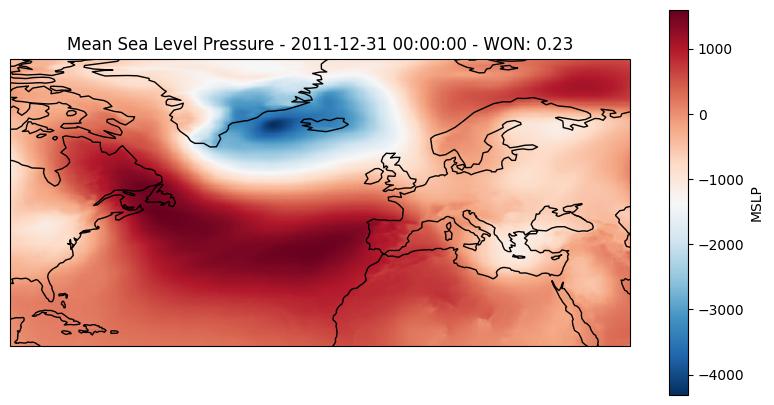

2012-01-01 00:00:00


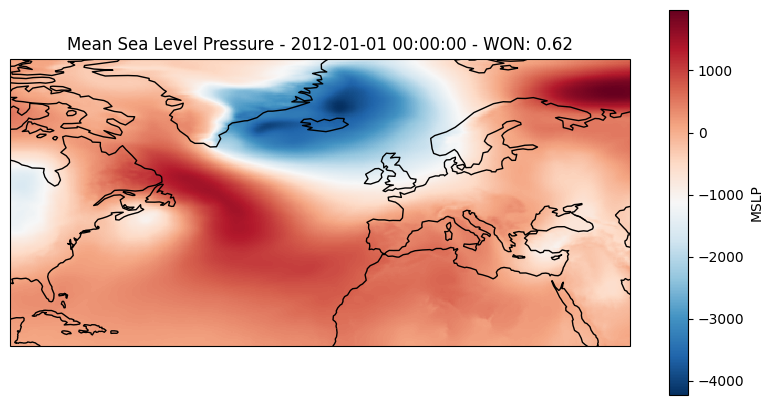

2012-01-02 00:00:00


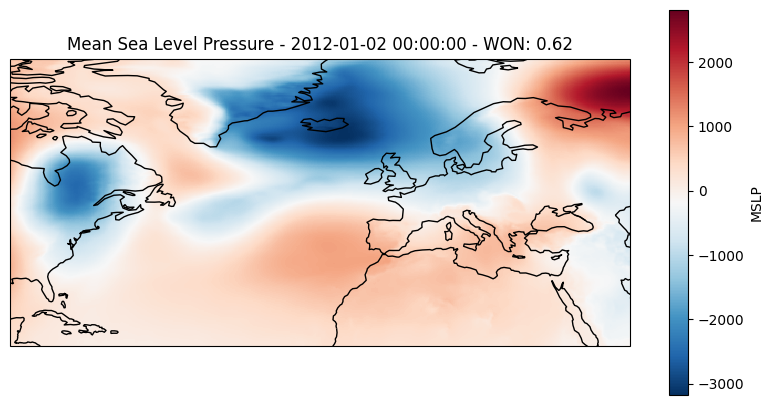

2012-01-06 00:00:00


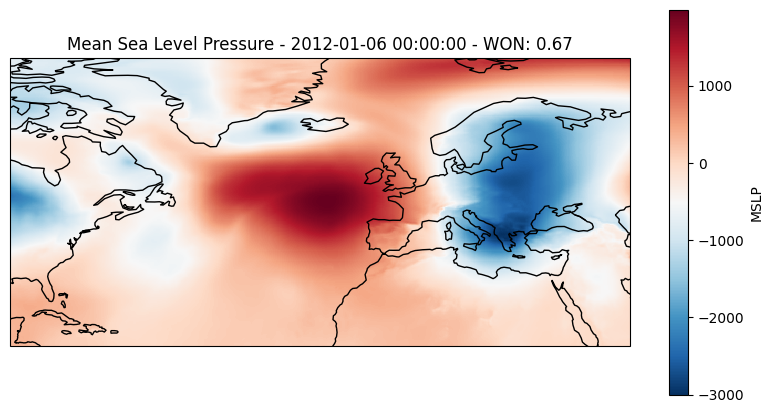

2012-01-19 00:00:00


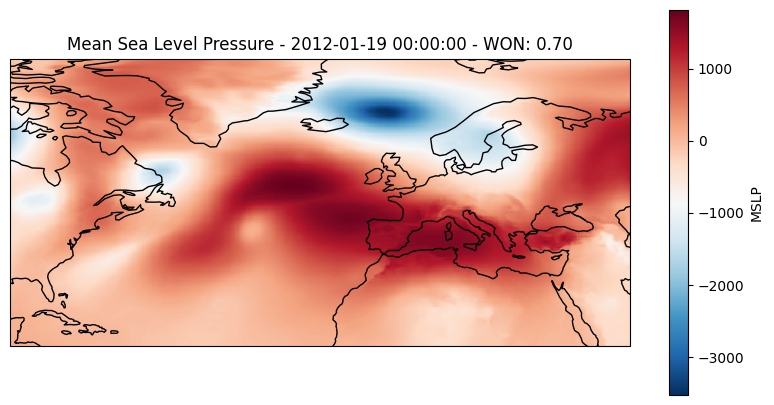

2012-01-20 00:00:00


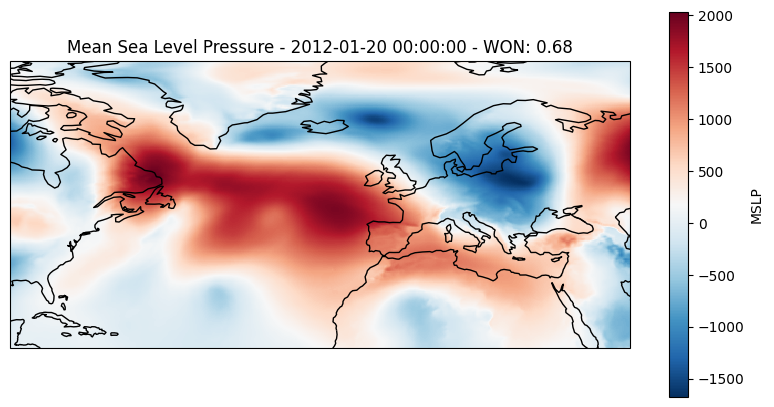

2012-01-21 00:00:00


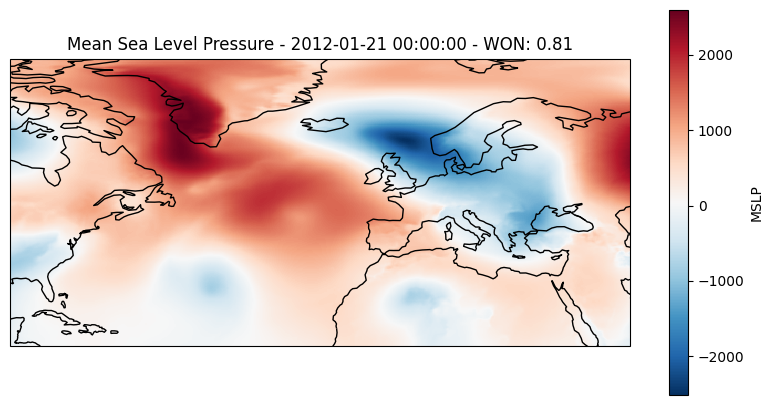

2012-02-15 00:00:00


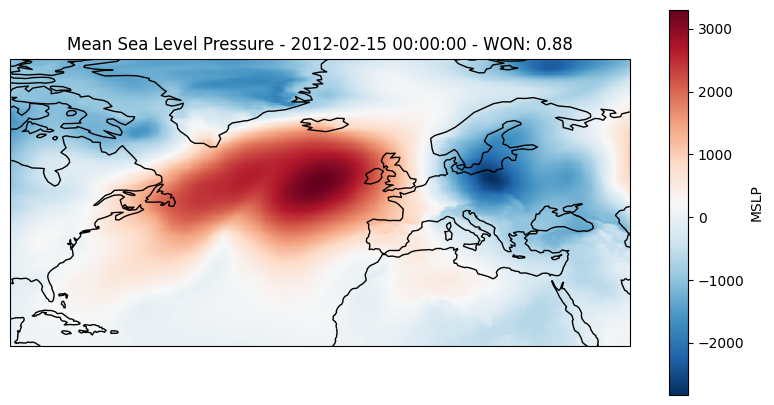

2012-02-16 00:00:00


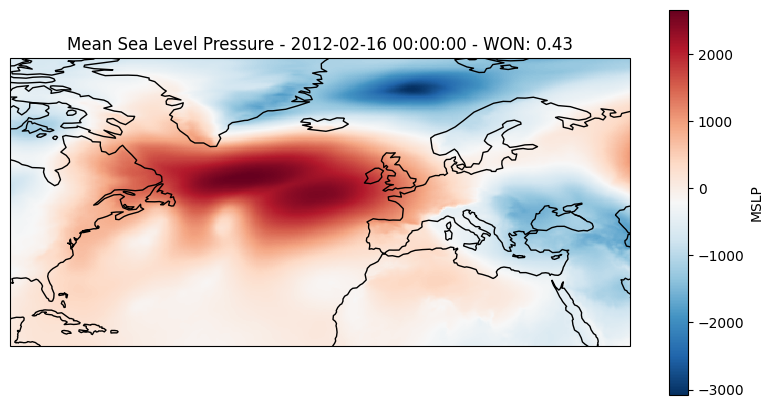

2012-02-17 00:00:00


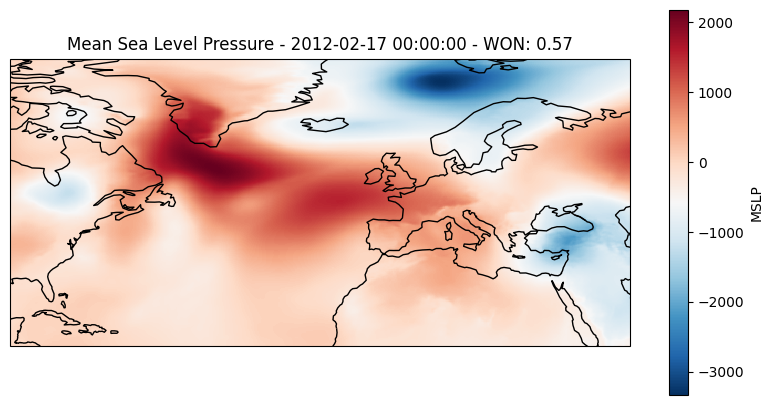

2012-02-18 00:00:00


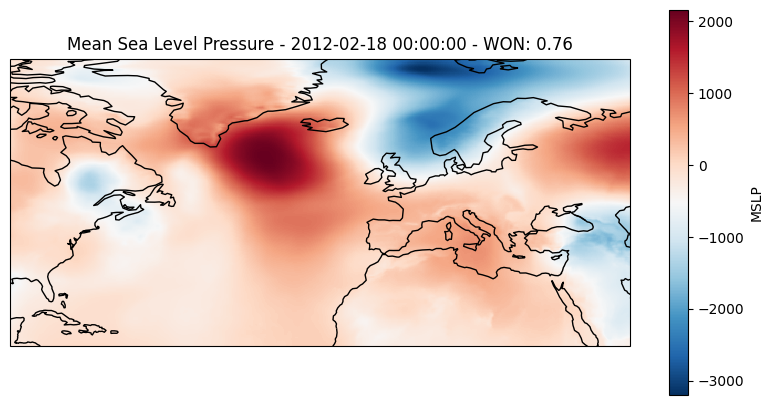

2012-02-21 00:00:00


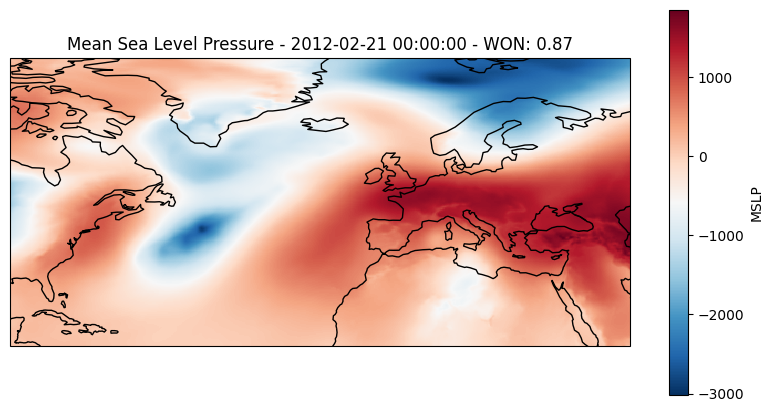

2012-02-22 00:00:00


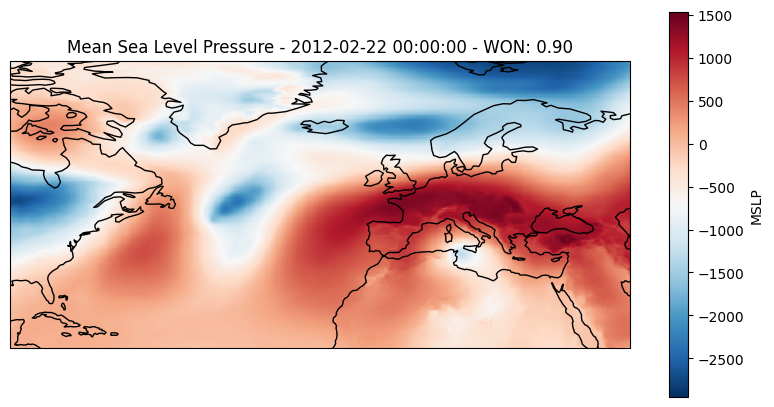

2012-02-23 00:00:00


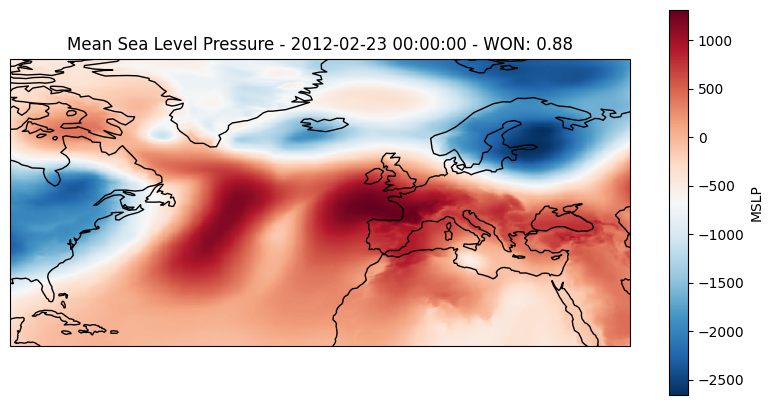

2012-02-25 00:00:00


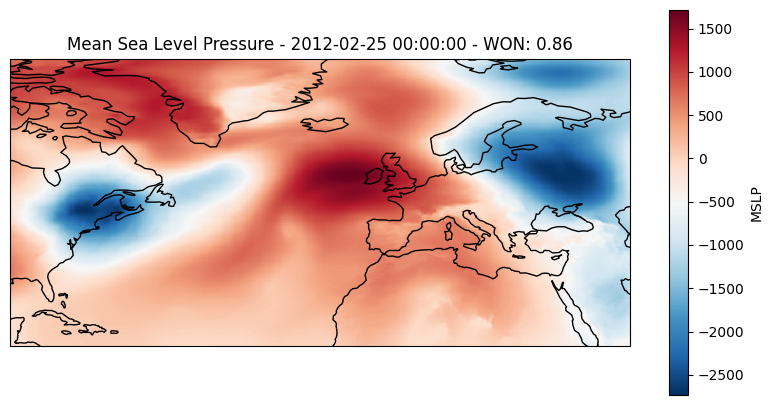

2012-02-28 00:00:00


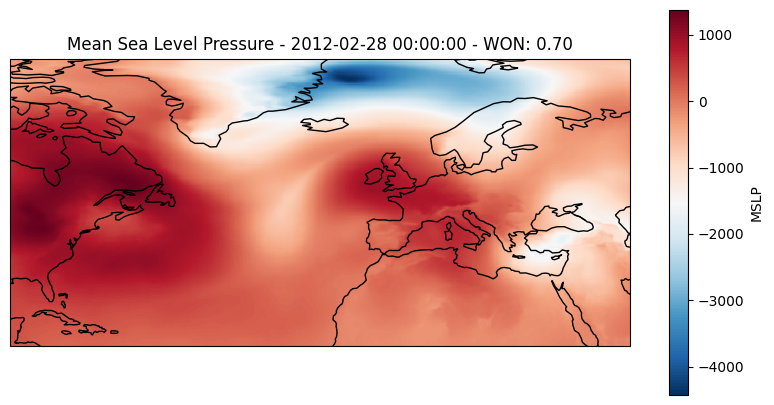

2012-12-25 00:00:00


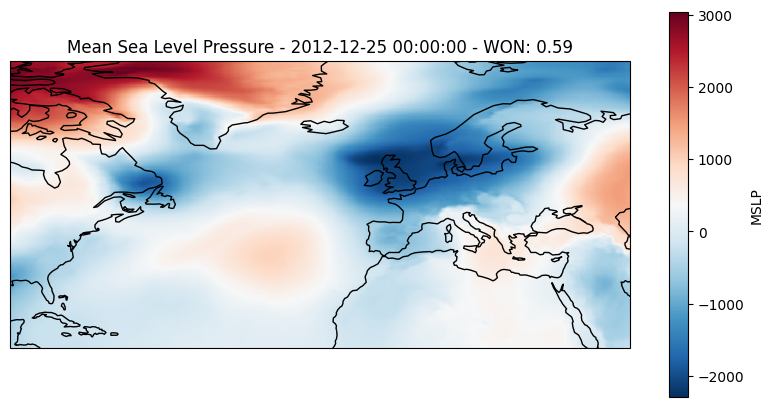

2012-12-26 00:00:00


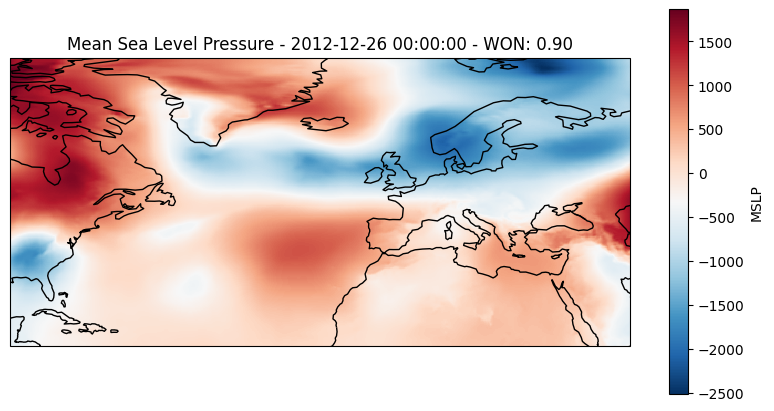

2012-12-27 00:00:00


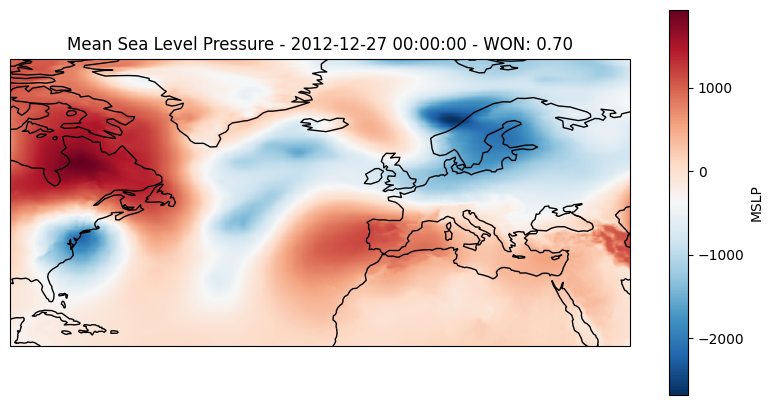

2012-12-28 00:00:00


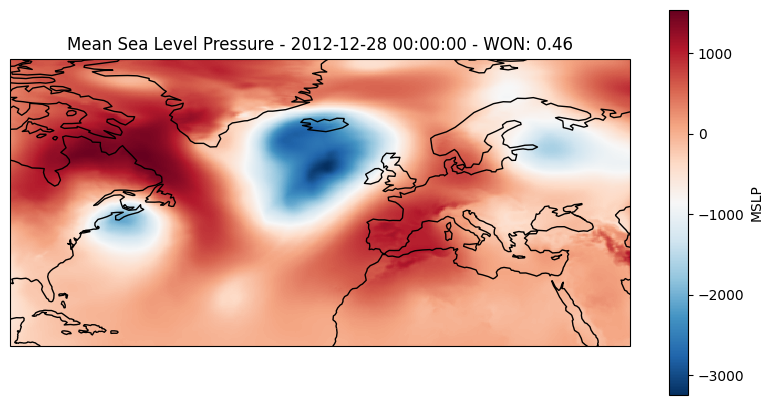

2012-12-29 00:00:00


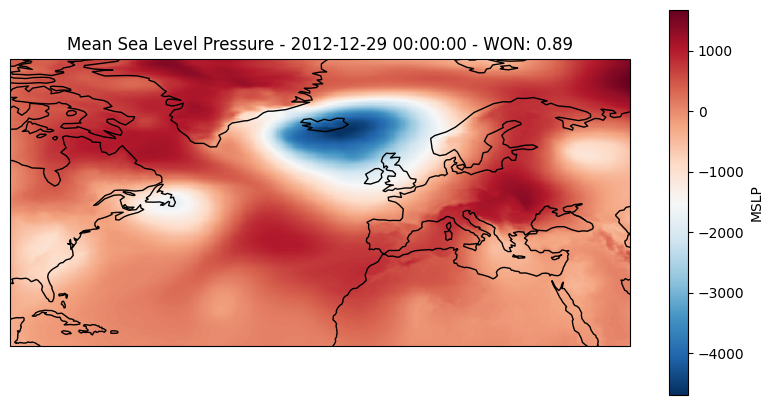

2013-01-01 00:00:00


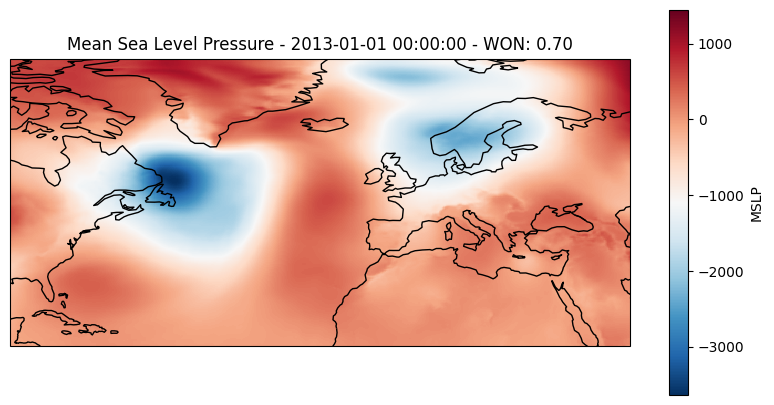

2013-01-27 00:00:00


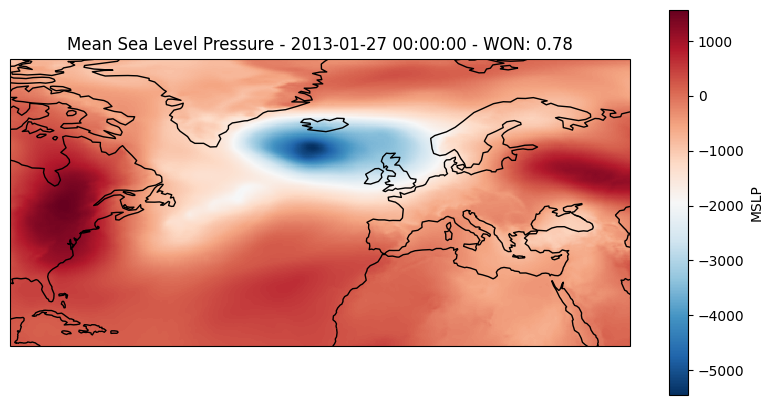

2013-01-28 00:00:00


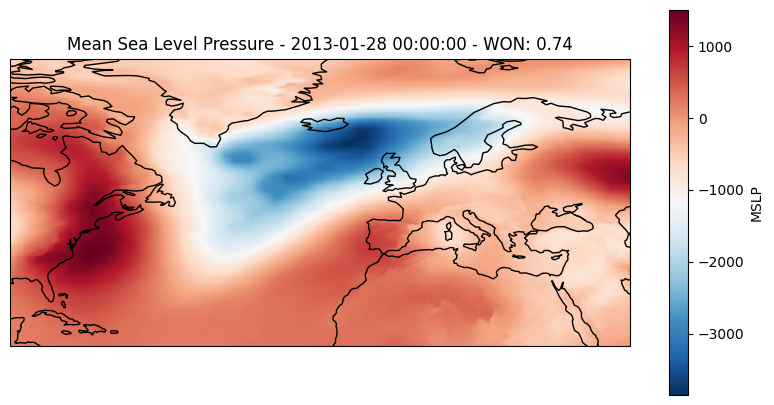

2013-01-29 00:00:00


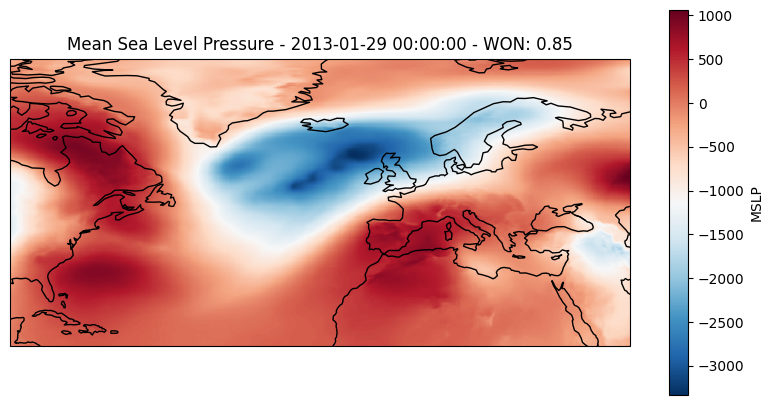

2013-02-01 00:00:00


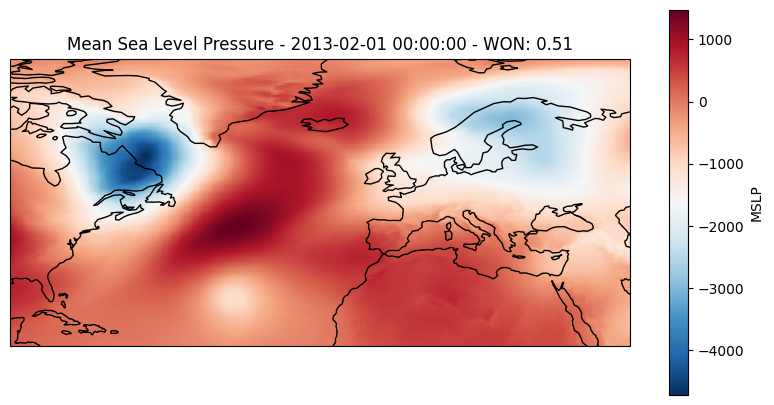

2013-02-02 00:00:00


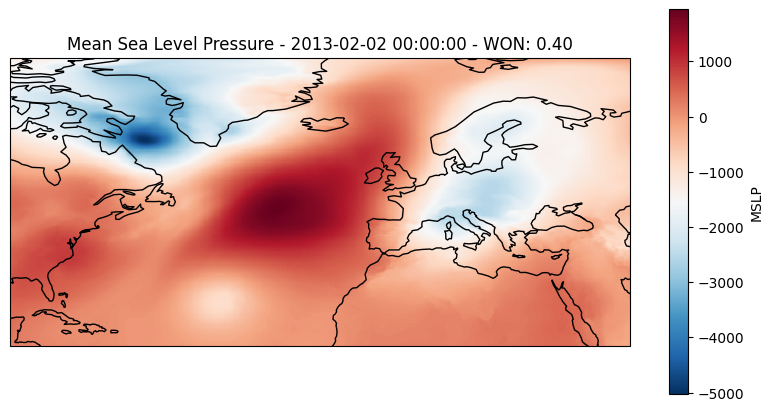

2013-02-03 00:00:00


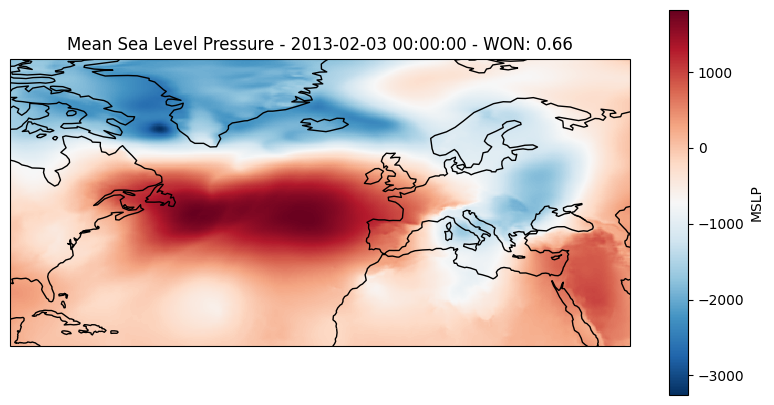

2013-02-04 00:00:00


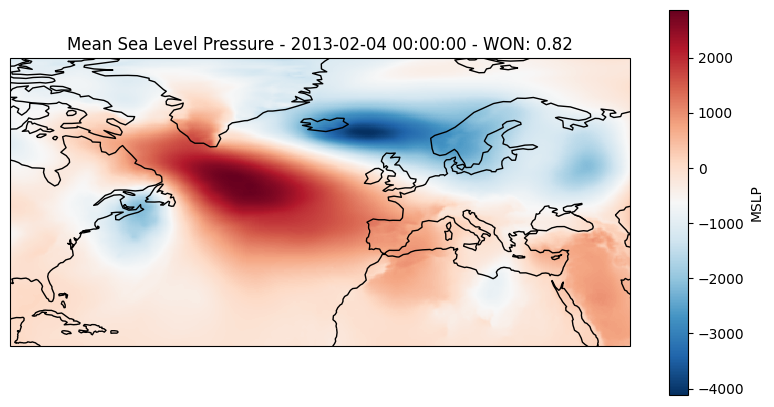

2013-02-05 00:00:00


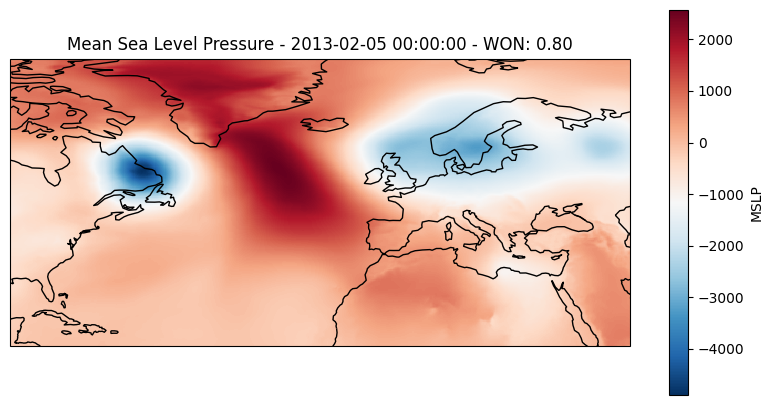

2013-12-03 00:00:00


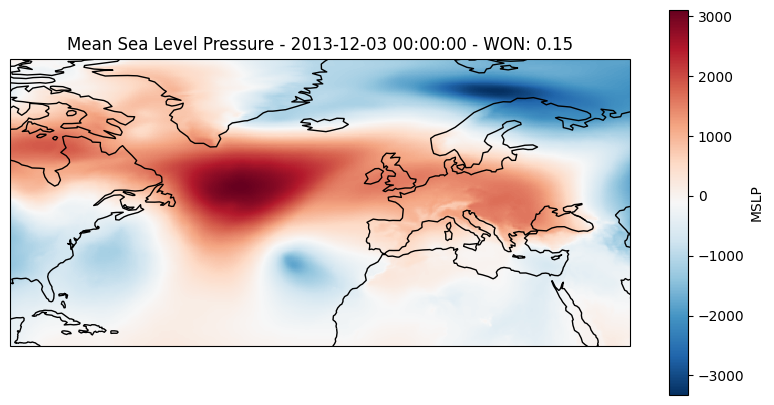

2013-12-04 00:00:00


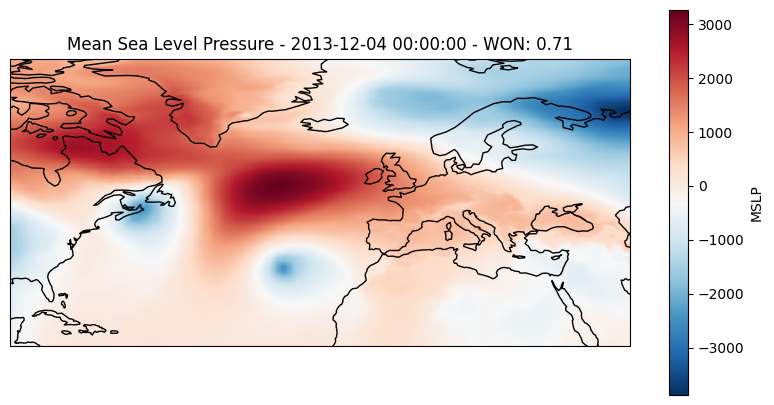

2013-12-15 00:00:00


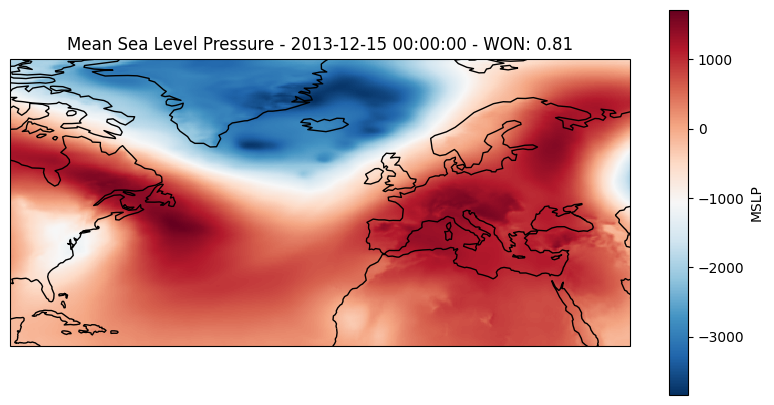

2013-12-16 00:00:00


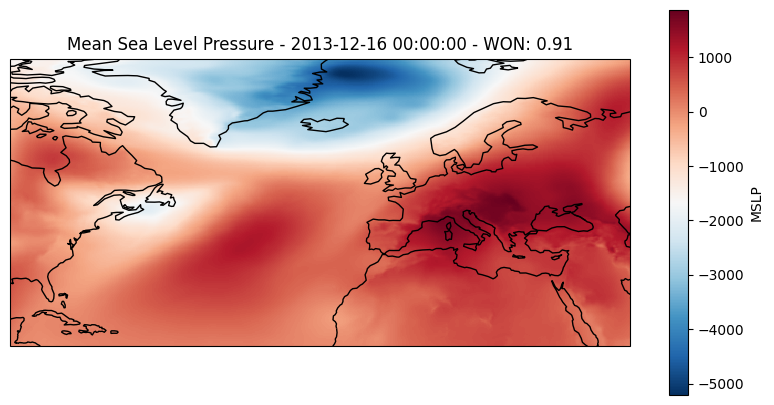

2013-12-17 00:00:00


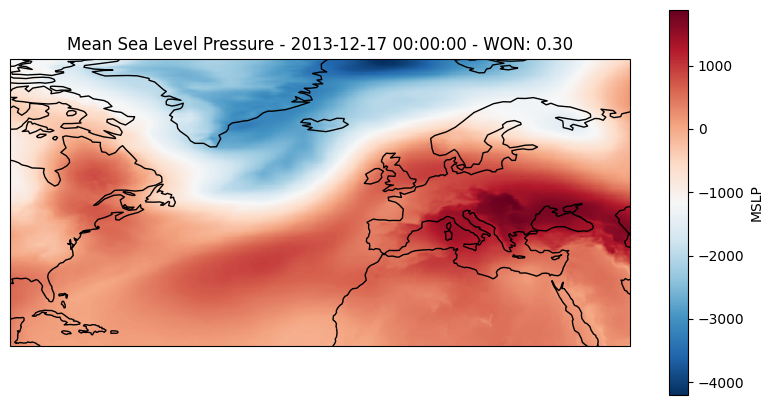

2013-12-18 00:00:00


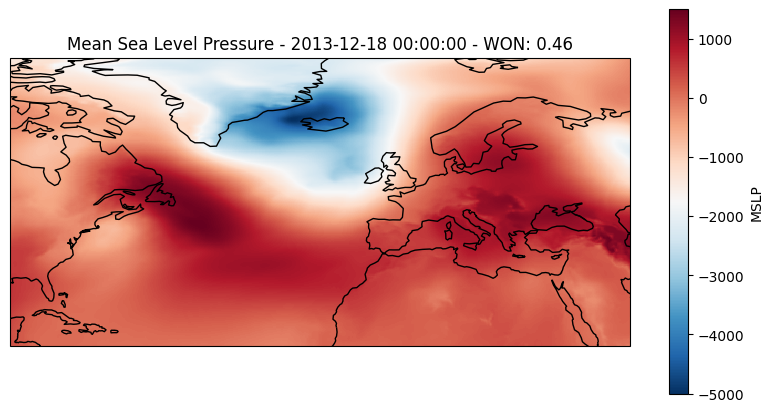

2013-12-19 00:00:00


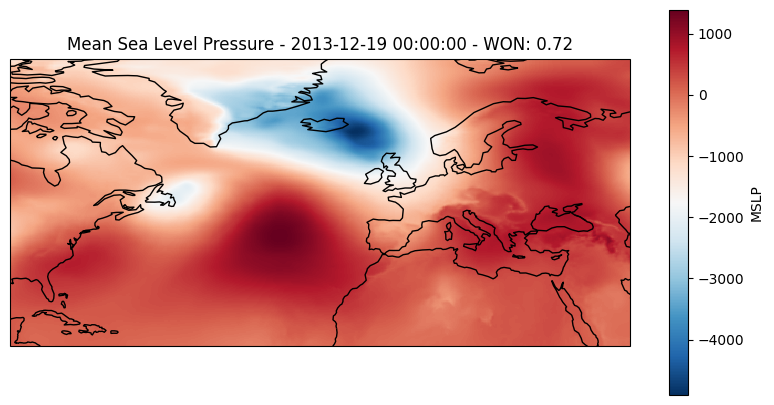

2013-12-20 00:00:00


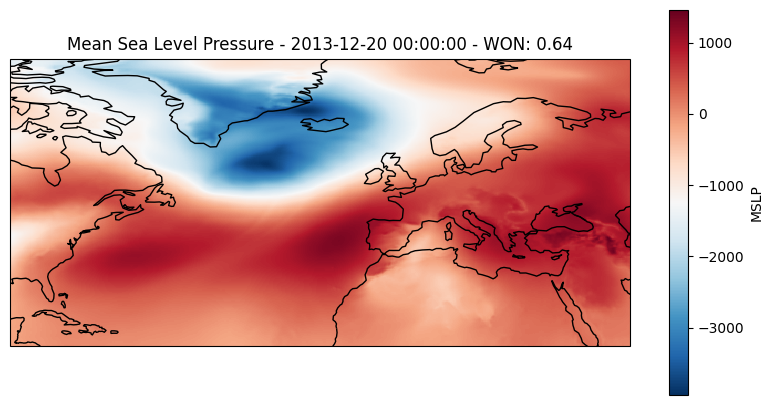

2013-12-23 00:00:00


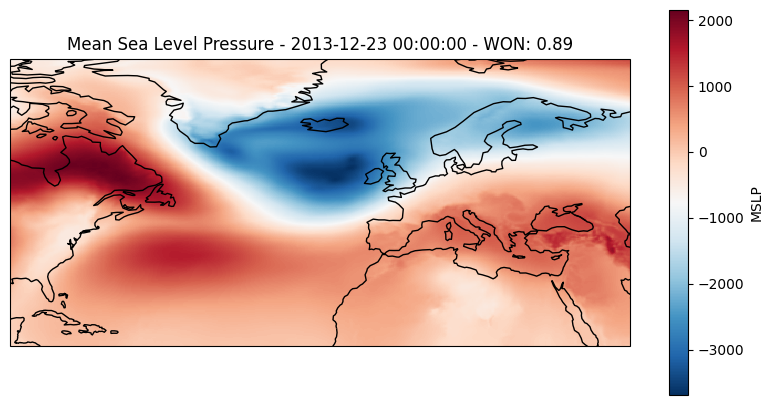

2013-12-25 00:00:00


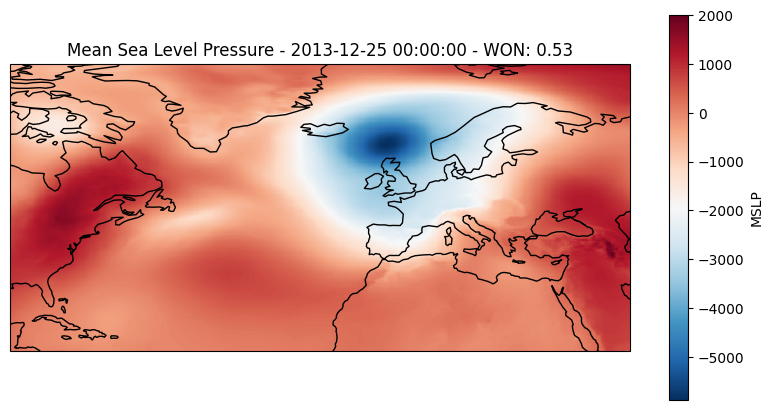

2013-12-26 00:00:00


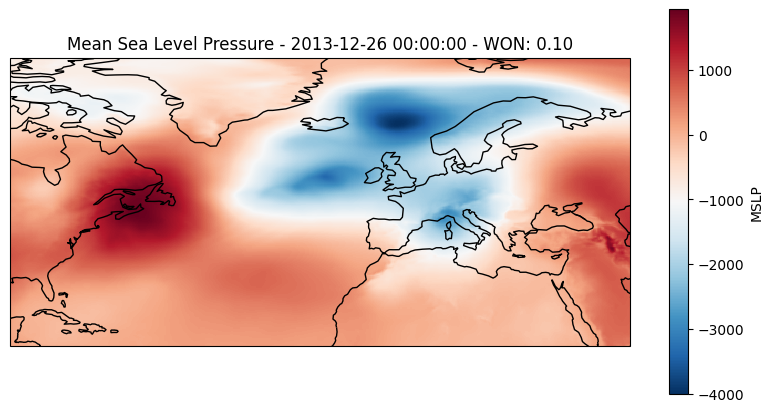

2013-12-27 00:00:00


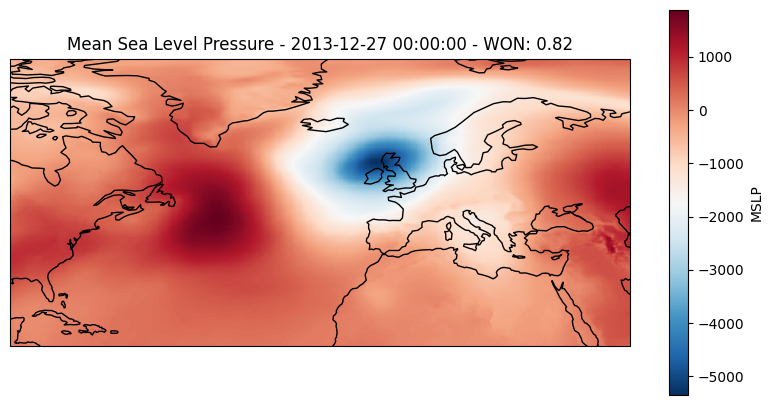

2013-12-28 00:00:00


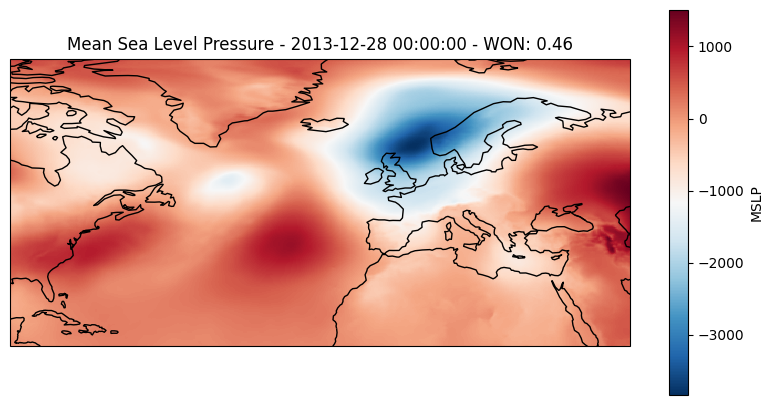

2013-12-29 00:00:00


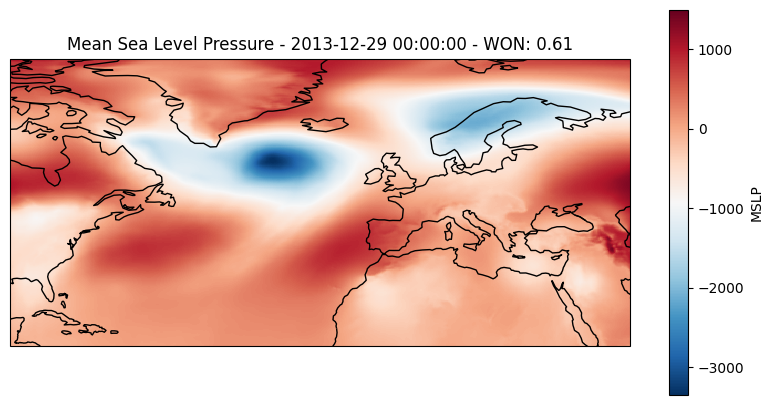

2014-01-06 00:00:00


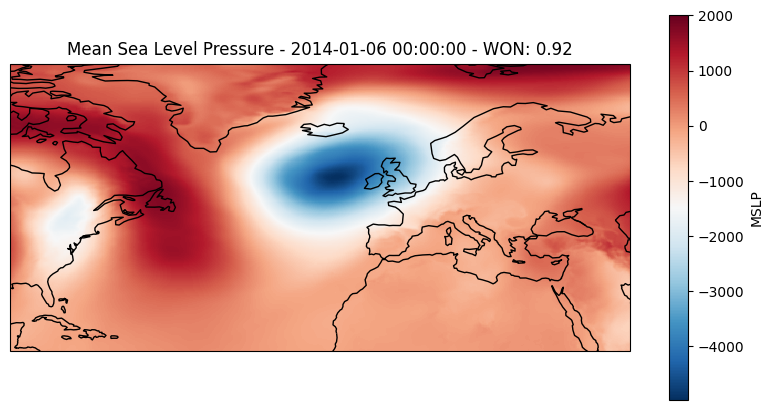

2014-02-08 00:00:00


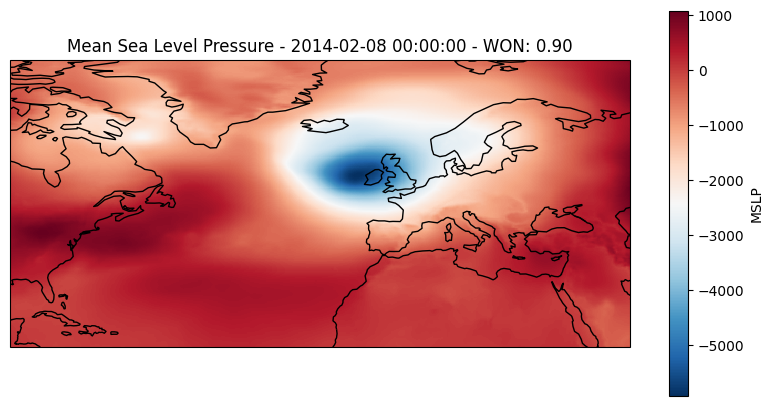

2014-02-10 00:00:00


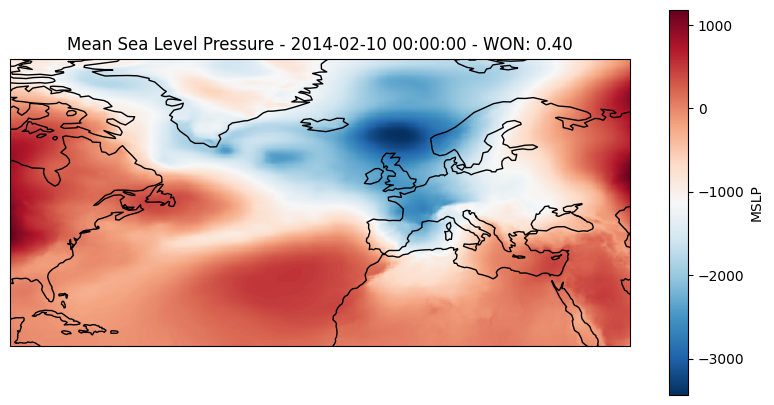

2014-02-11 00:00:00


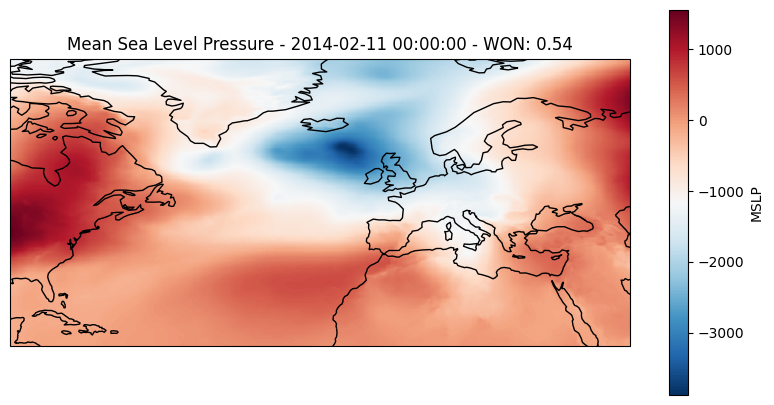

2014-02-12 00:00:00


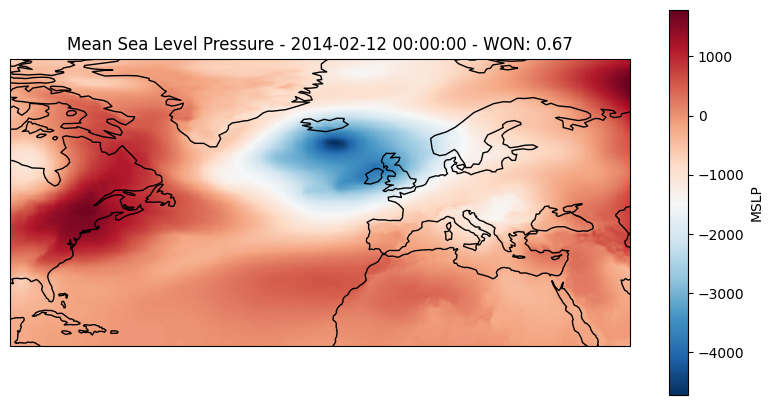

2014-02-13 00:00:00


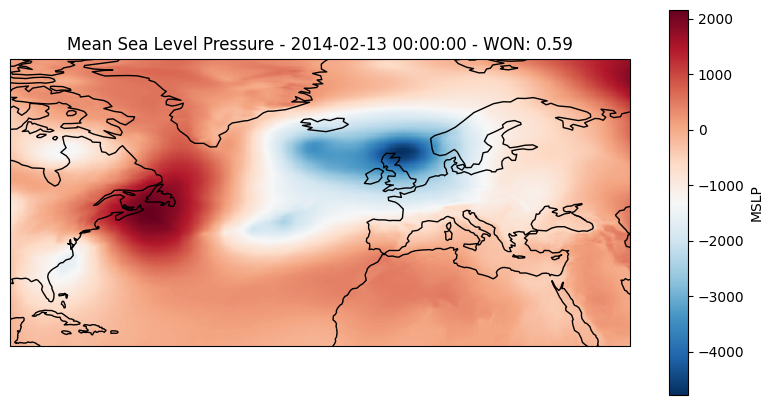

2014-02-14 00:00:00


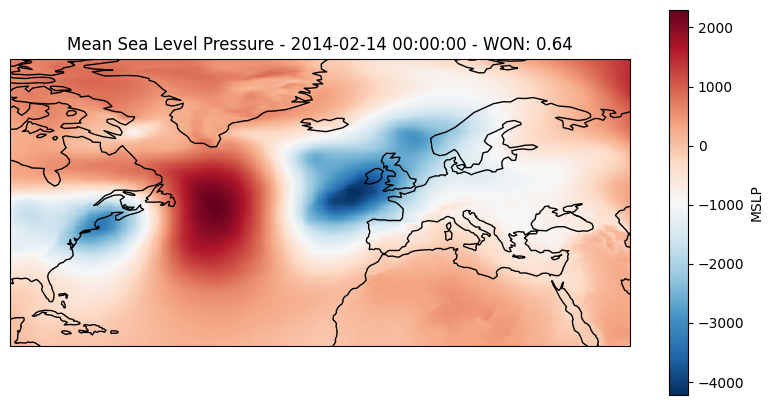

2014-02-16 00:00:00


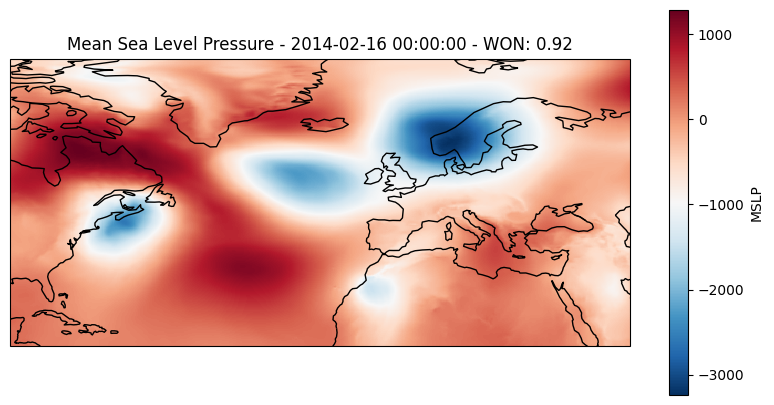

2014-02-20 00:00:00


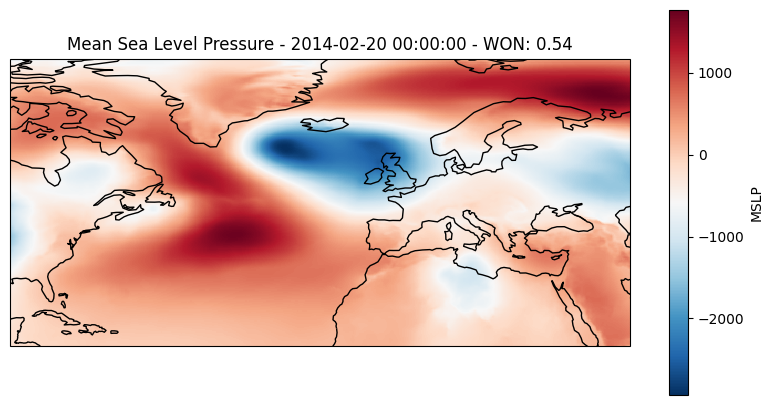

2014-02-21 00:00:00


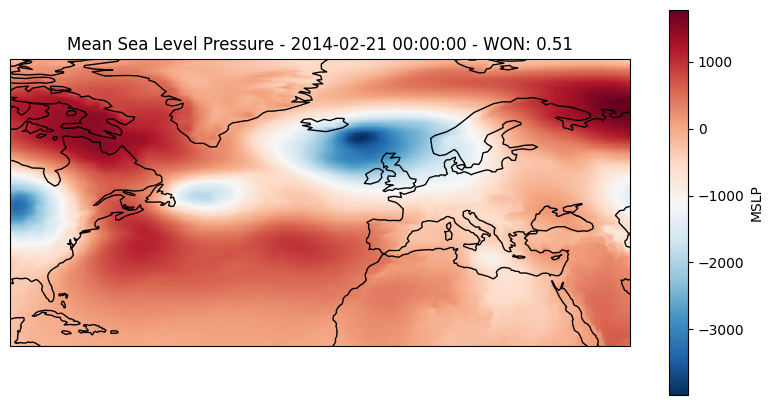

2014-02-22 00:00:00


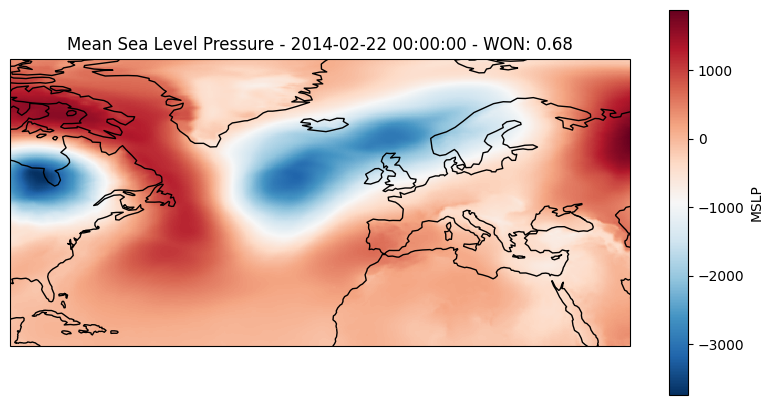

2014-02-23 00:00:00


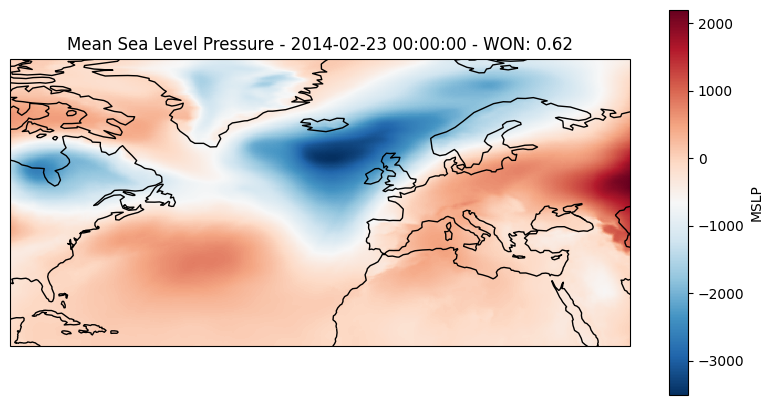

2014-02-24 00:00:00


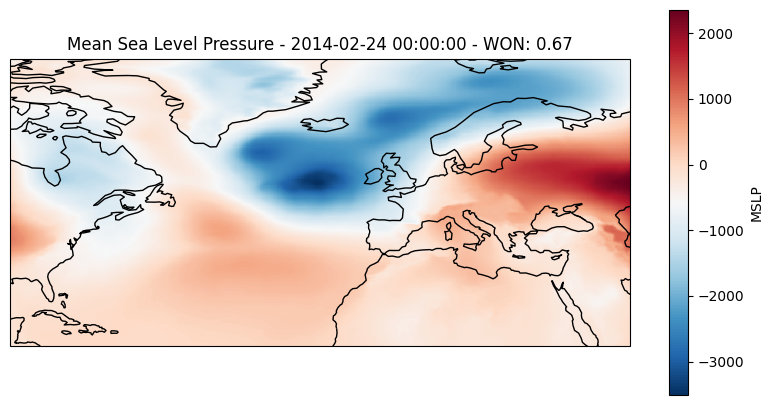

2014-12-06 00:00:00


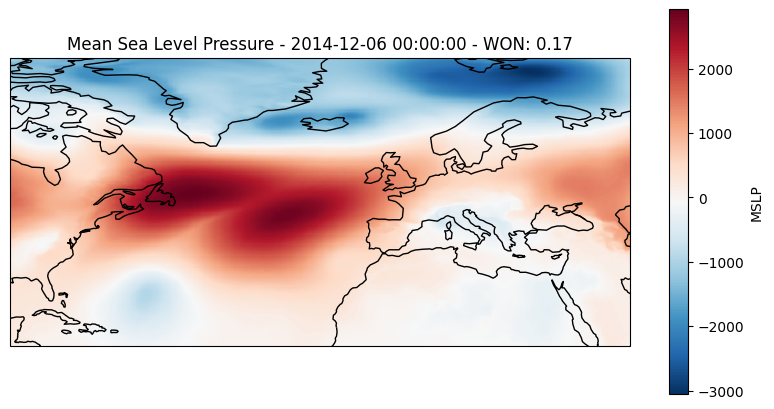

2014-12-07 00:00:00


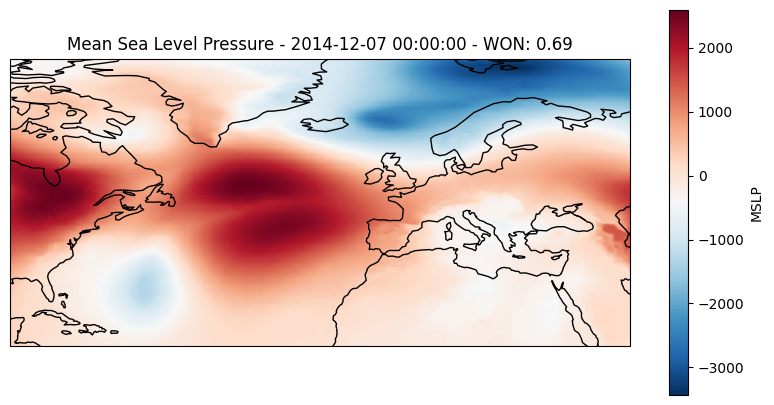

2014-12-08 00:00:00


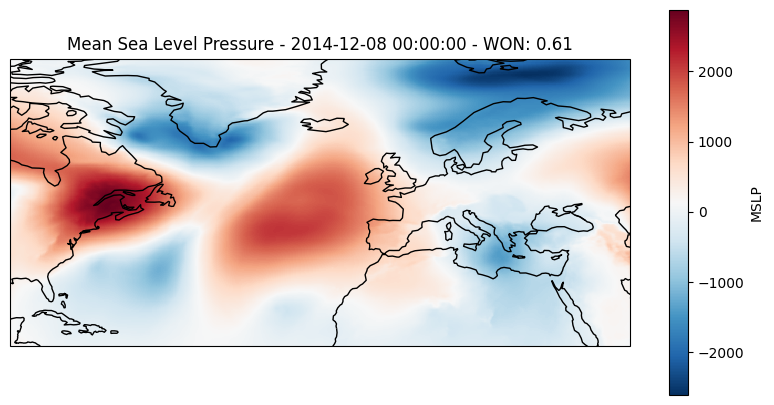

2014-12-09 00:00:00


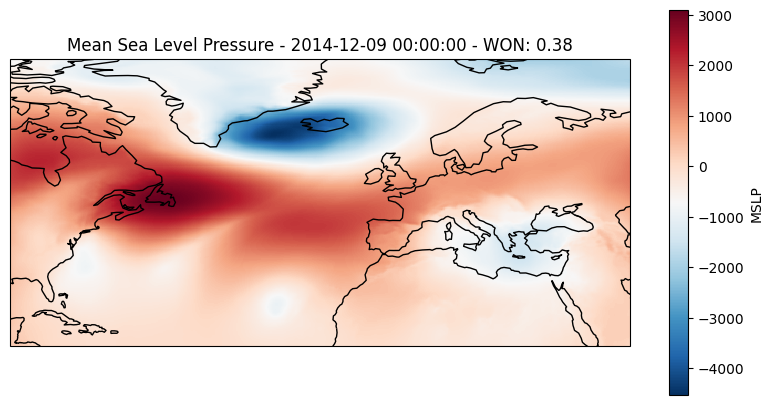

2014-12-13 00:00:00


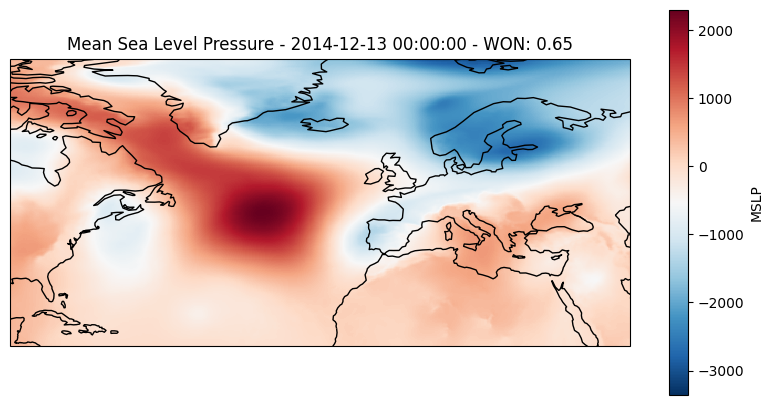

2014-12-14 00:00:00


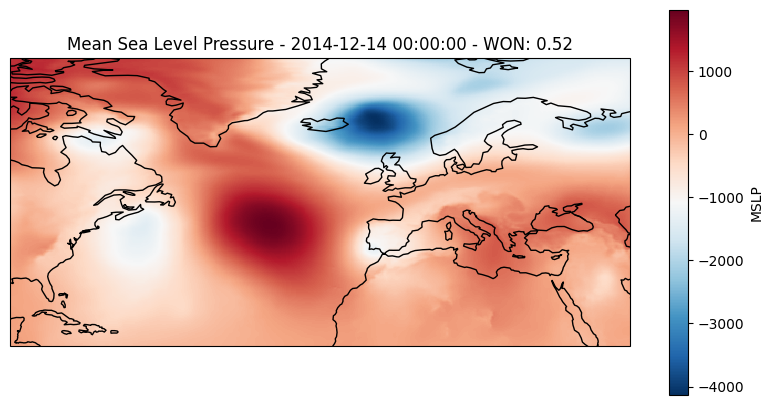

2014-12-15 00:00:00


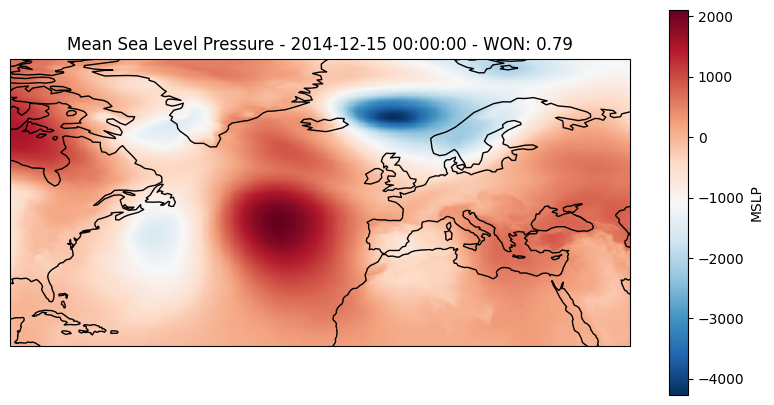

2014-12-16 00:00:00


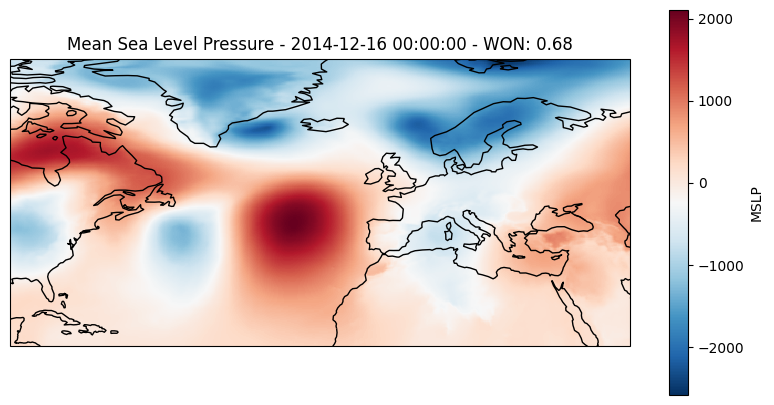

2014-12-17 00:00:00


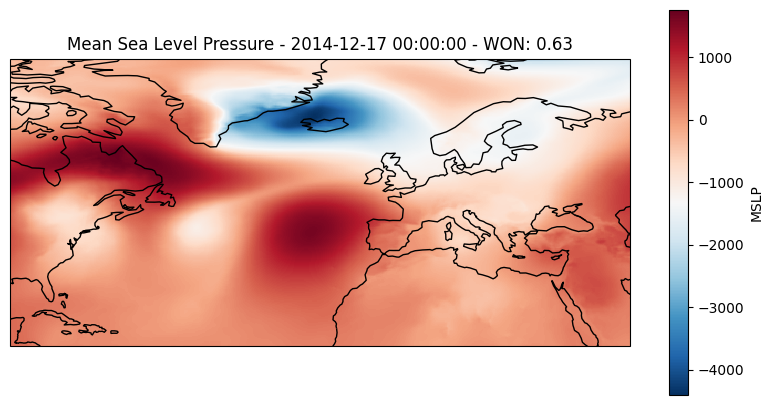

2014-12-18 00:00:00


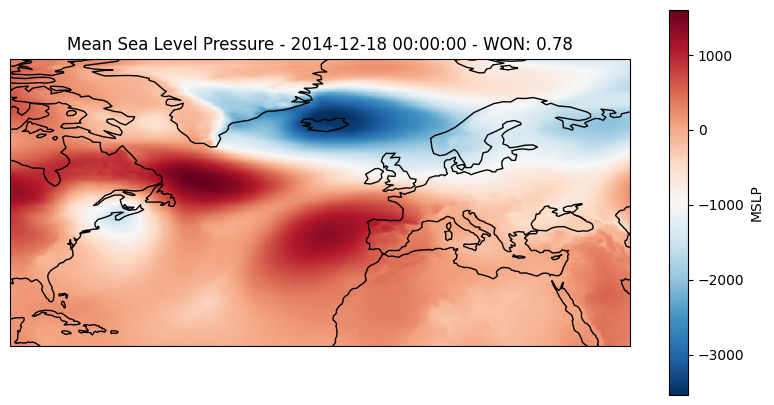

2015-01-01 00:00:00


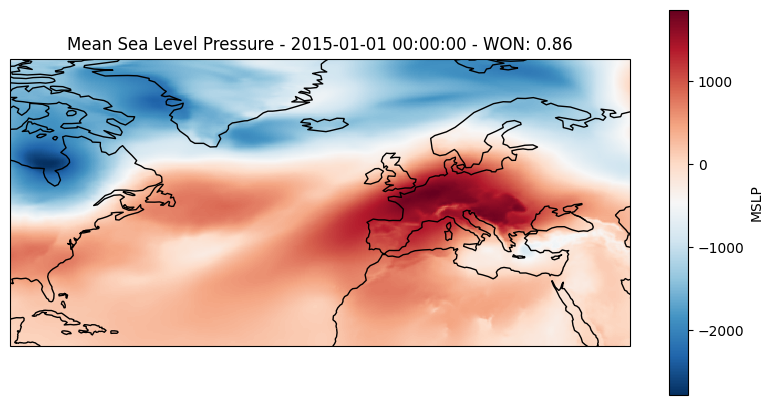

2015-01-03 00:00:00


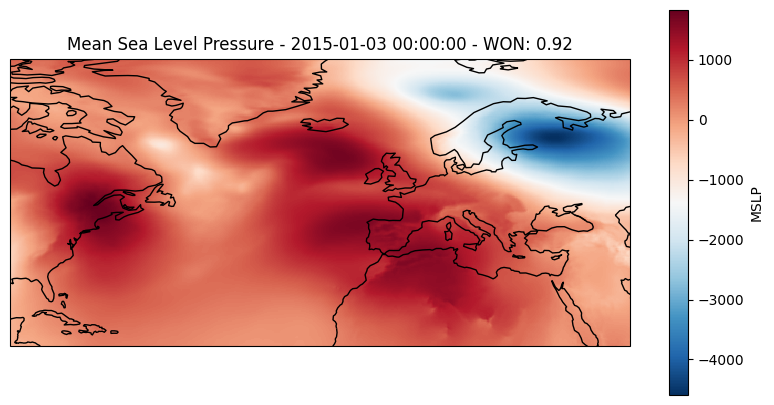

2015-01-04 00:00:00


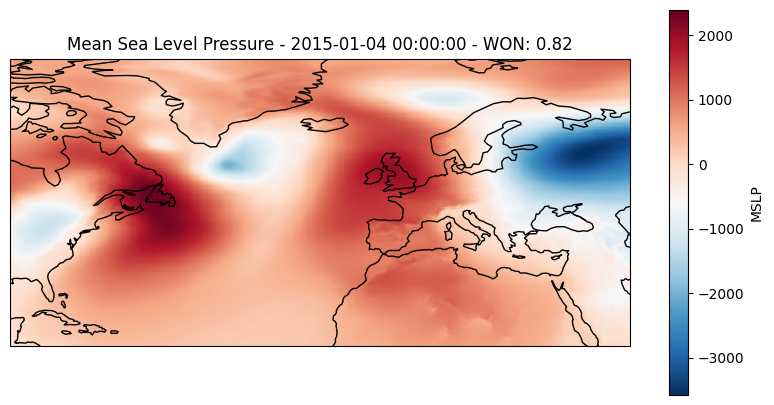

2015-01-08 00:00:00


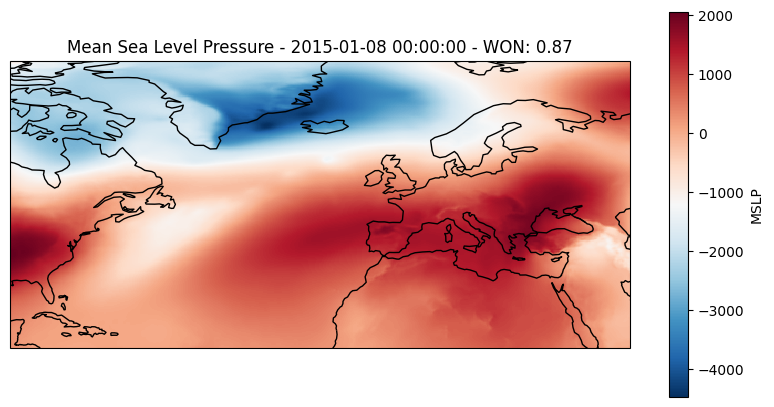

2015-01-10 00:00:00


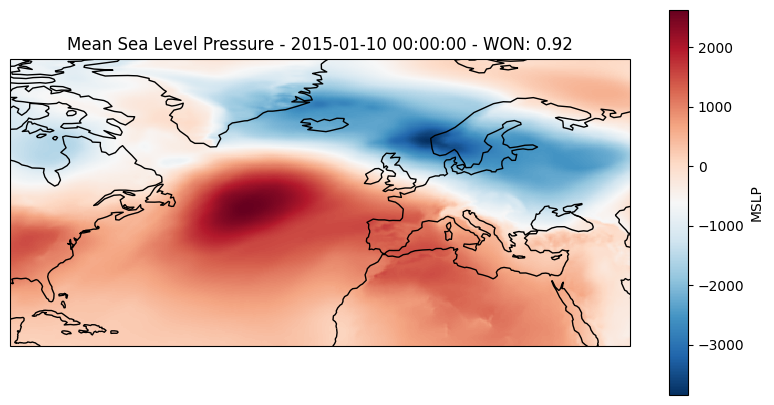

2015-01-13 00:00:00


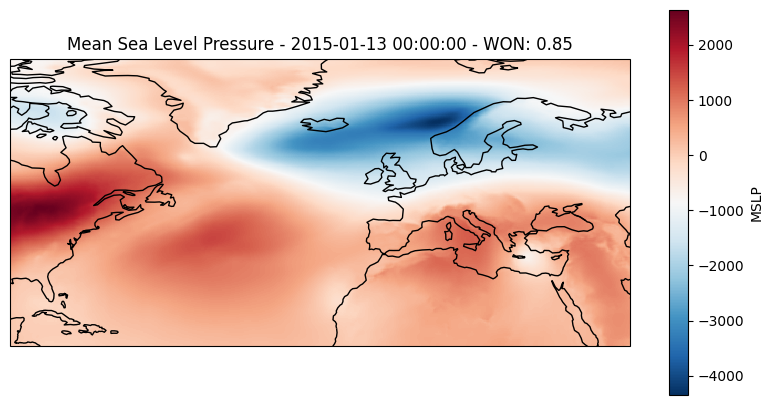

2015-01-14 00:00:00


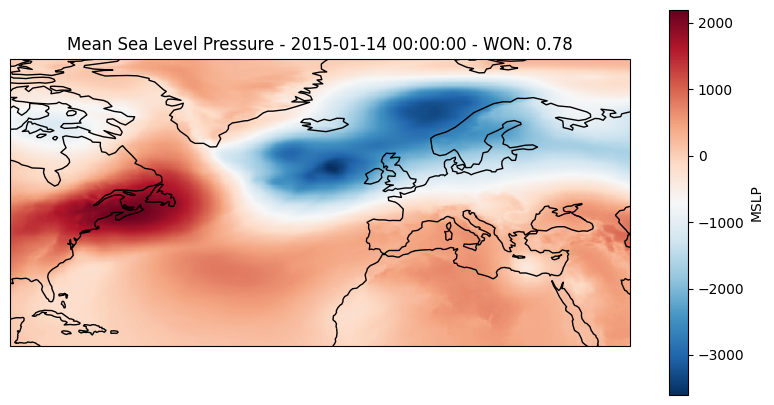

2015-01-16 00:00:00


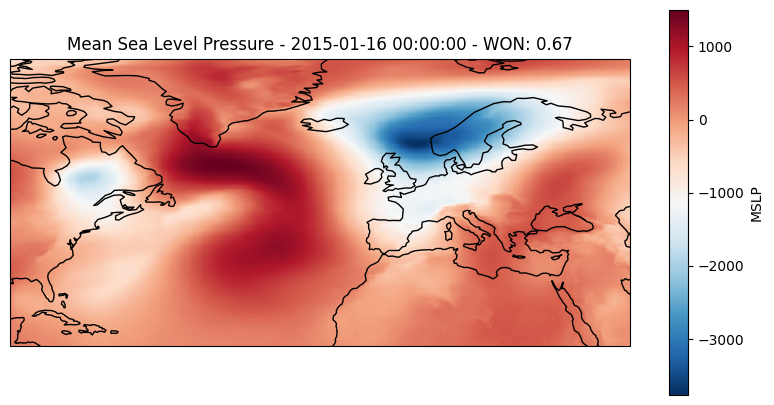

2015-01-17 00:00:00


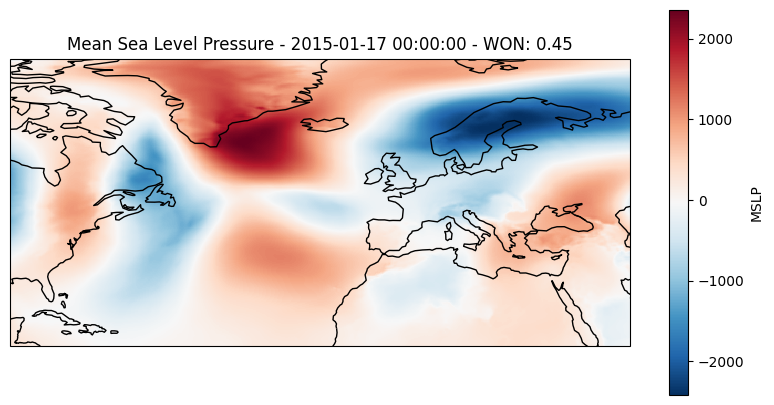

2015-01-27 00:00:00


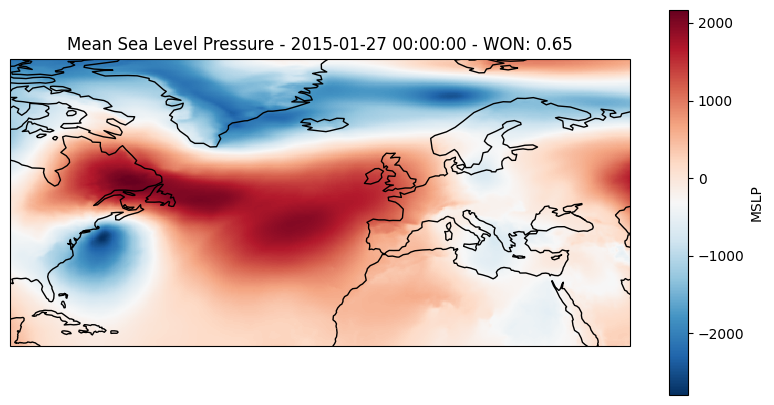

2015-01-28 00:00:00


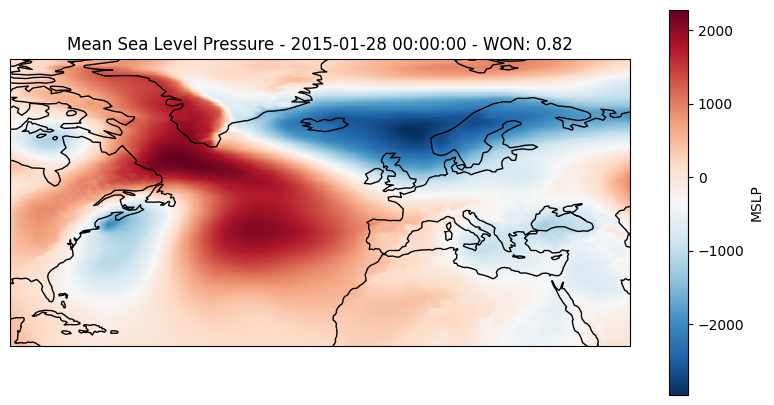

2015-01-29 00:00:00


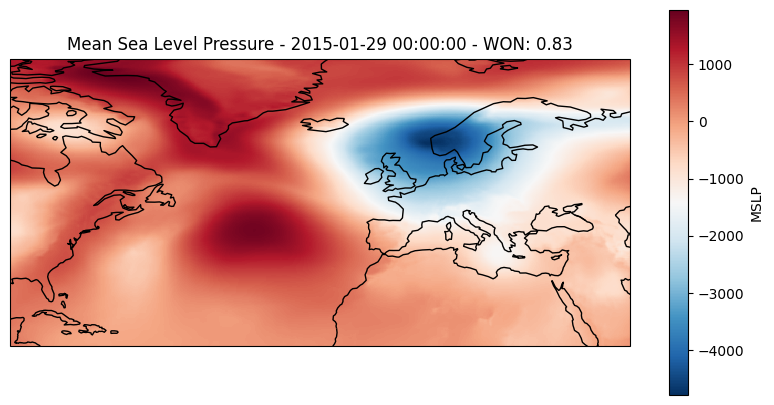

2015-01-30 00:00:00


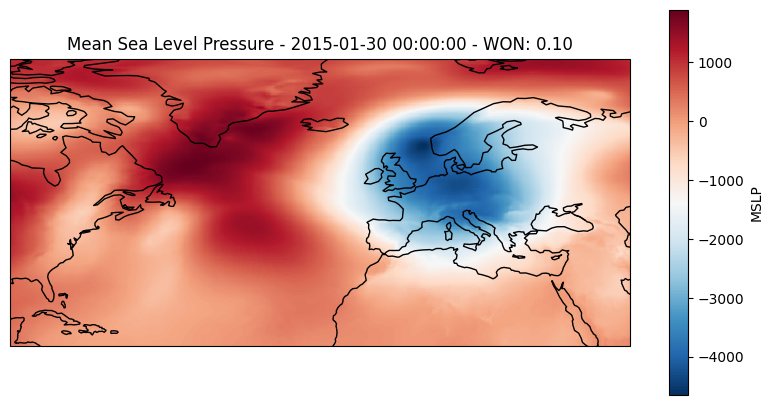

2015-01-31 00:00:00


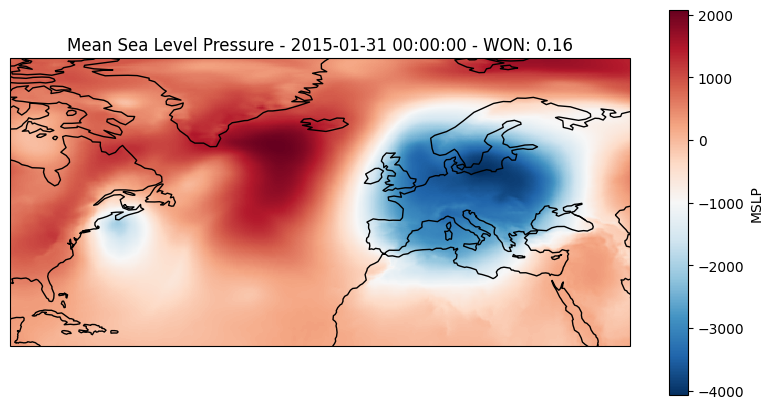

2015-02-01 00:00:00


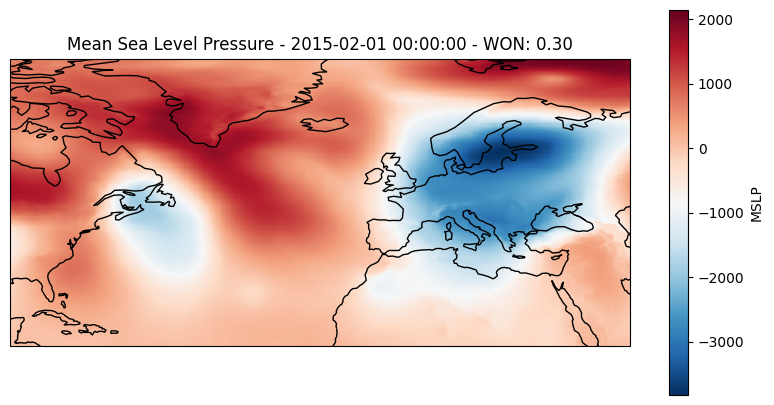

2015-02-09 00:00:00


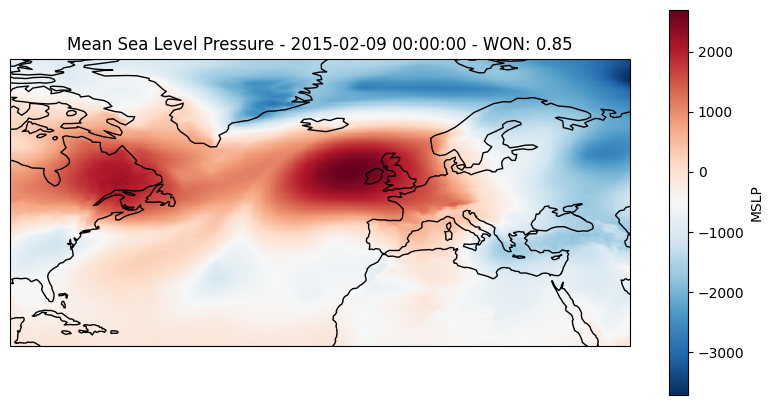

2015-02-10 00:00:00


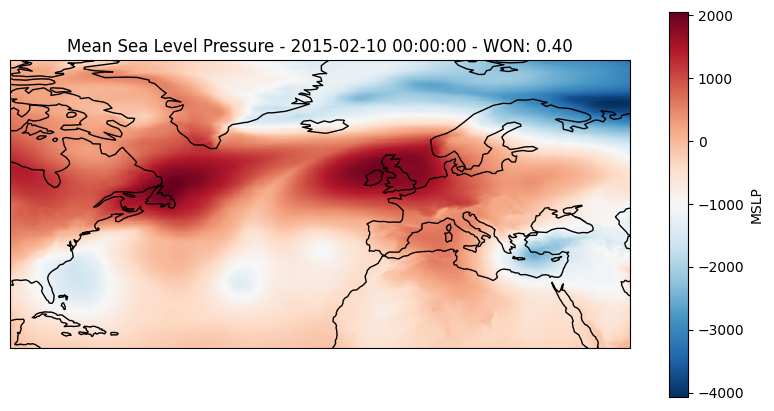

2015-02-19 00:00:00


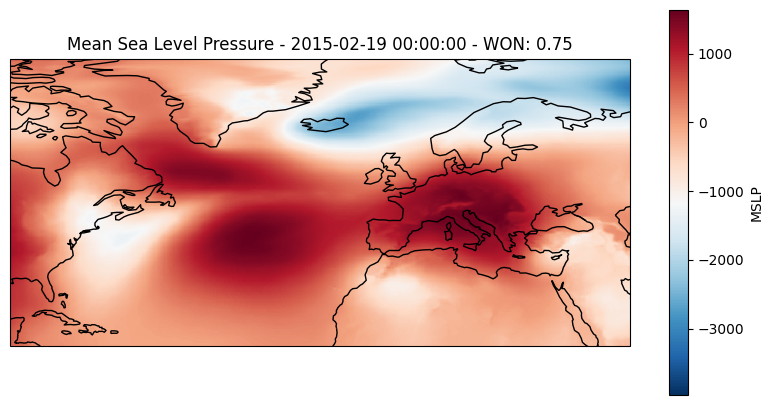

2015-02-20 00:00:00


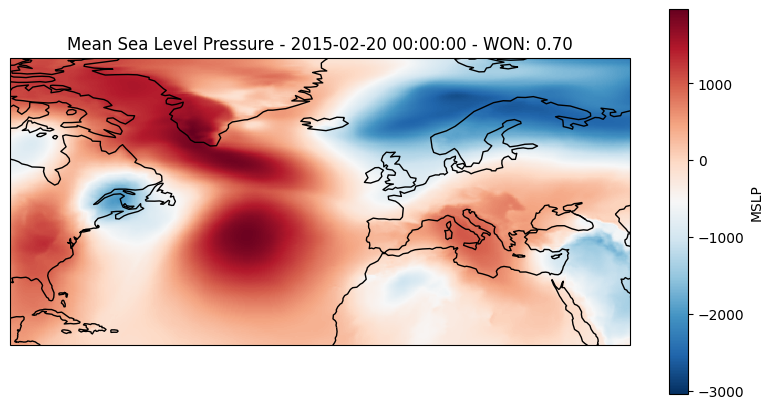

2015-02-21 00:00:00


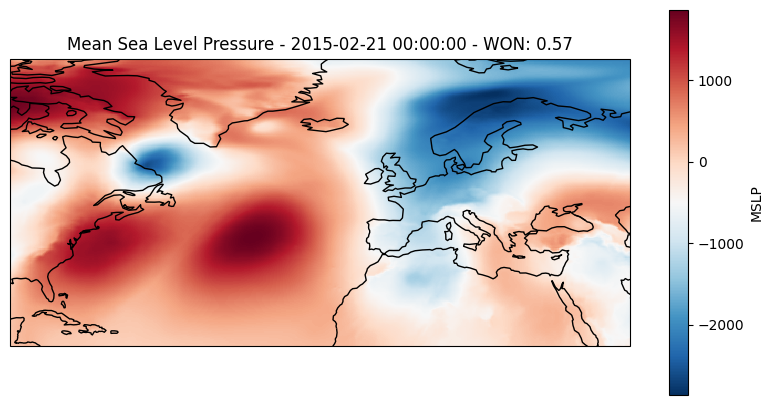

2015-02-22 00:00:00


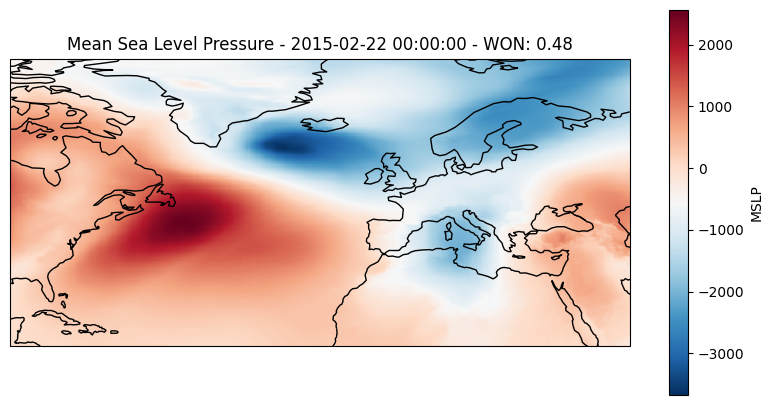

2015-02-23 00:00:00


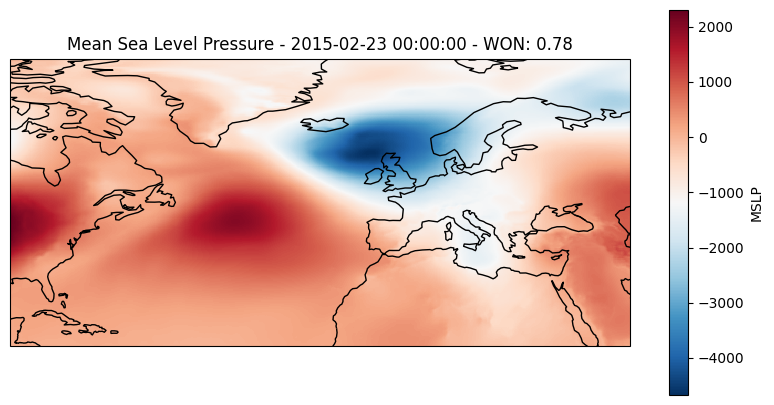

2015-02-24 00:00:00


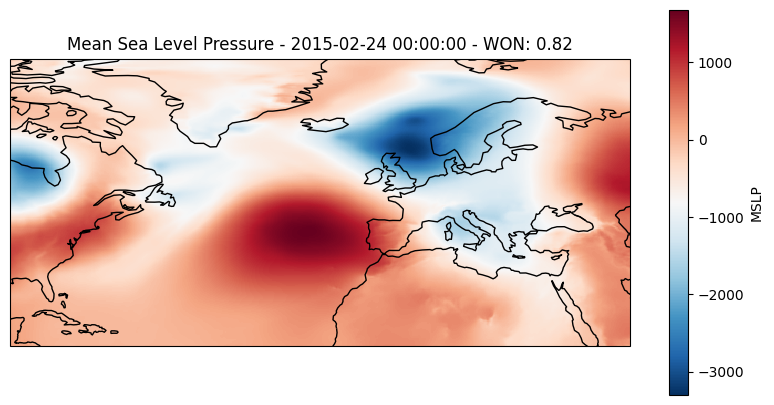

2015-02-25 00:00:00


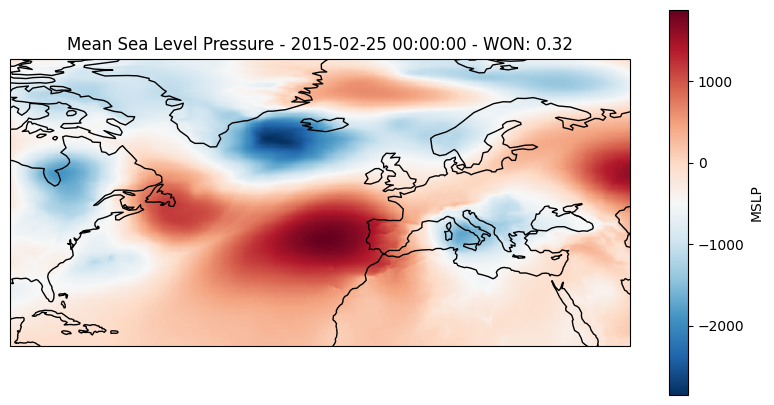

2015-02-28 00:00:00


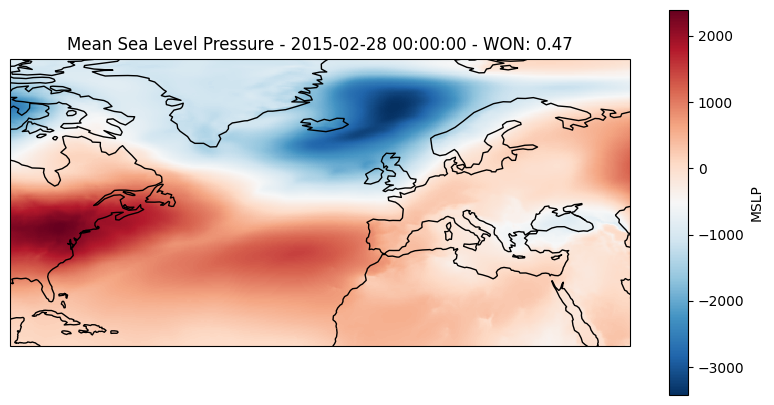

2015-12-01 00:00:00


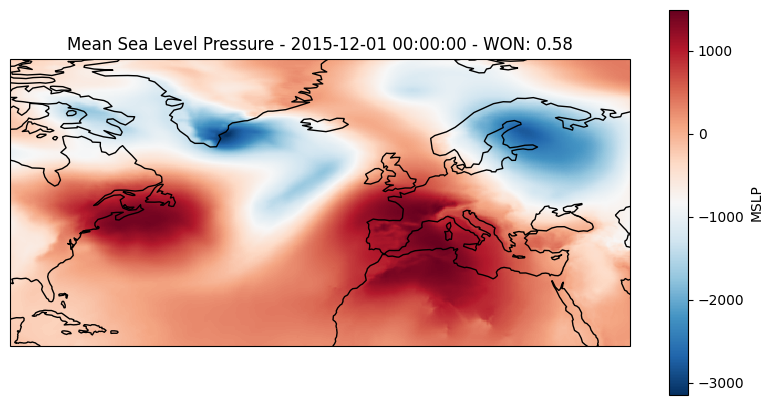

2015-12-02 00:00:00


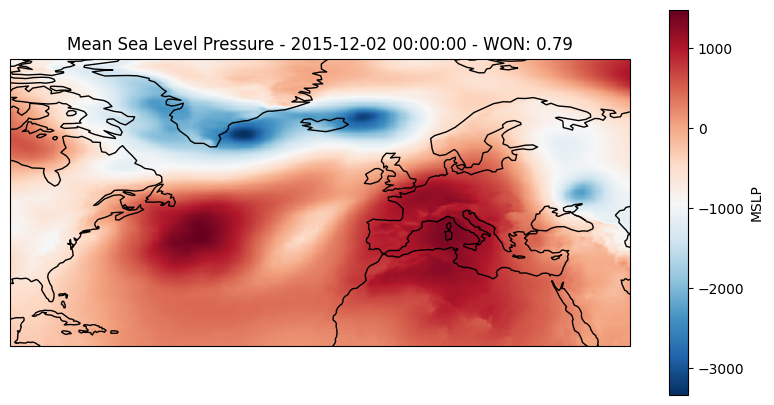

2015-12-03 00:00:00


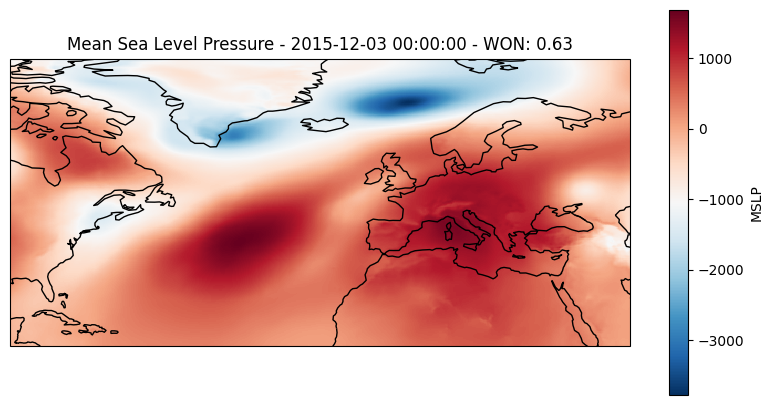

2015-12-07 00:00:00


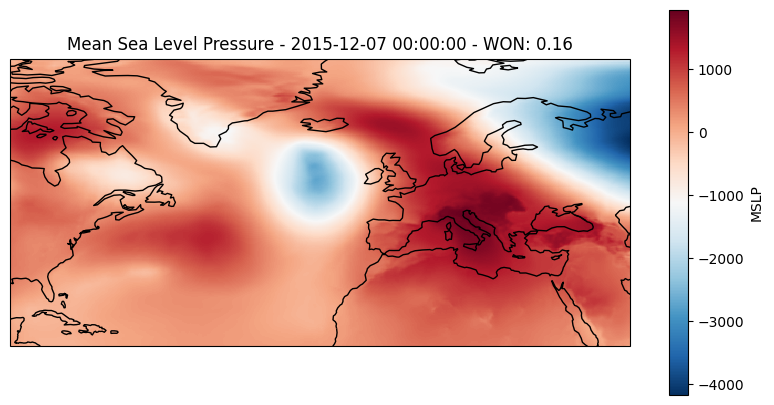

2015-12-18 00:00:00


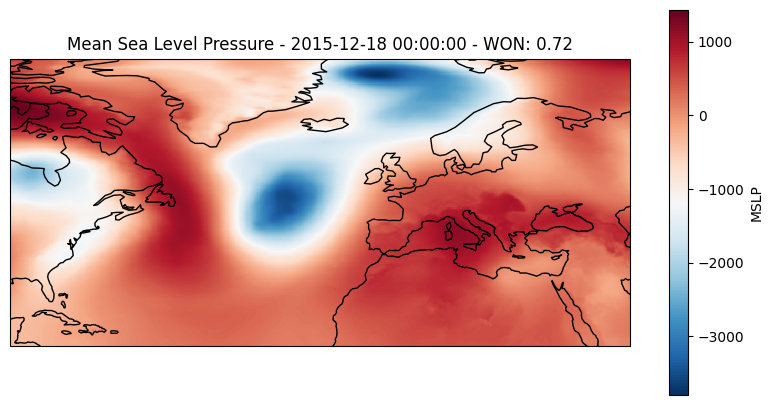

2015-12-19 00:00:00


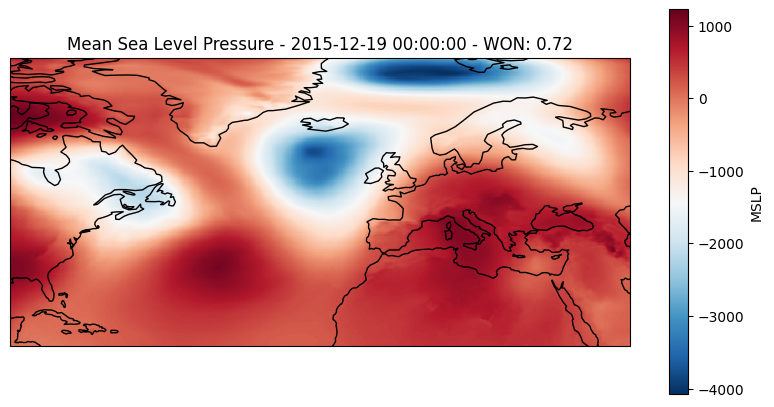

2015-12-20 00:00:00


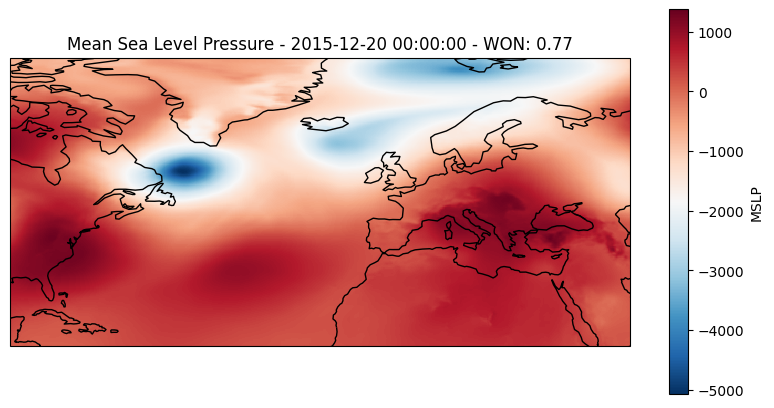

2015-12-21 00:00:00


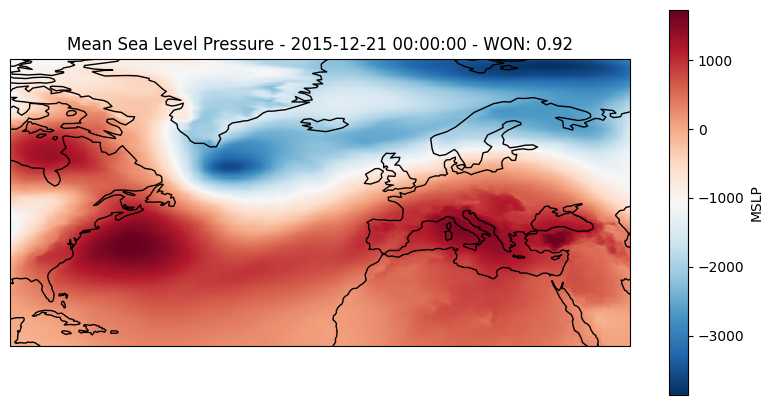

2015-12-23 00:00:00


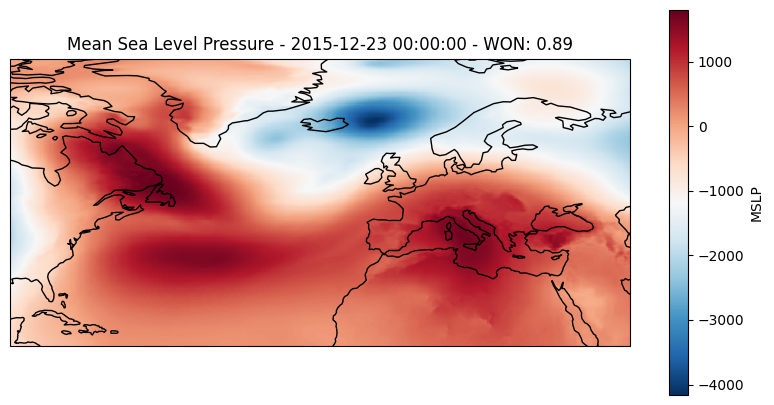

2015-12-24 00:00:00


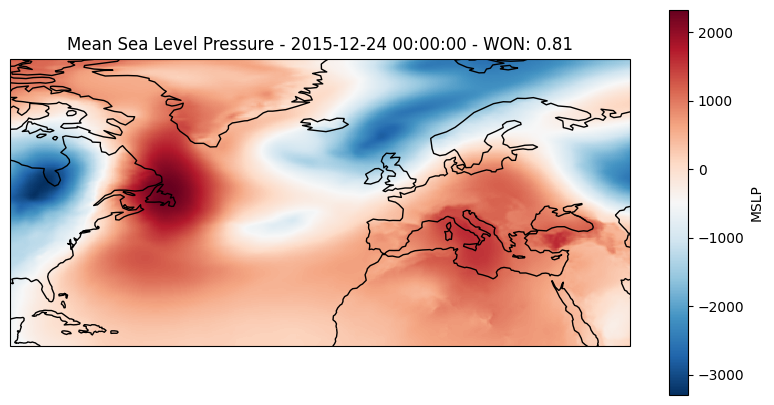

2015-12-25 00:00:00


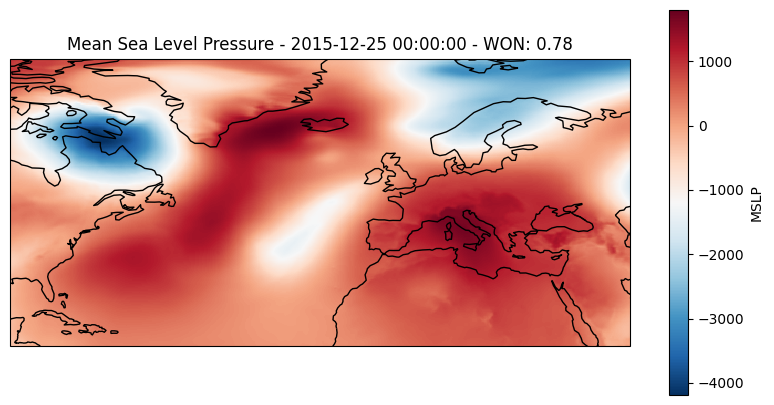

2016-01-26 00:00:00


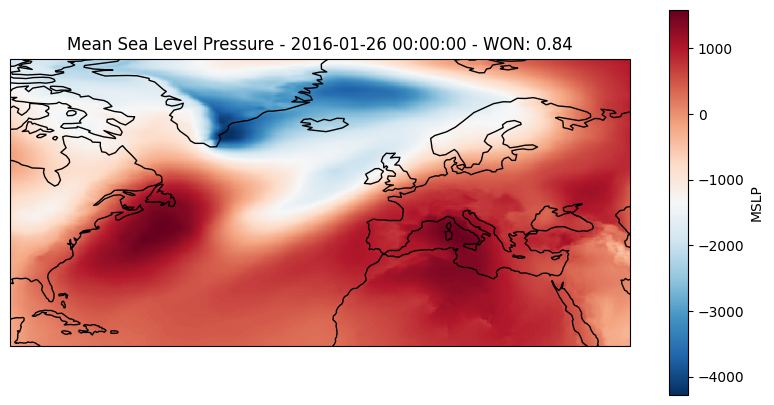

2016-01-28 00:00:00


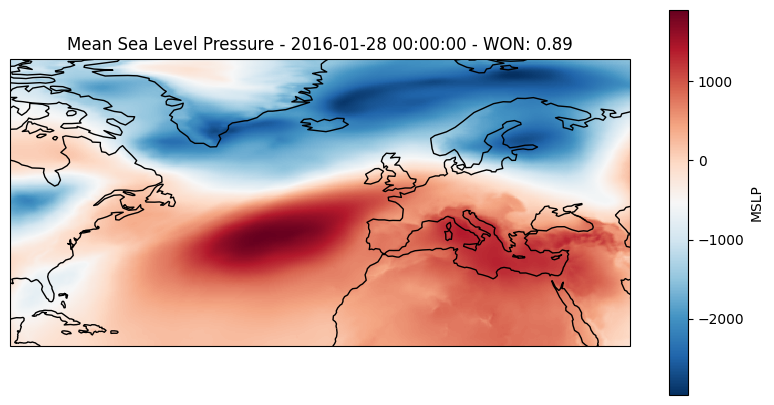

2016-01-31 00:00:00


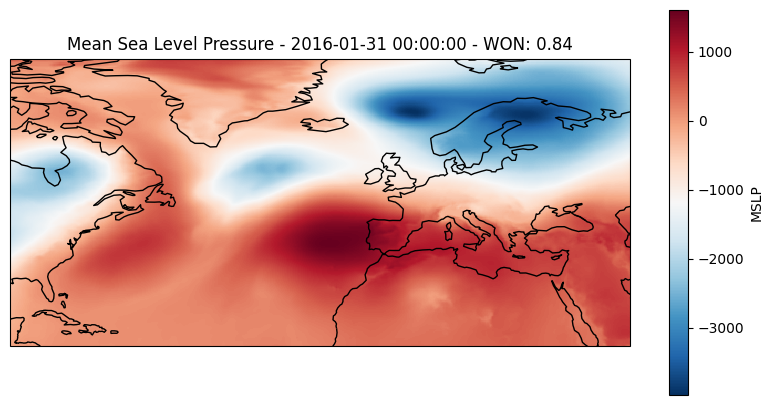

2016-02-01 00:00:00


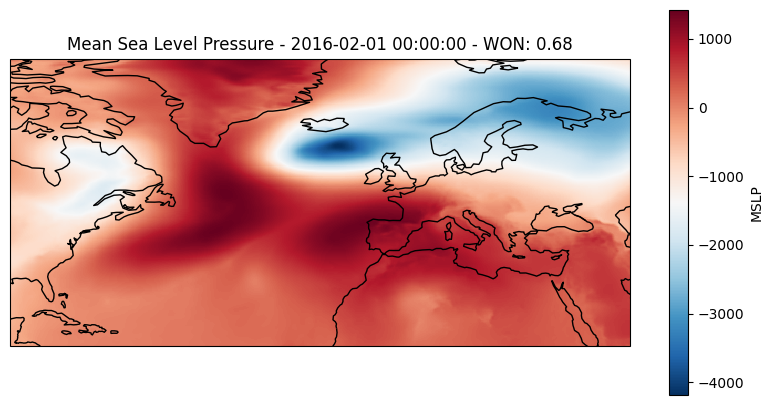

2016-02-04 00:00:00


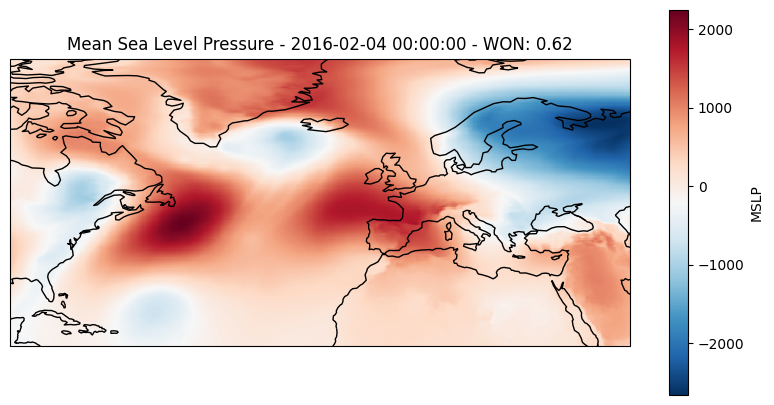

2016-02-05 00:00:00


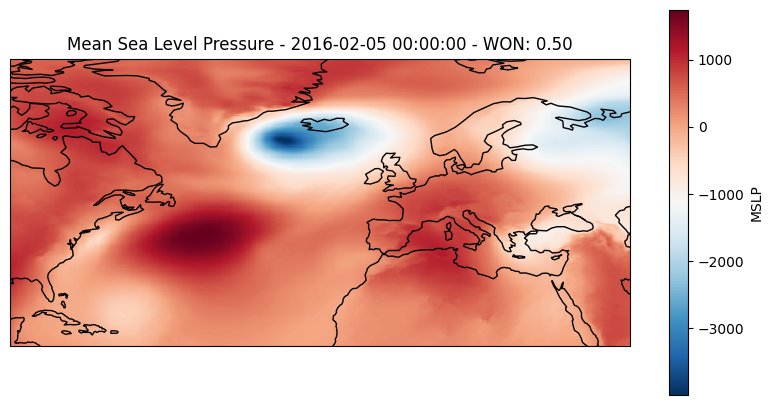

2016-02-06 00:00:00


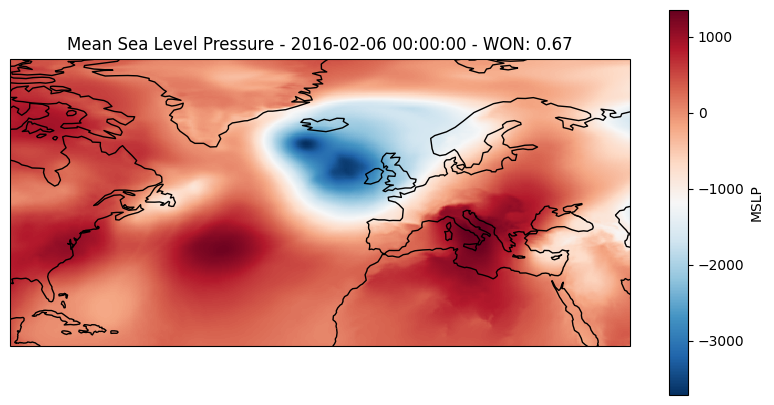

2016-02-07 00:00:00


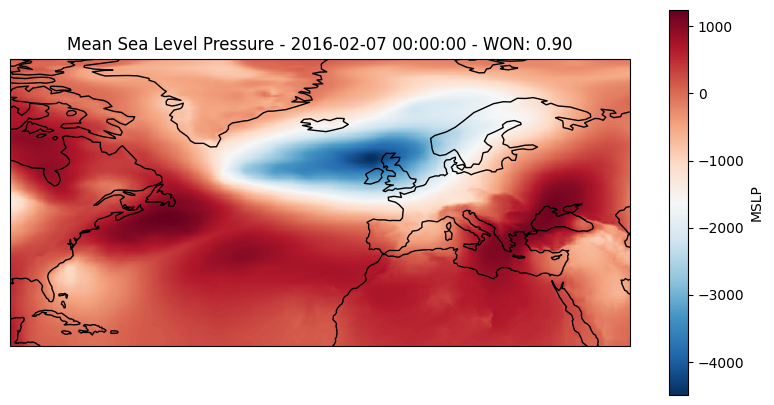

2016-02-09 00:00:00


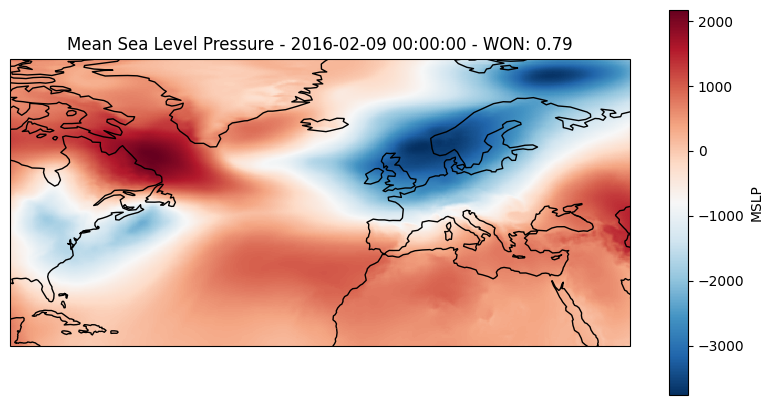

2016-02-10 00:00:00


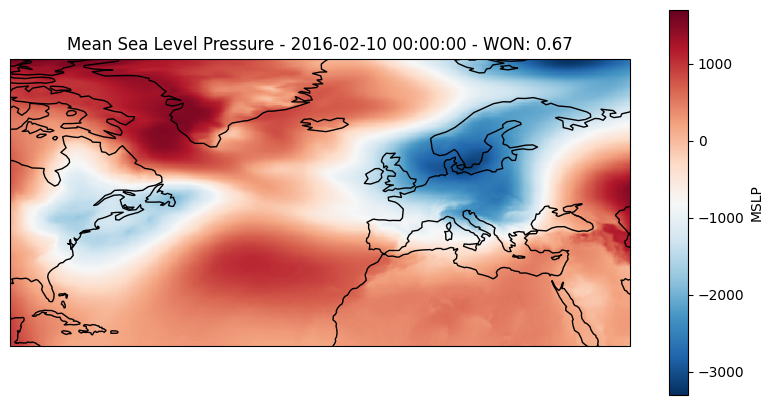

2016-02-19 00:00:00


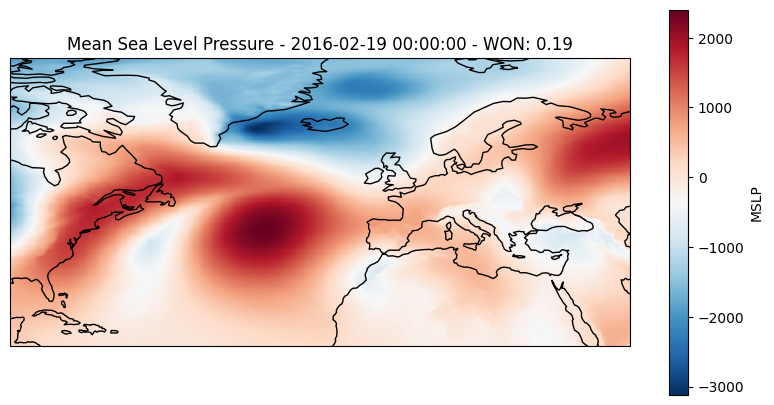

2016-02-20 00:00:00


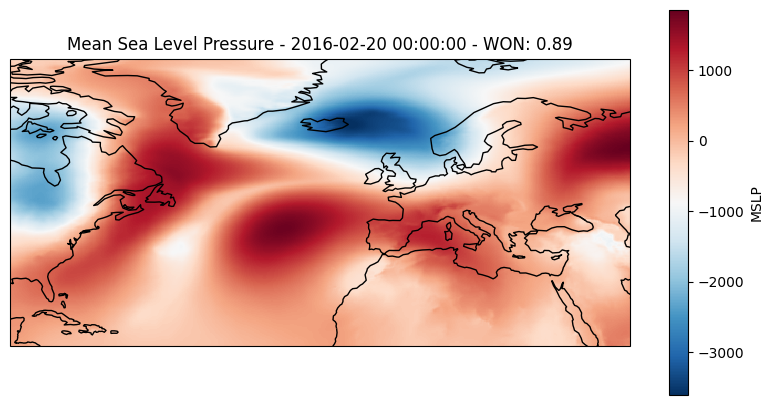

2016-02-21 00:00:00


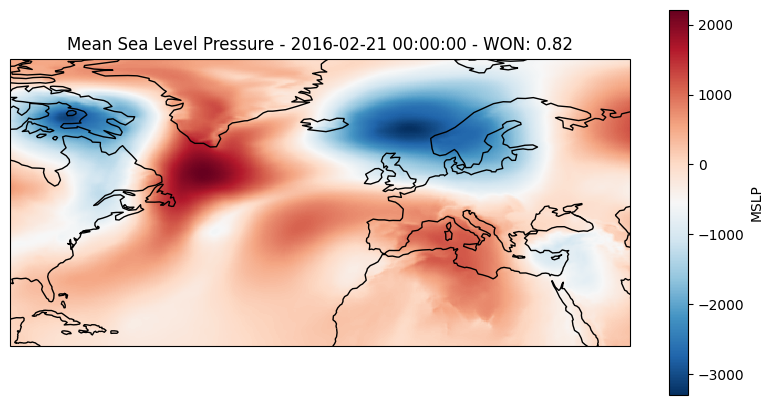

2016-02-22 00:00:00


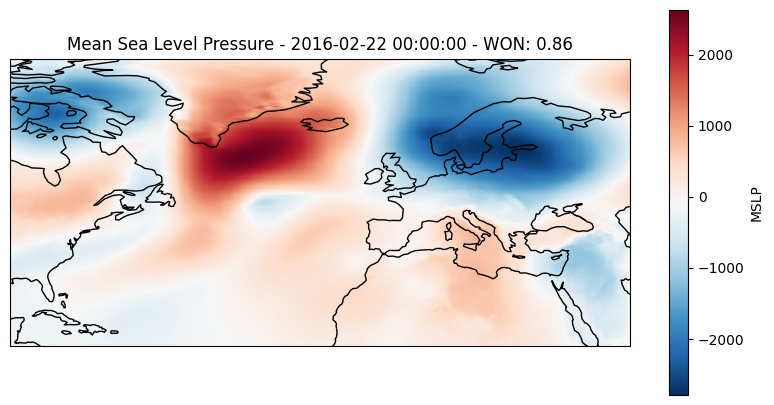

2016-02-23 00:00:00


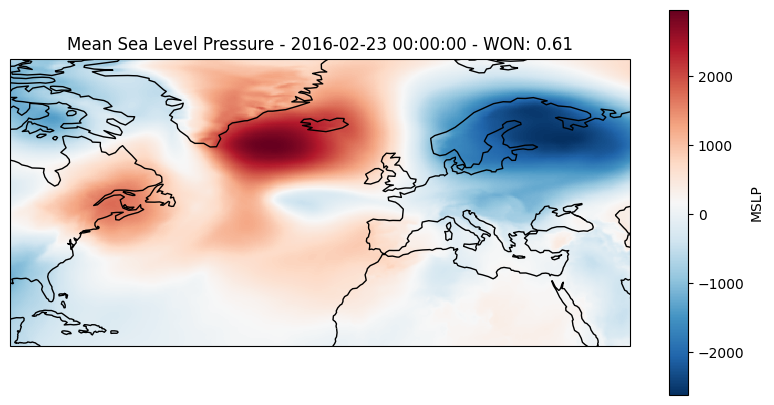

2016-02-24 00:00:00


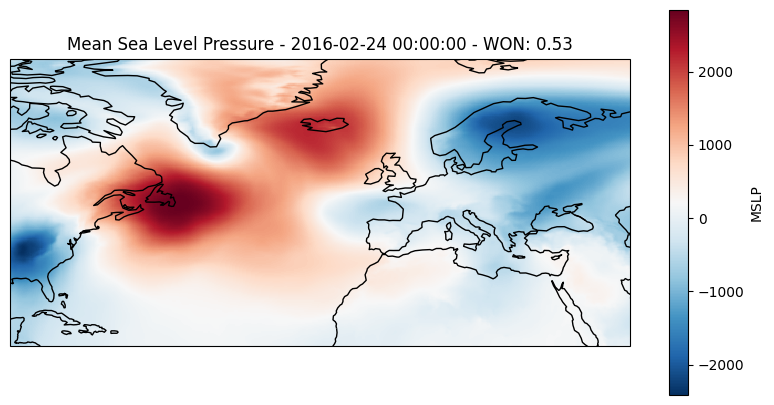

2016-02-25 00:00:00


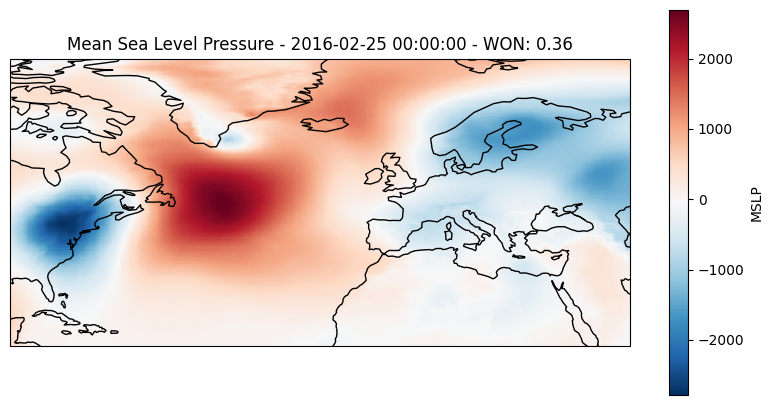

2016-12-08 00:00:00


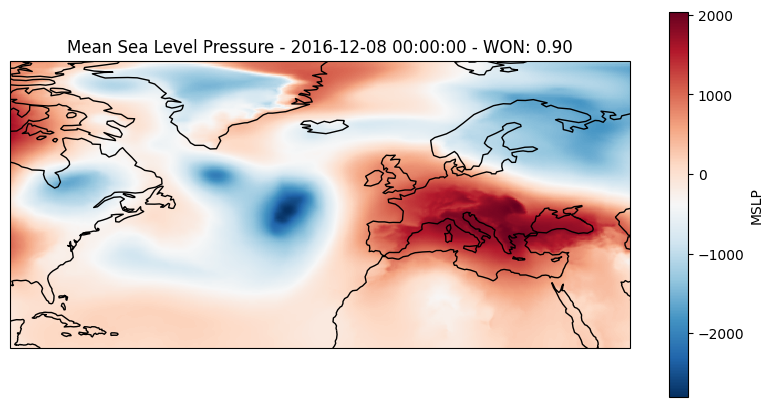

2016-12-09 00:00:00


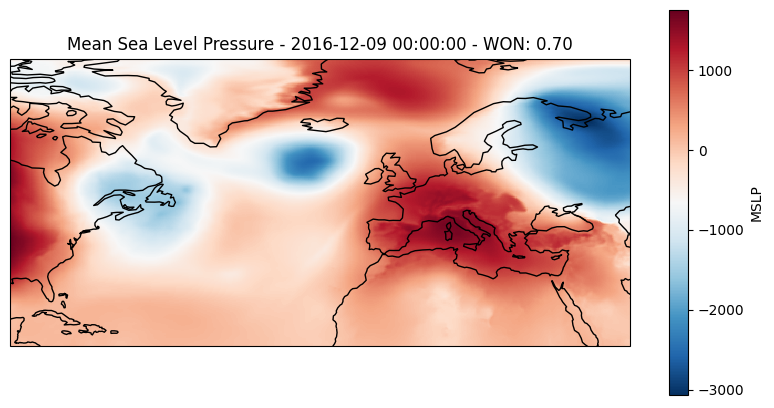

2016-12-21 00:00:00


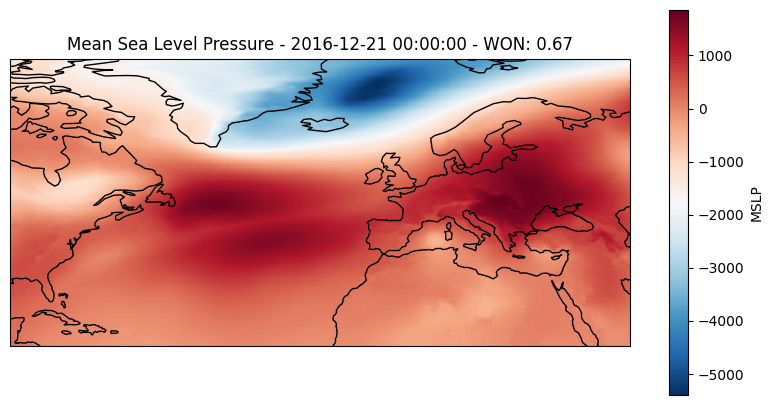

2016-12-22 00:00:00


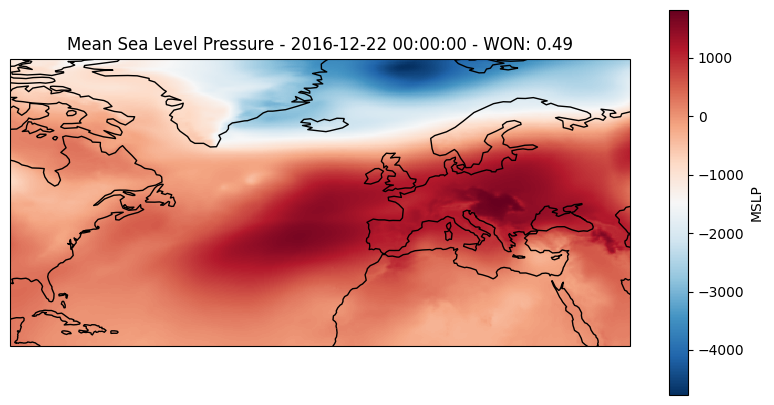

2016-12-23 00:00:00


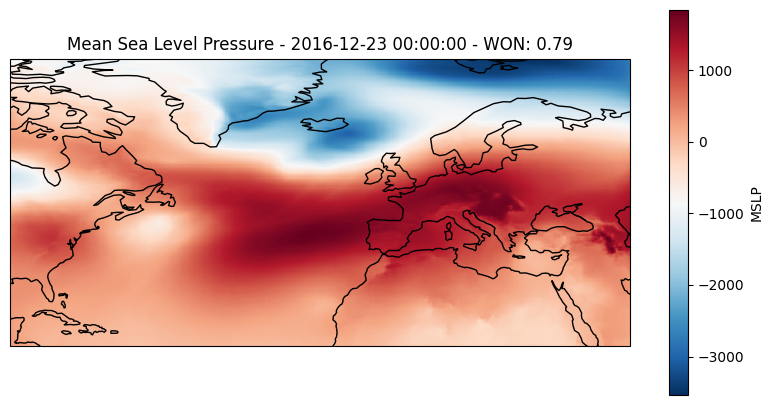

2017-01-10 00:00:00


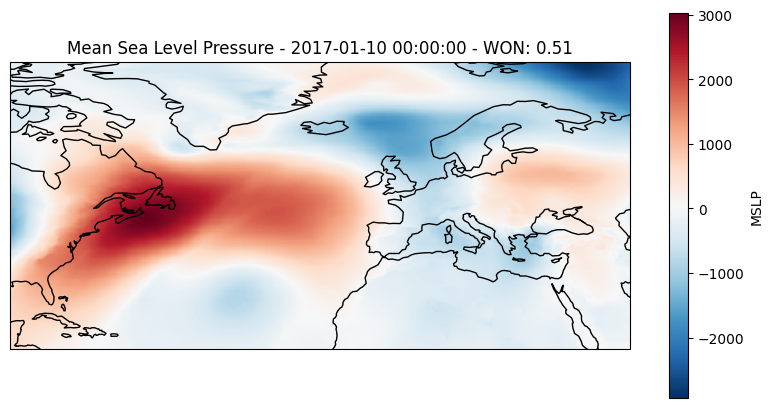

2017-01-11 00:00:00


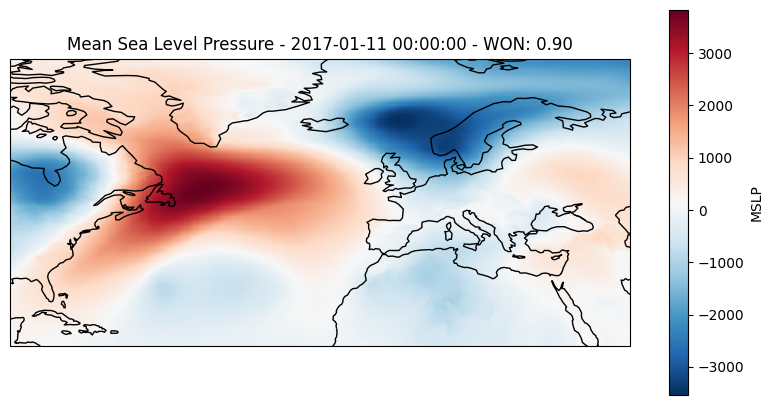

2017-01-12 00:00:00


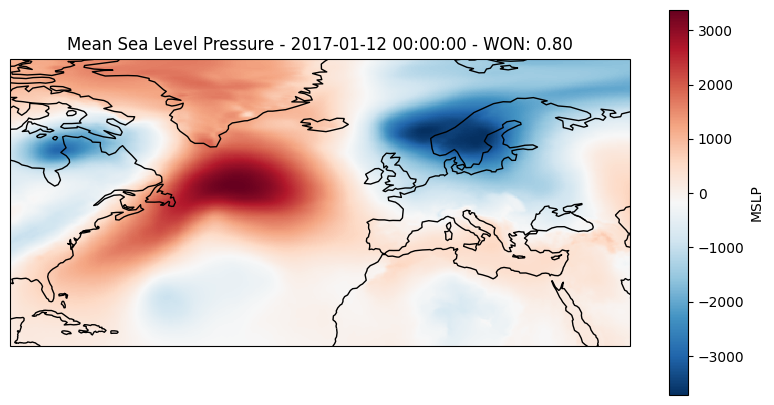

2017-01-13 00:00:00


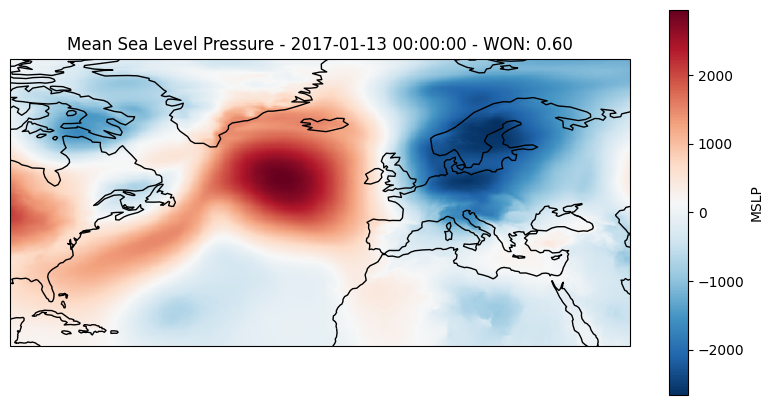

2017-01-14 00:00:00


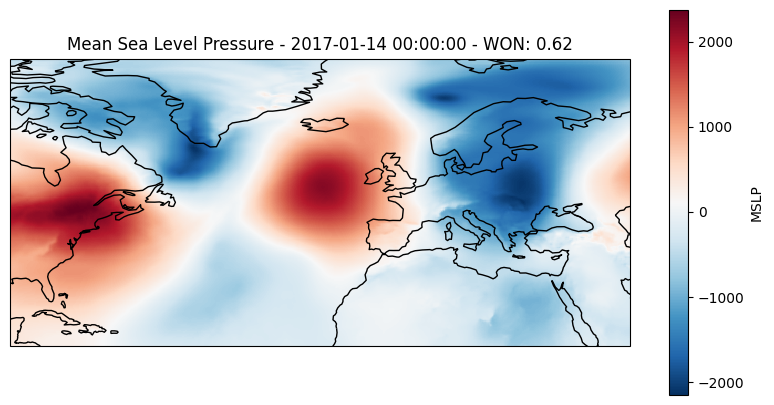

2017-02-19 00:00:00


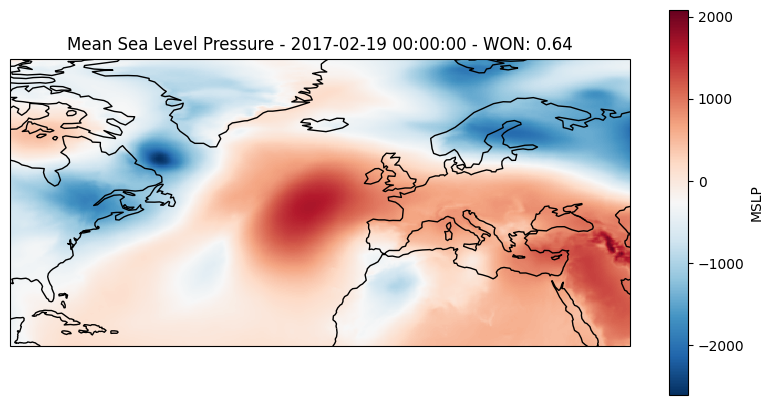

2017-02-20 00:00:00


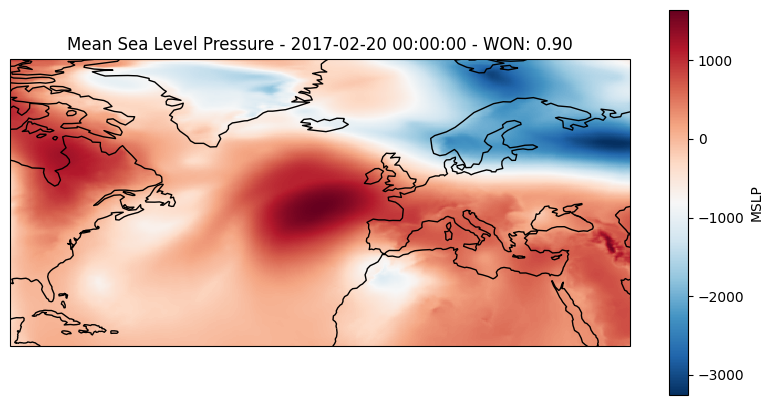

2017-02-21 00:00:00


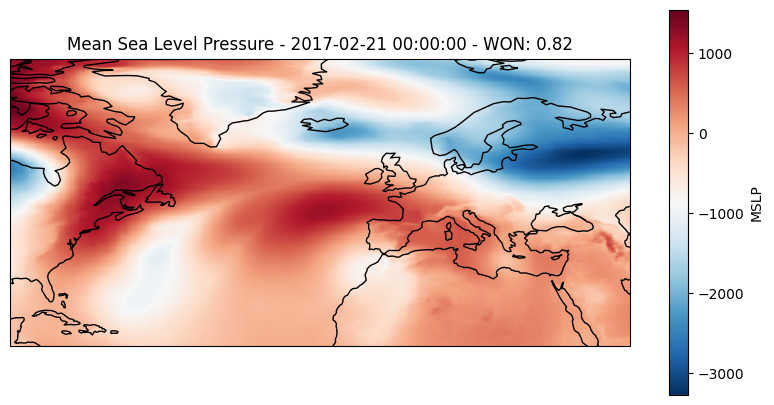

2017-02-23 00:00:00


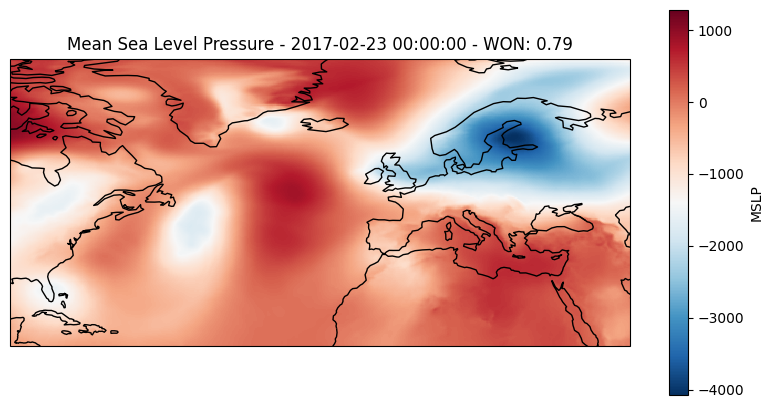

2017-02-24 00:00:00


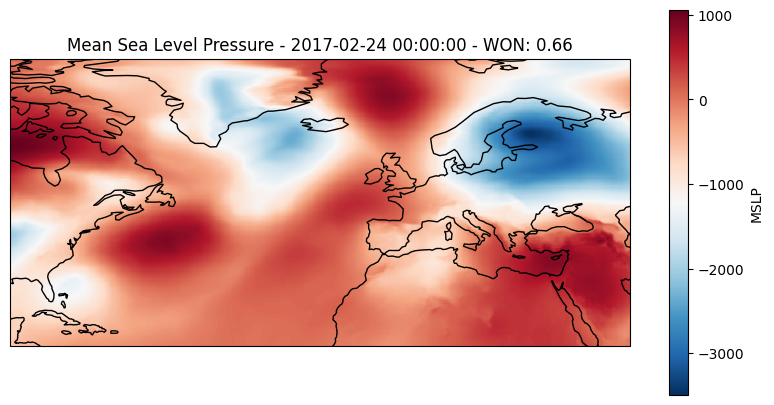

2017-02-25 00:00:00


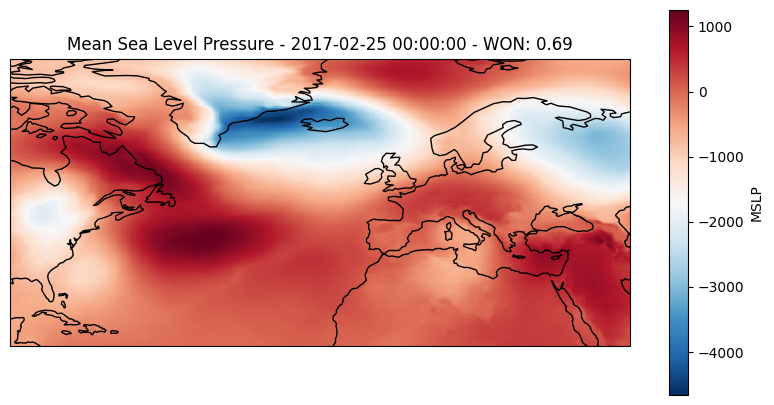

2017-02-26 00:00:00


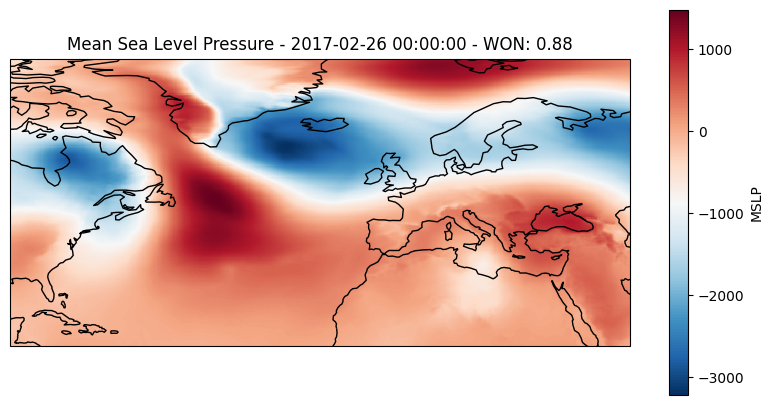

2017-02-27 00:00:00


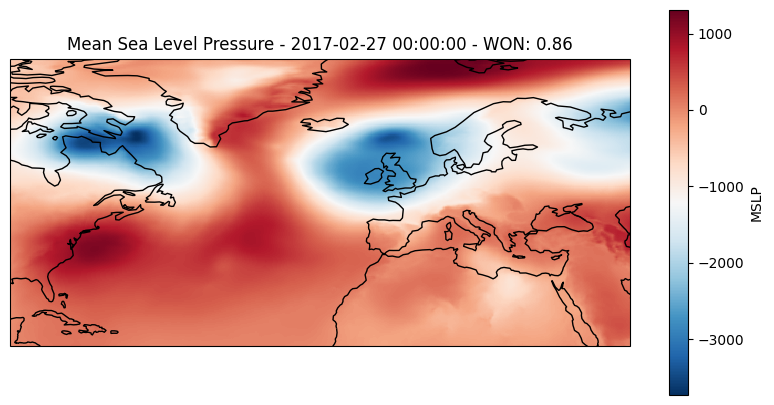

2017-02-28 00:00:00


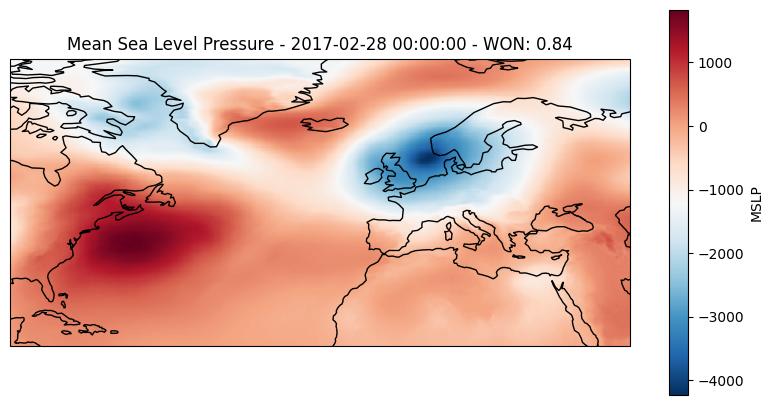

2017-12-08 00:00:00


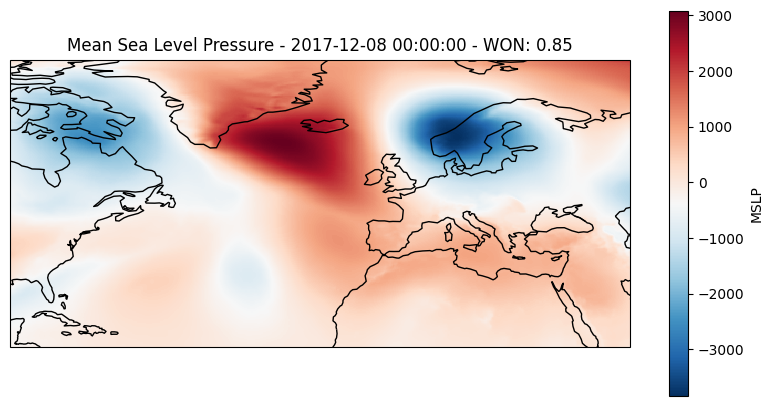

2017-12-09 00:00:00


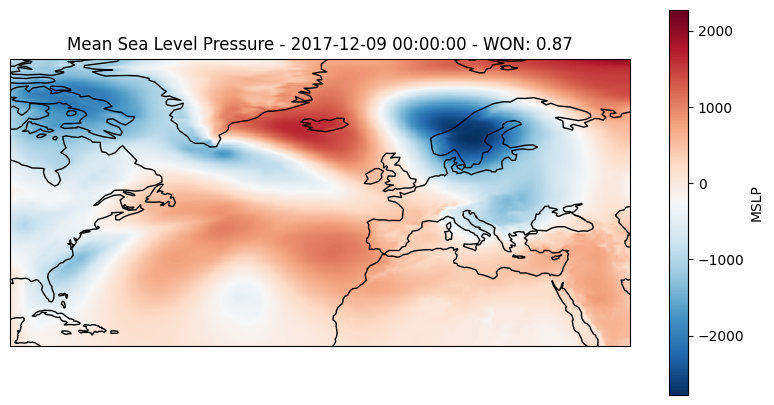

2017-12-10 00:00:00


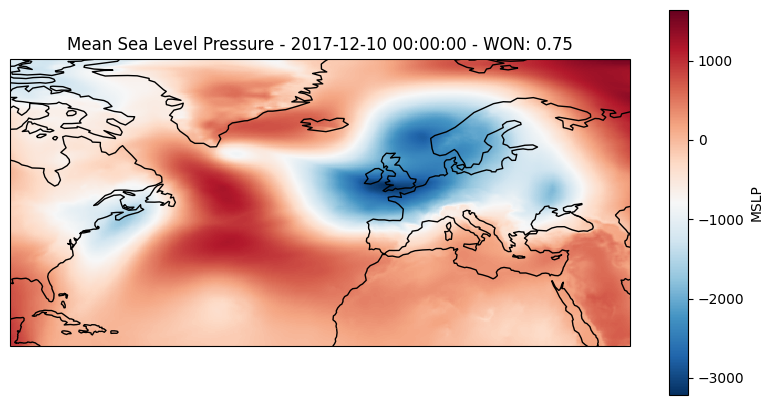

2017-12-11 00:00:00


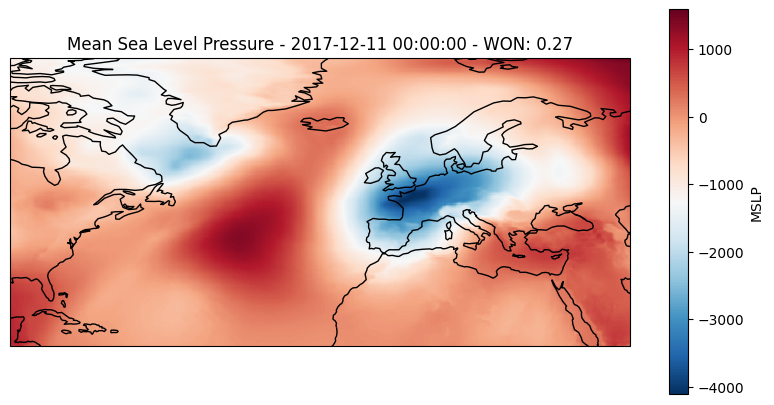

2017-12-12 00:00:00


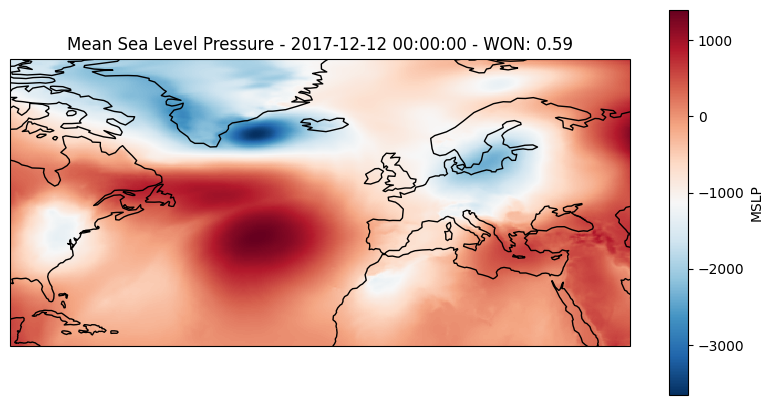

2017-12-13 00:00:00


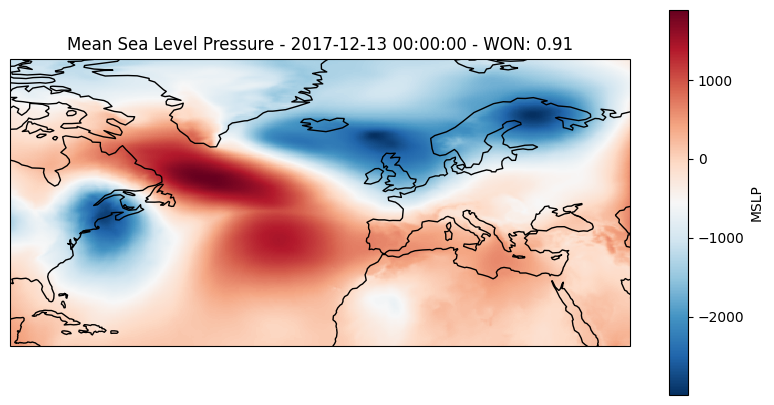

2017-12-14 00:00:00


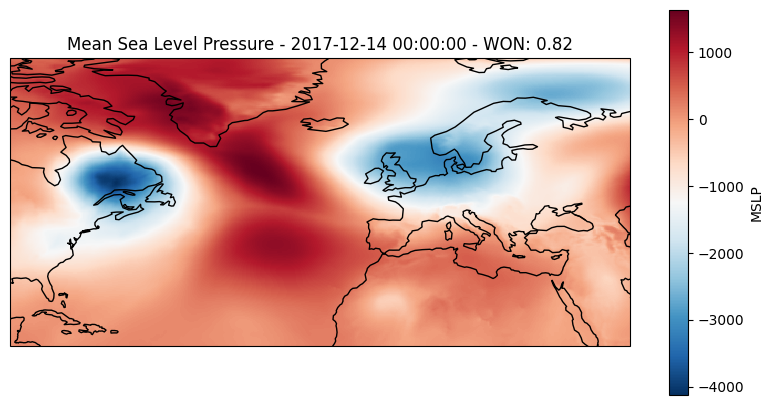

2017-12-15 00:00:00


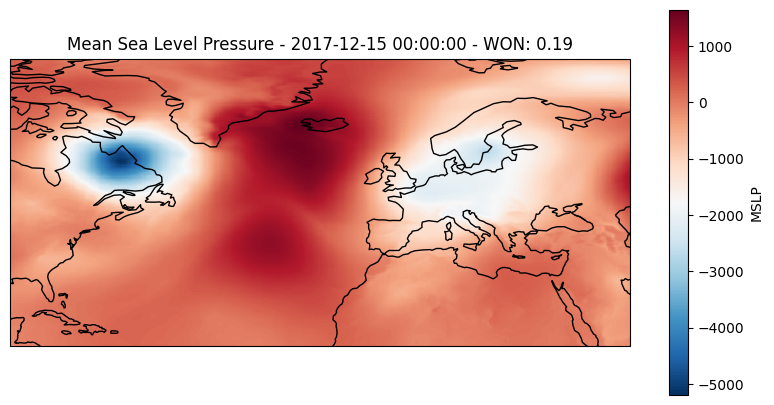

2017-12-23 00:00:00


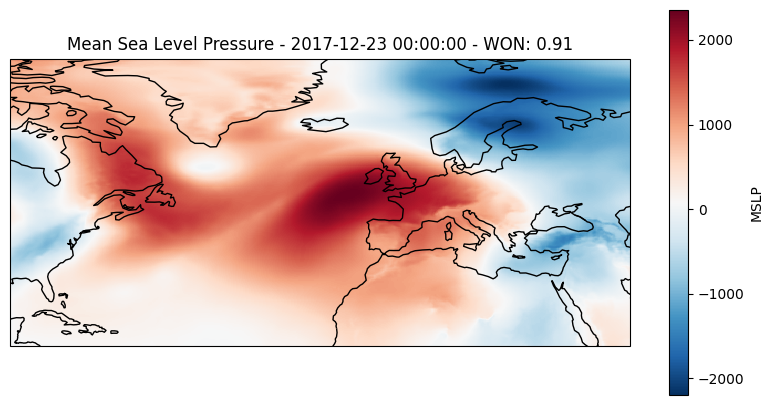

2017-12-25 00:00:00


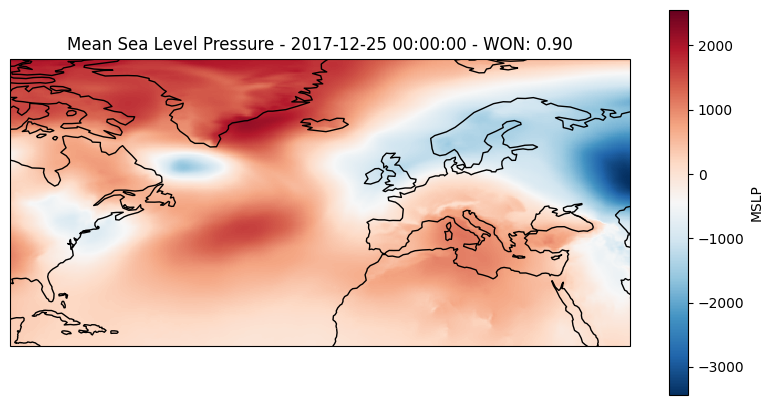

2017-12-26 00:00:00


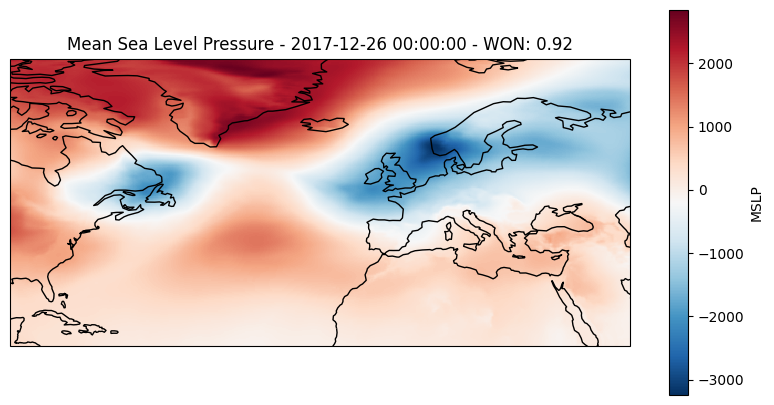

2017-12-27 00:00:00


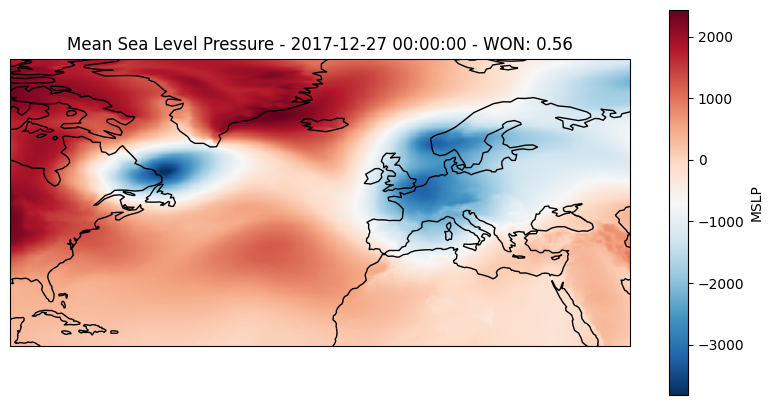

2017-12-28 00:00:00


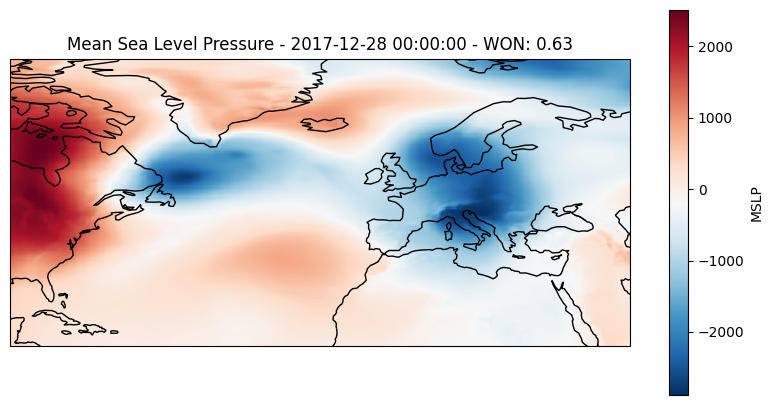

2017-12-29 00:00:00


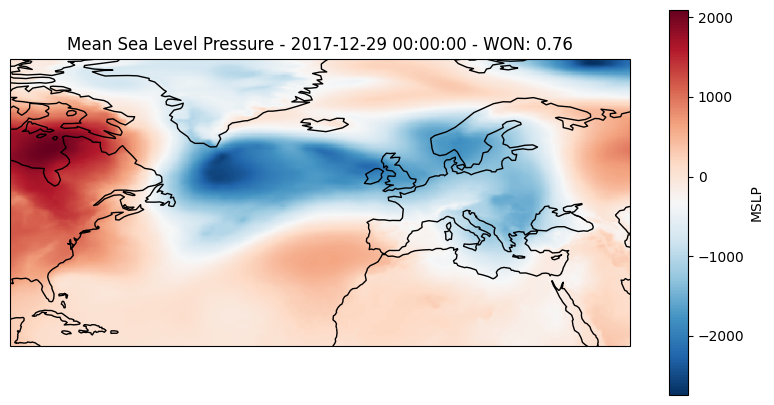

2017-12-30 00:00:00


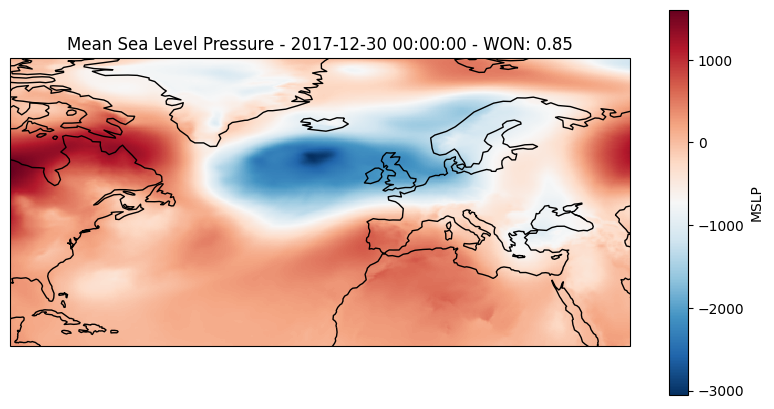

2017-12-31 00:00:00


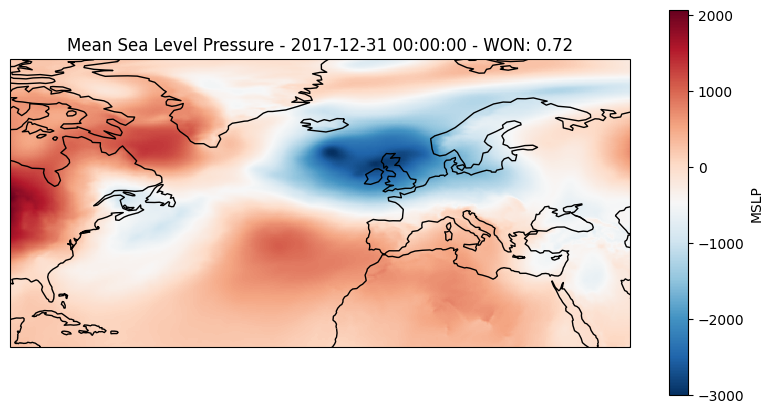

2018-01-01 00:00:00


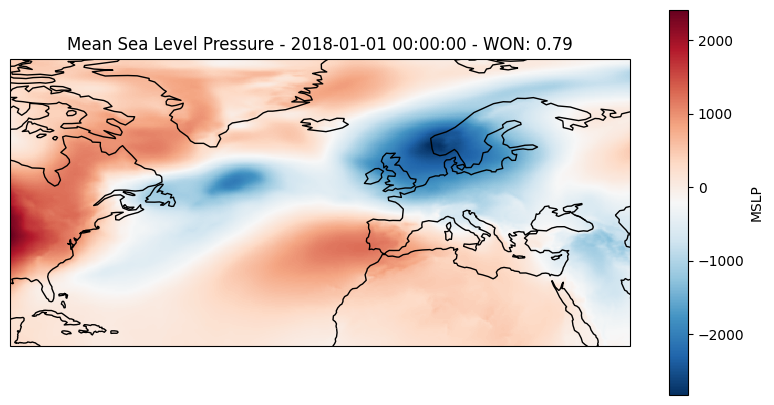

2018-01-02 00:00:00


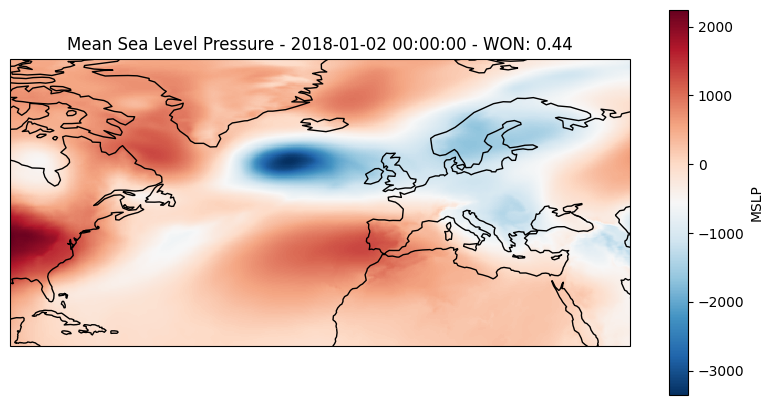

2018-01-04 00:00:00


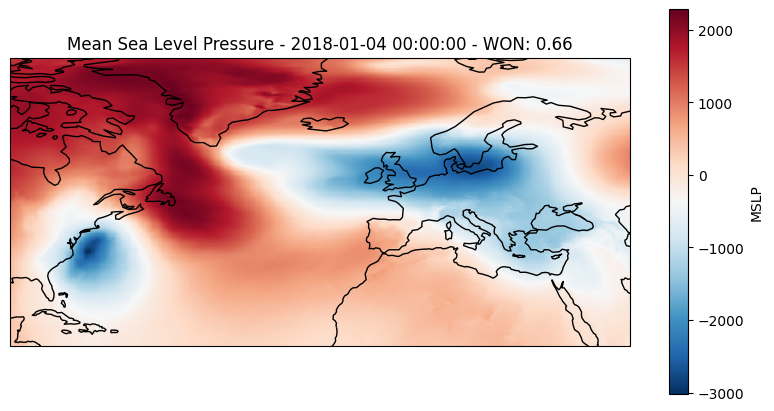

2018-01-16 00:00:00


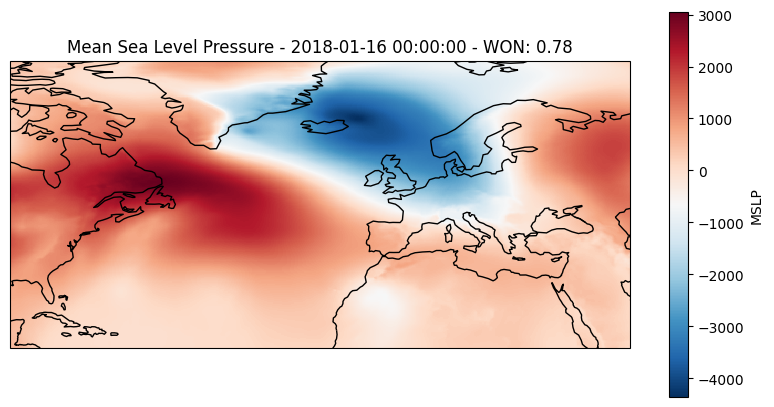

2018-01-17 00:00:00


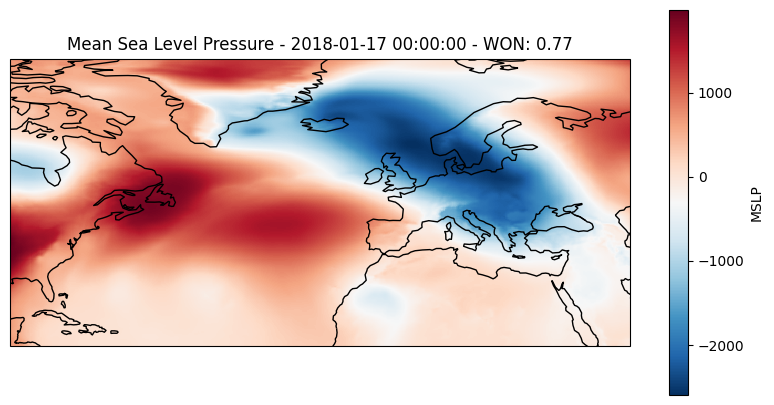

2018-01-18 00:00:00


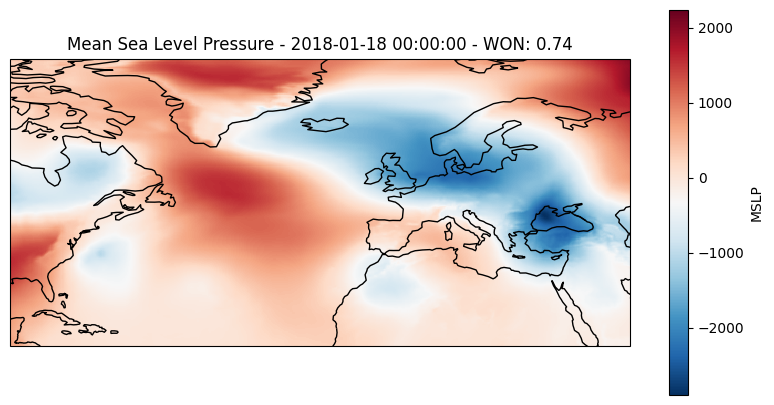

2018-01-25 00:00:00


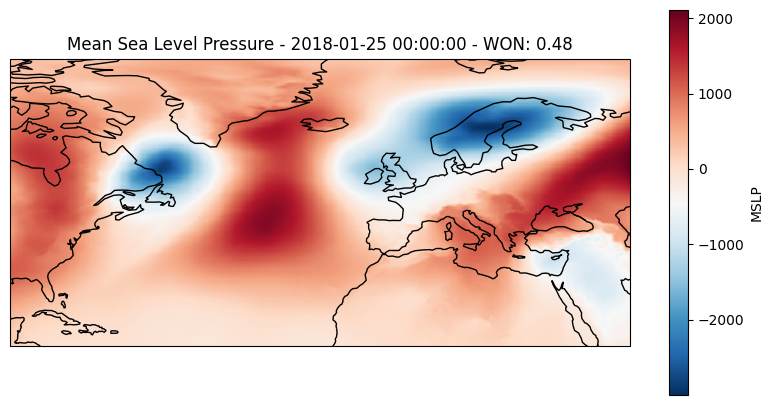

2018-01-31 00:00:00


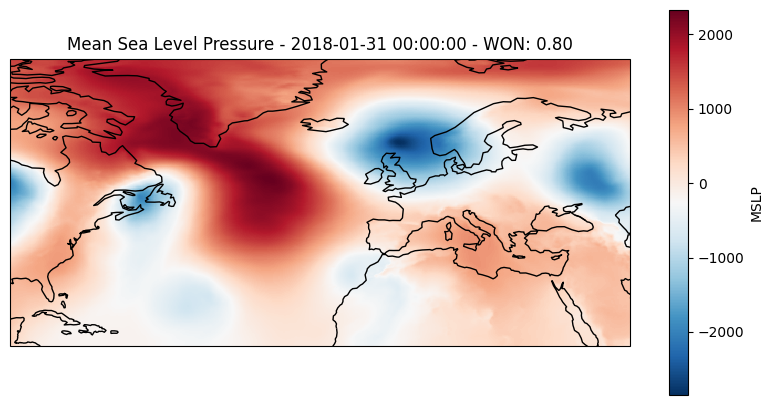

2018-02-11 00:00:00


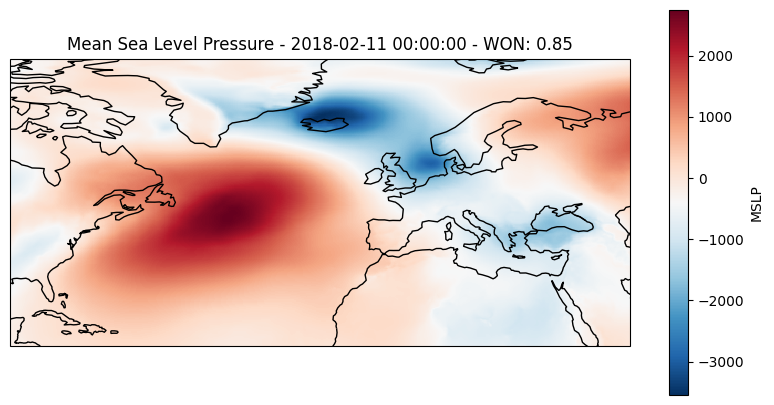

2018-02-12 00:00:00


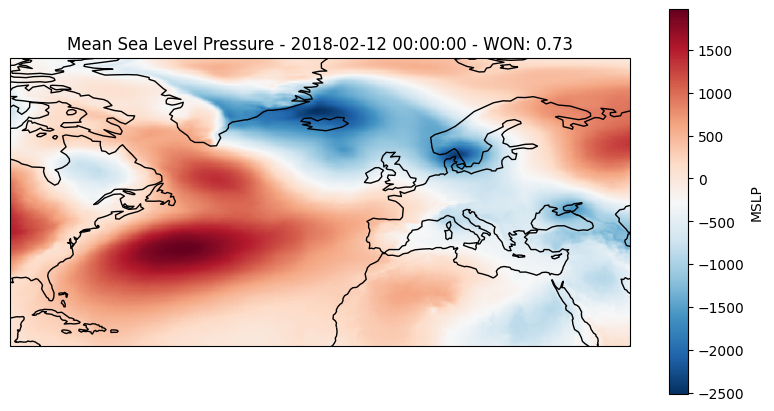

2018-12-02 00:00:00


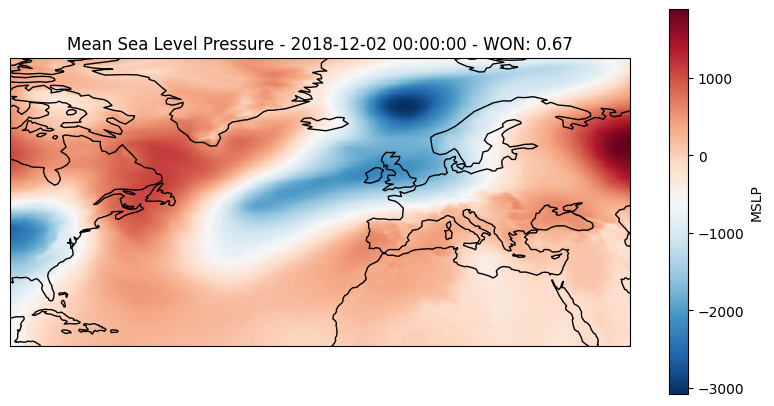

2018-12-03 00:00:00


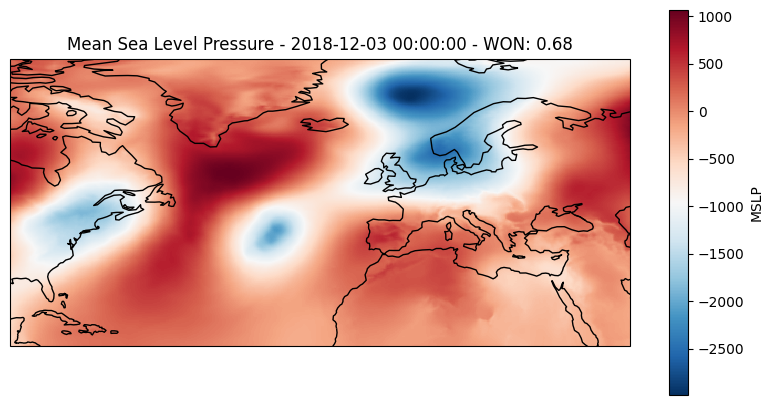

2018-12-07 00:00:00


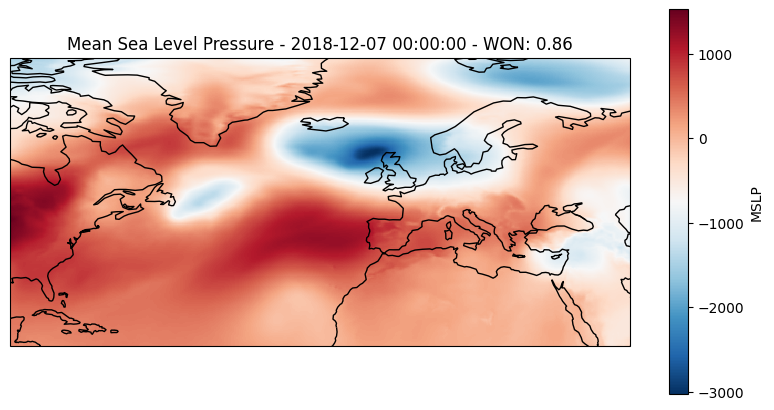

2019-01-12 00:00:00


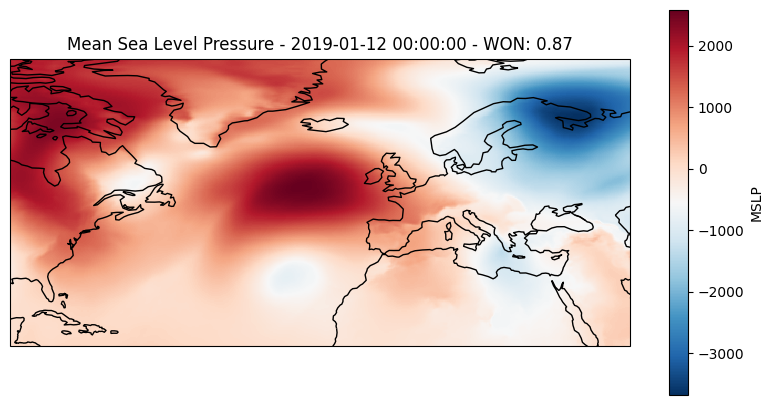

2019-01-17 00:00:00


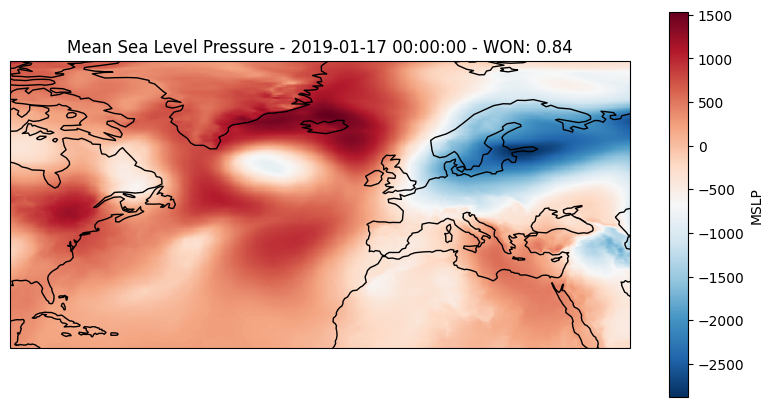

2019-01-18 00:00:00


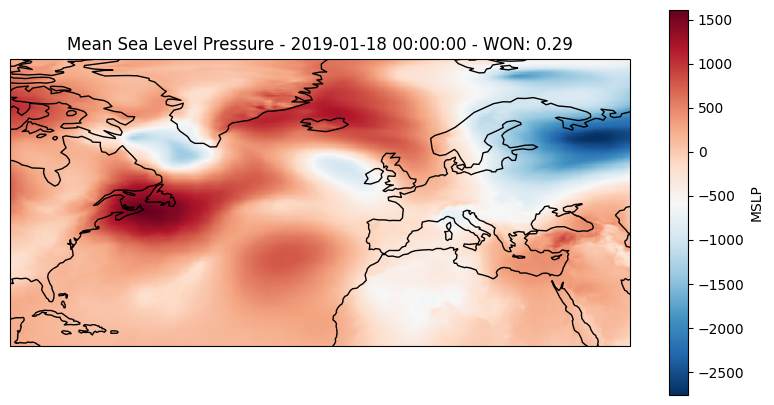

2019-01-27 00:00:00


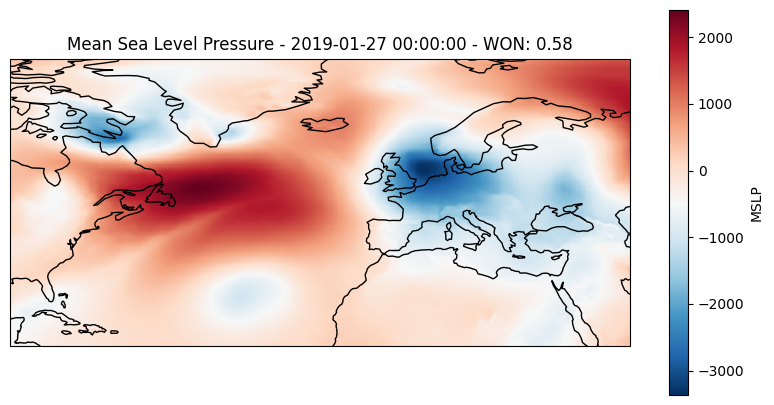

2019-01-28 00:00:00


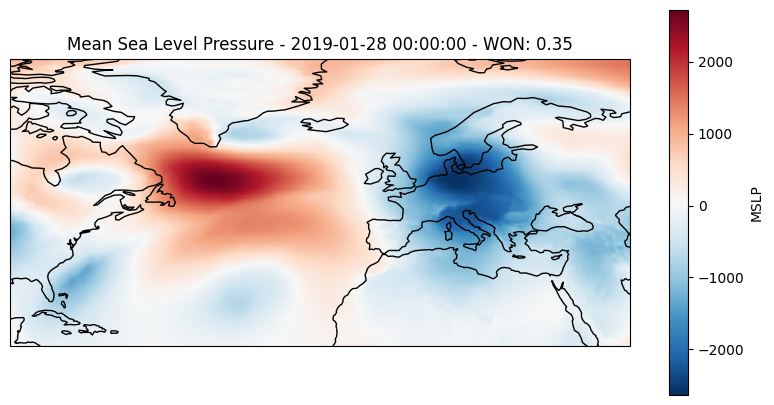

2019-01-29 00:00:00


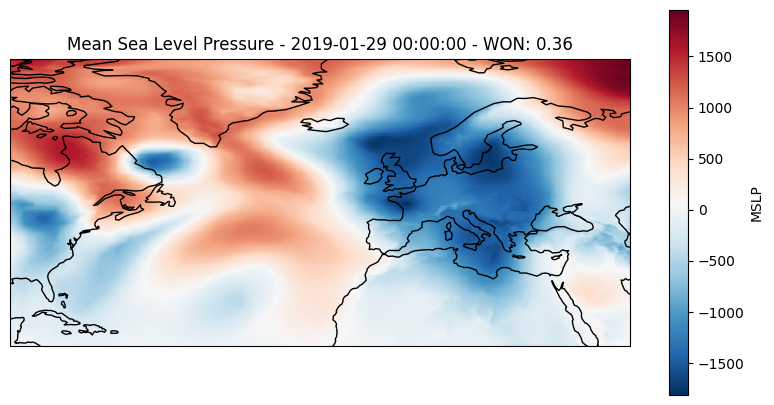

2019-02-07 00:00:00


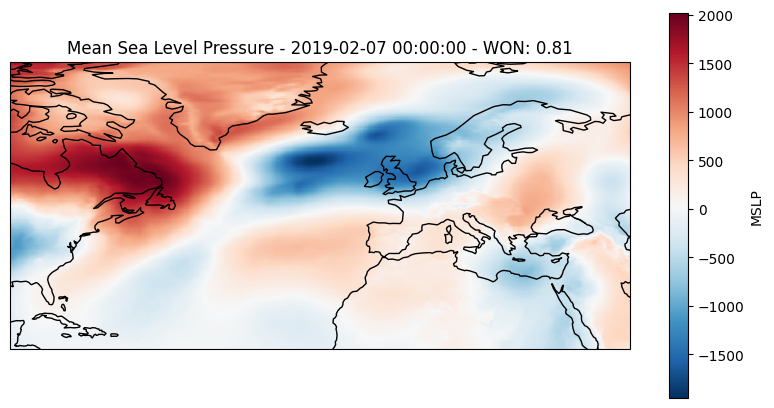

2019-02-10 00:00:00


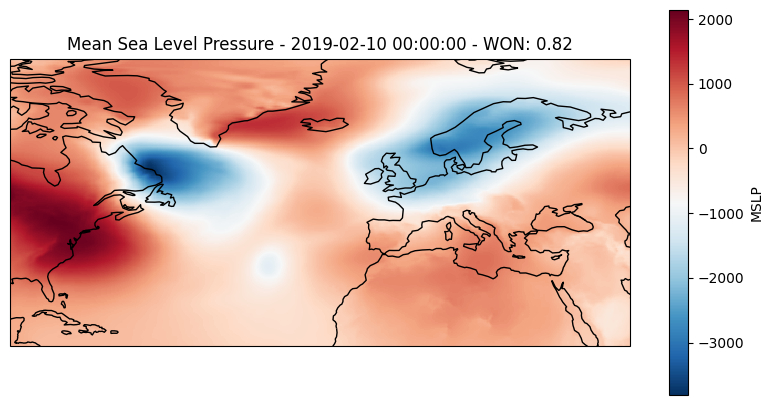

2019-02-16 00:00:00


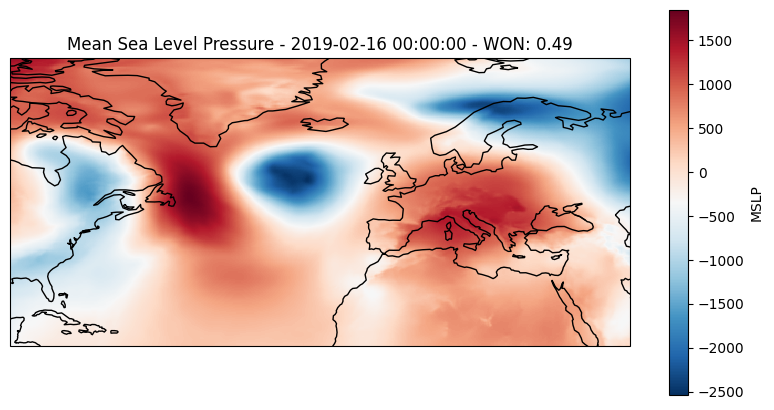

2019-02-28 00:00:00


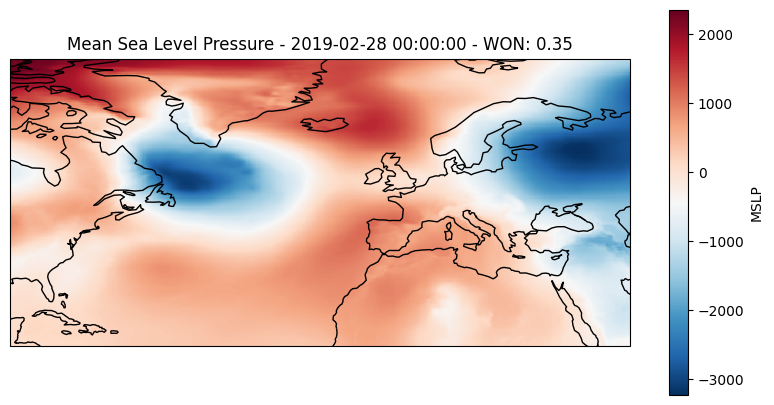

2019-12-04 00:00:00


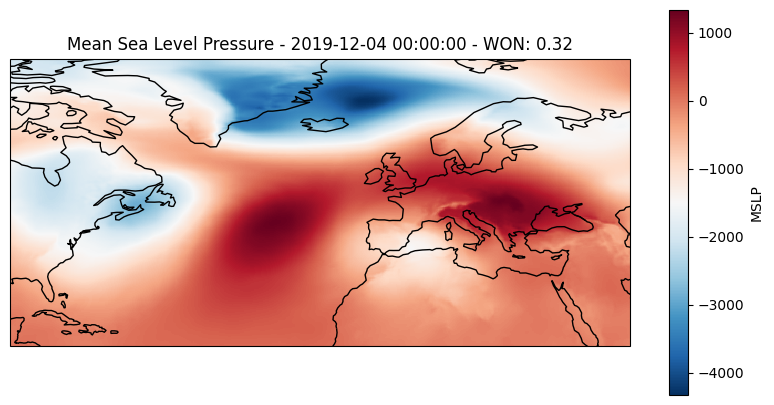

2019-12-05 00:00:00


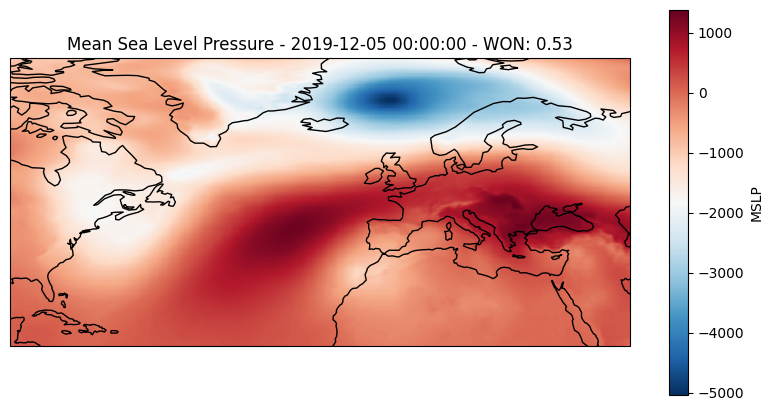

2019-12-09 00:00:00


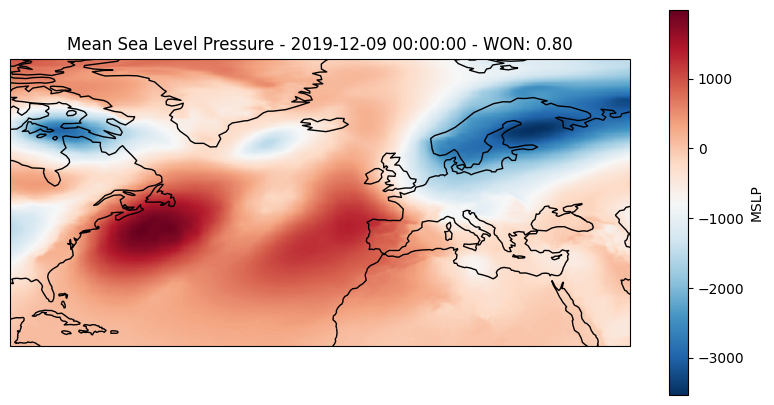

2019-12-10 00:00:00


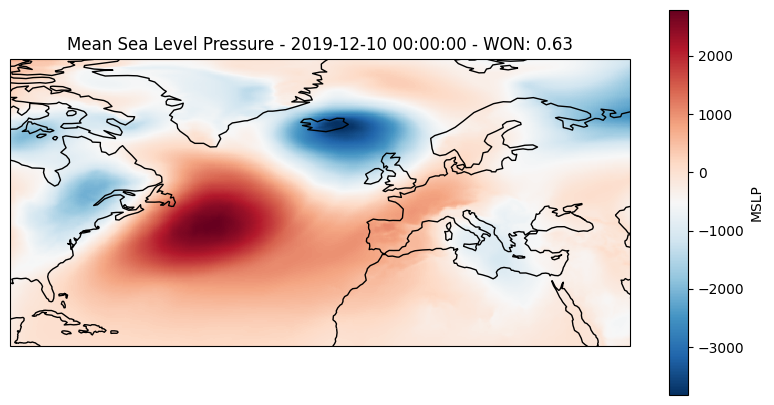

2019-12-11 00:00:00


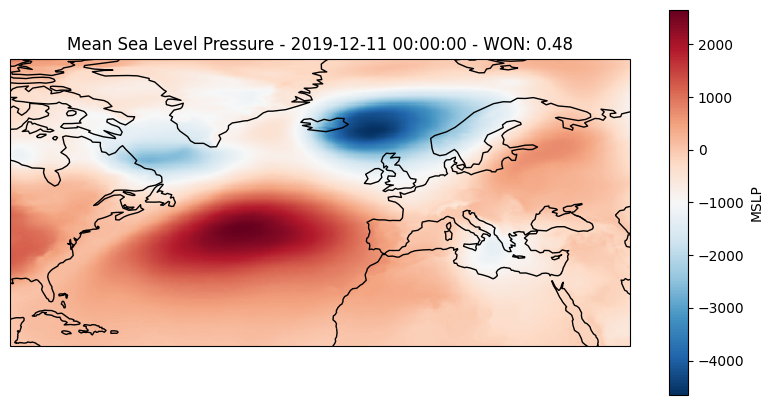

2019-12-12 00:00:00


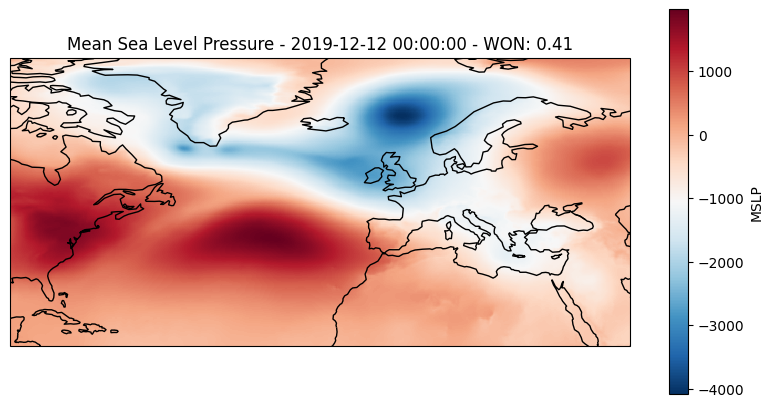

2019-12-13 00:00:00


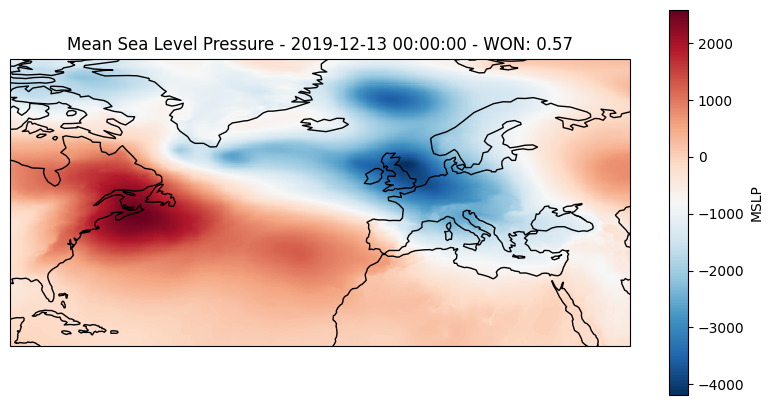

2019-12-14 00:00:00


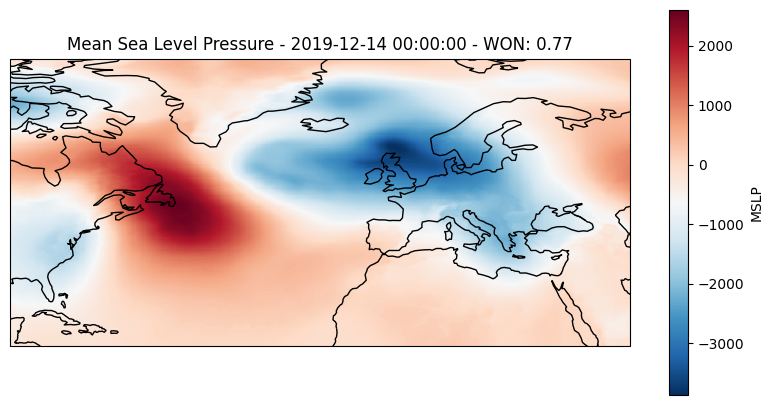

2019-12-21 00:00:00


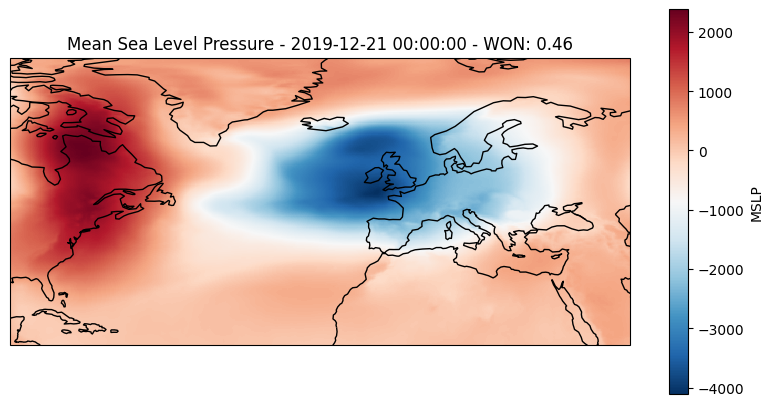

2019-12-22 00:00:00


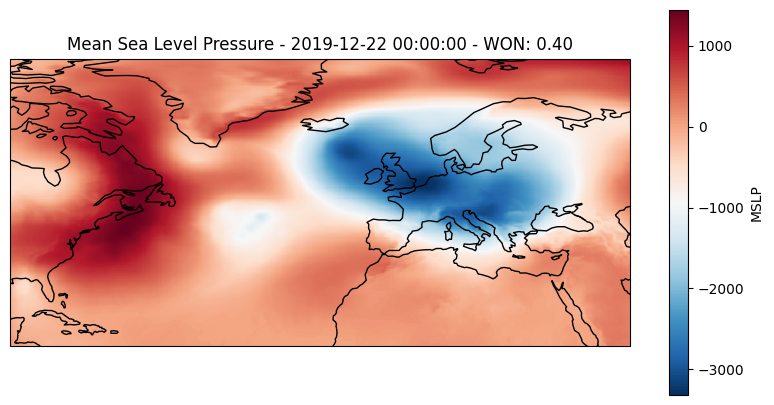

2019-12-23 00:00:00


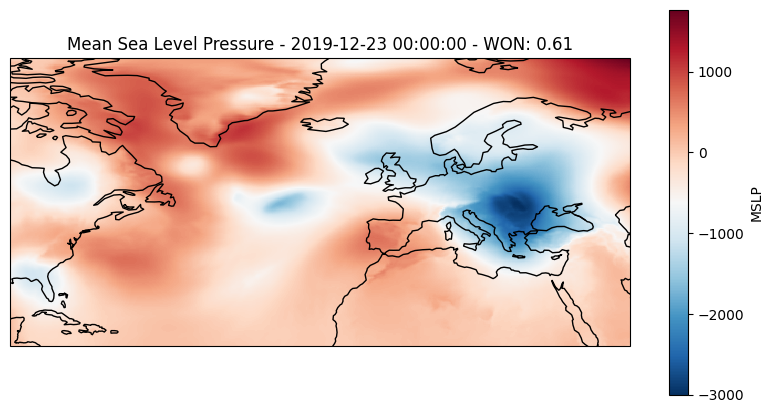

2020-01-02 00:00:00


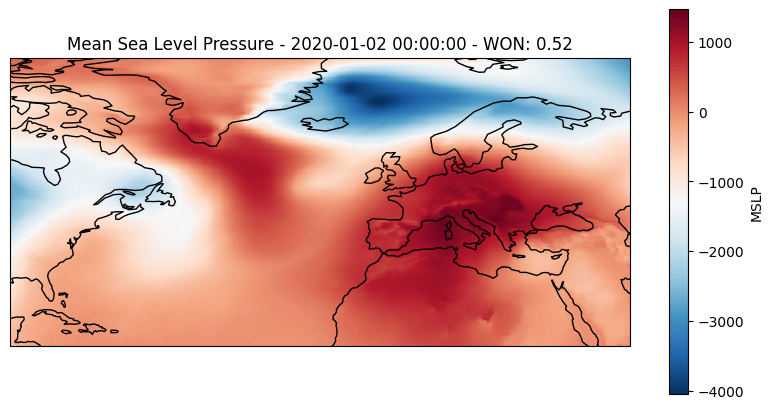

2020-01-03 00:00:00


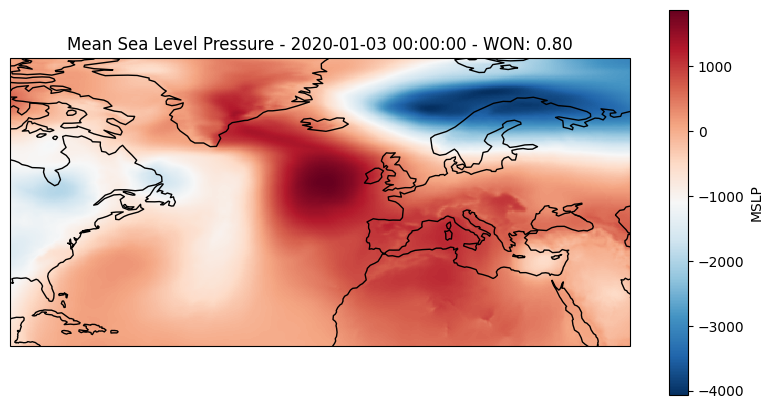

2020-01-04 00:00:00


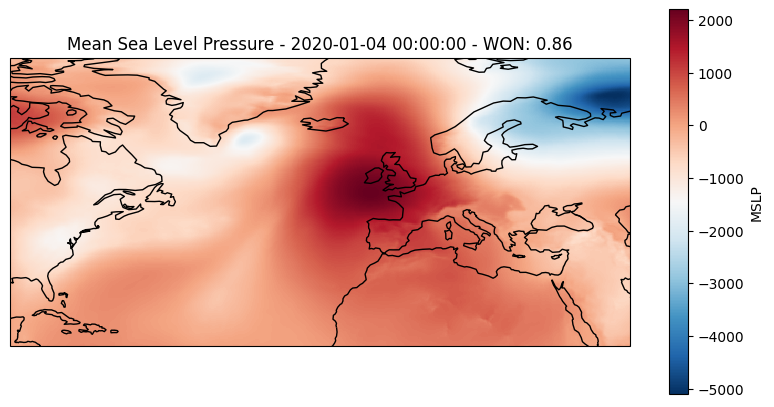

2020-01-07 00:00:00


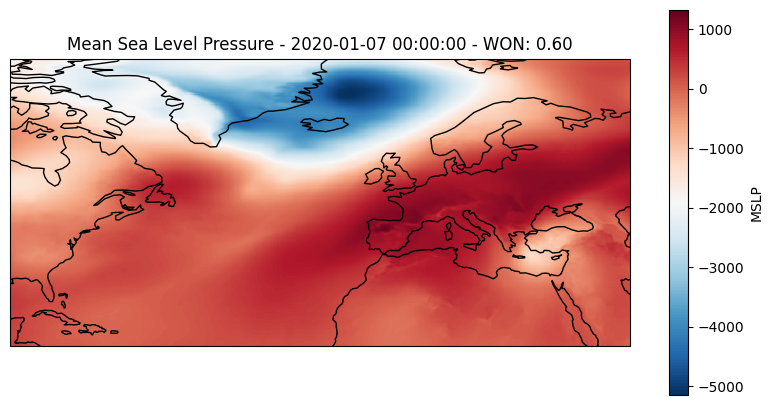

2020-01-08 00:00:00


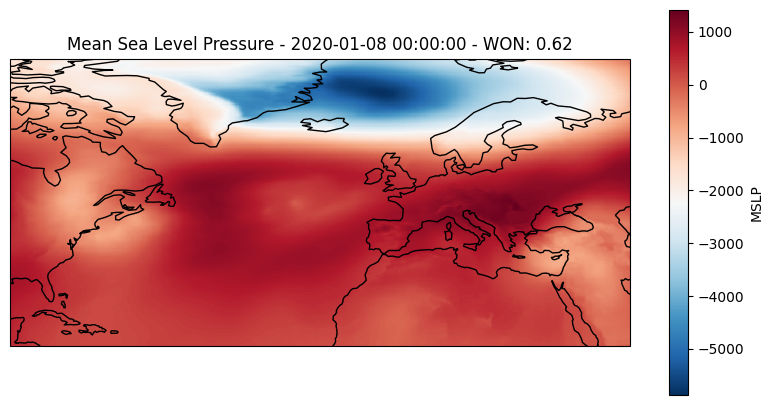

2020-01-09 00:00:00


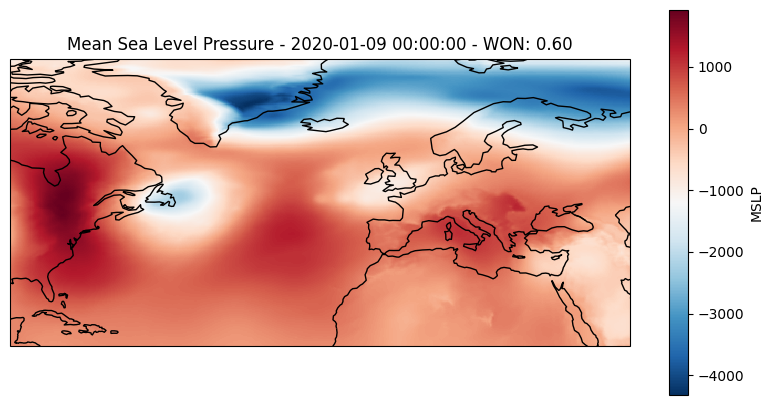

2020-01-10 00:00:00


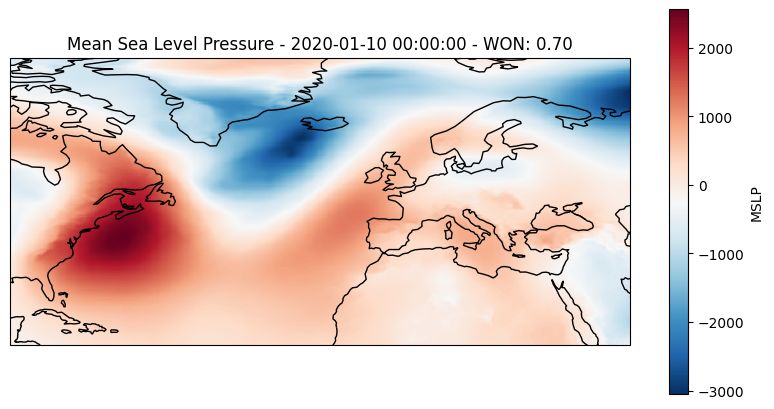

2020-01-11 00:00:00


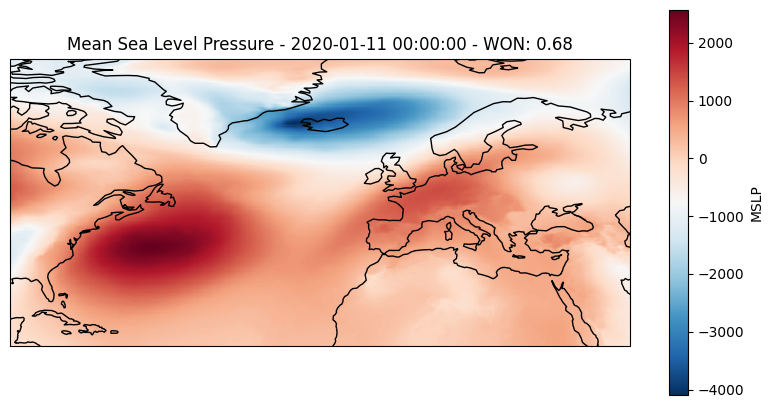

2020-01-13 00:00:00


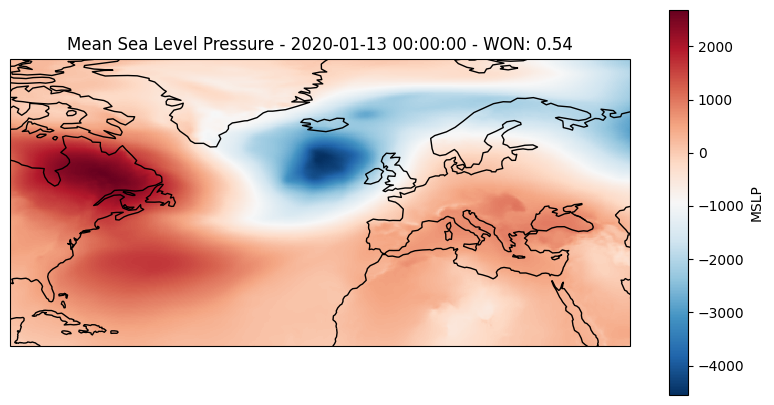

2020-01-16 00:00:00


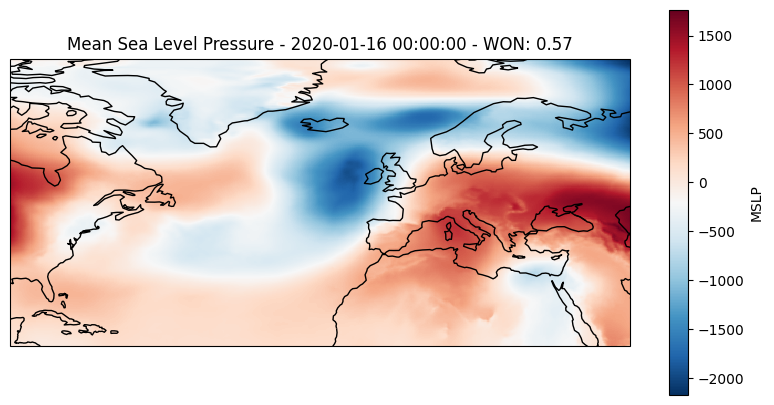

2020-01-24 00:00:00


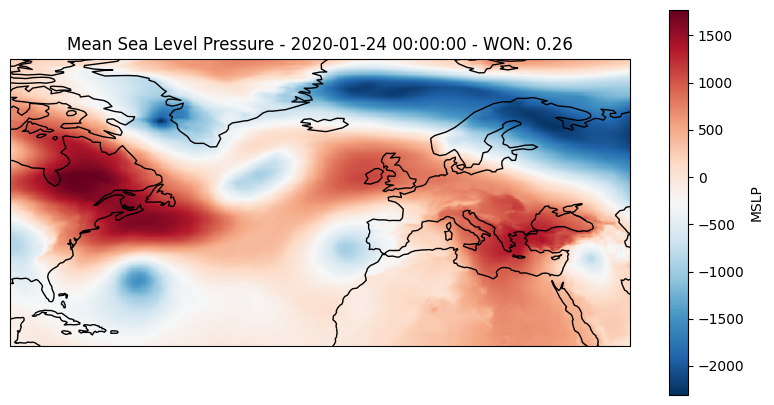

2020-01-25 00:00:00


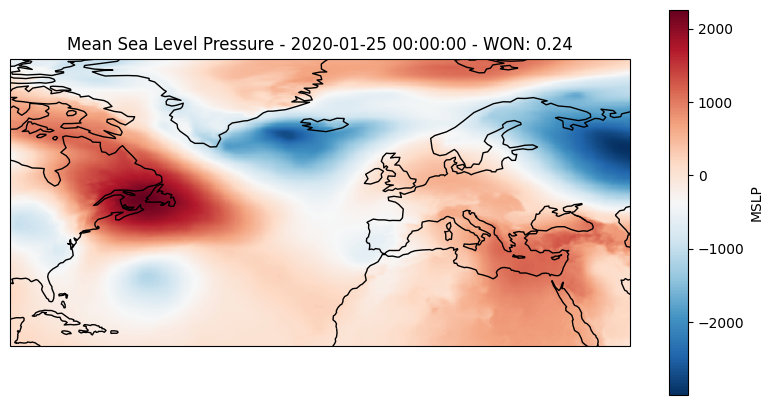

2020-01-26 00:00:00


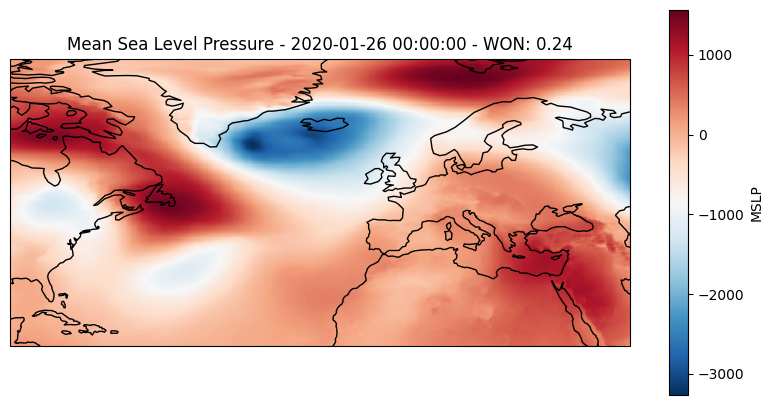

2020-01-27 00:00:00


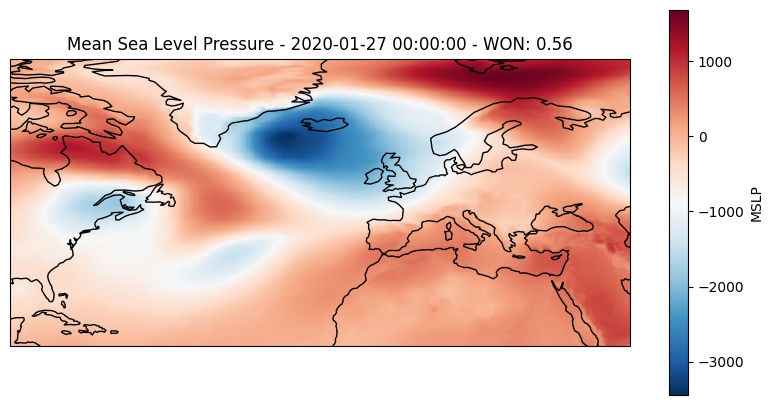

2020-01-28 00:00:00


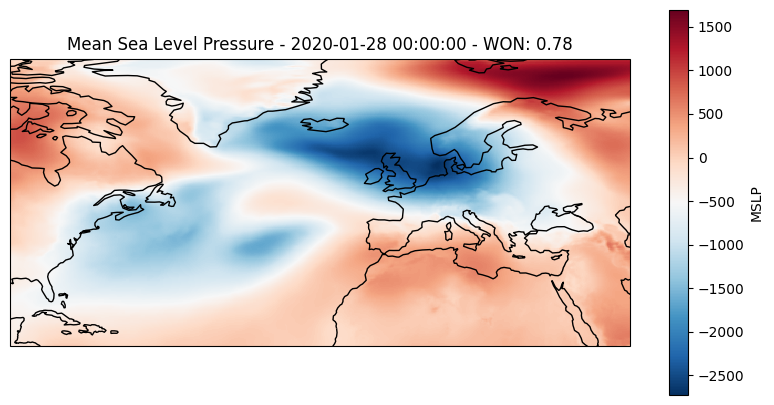

2020-02-02 00:00:00


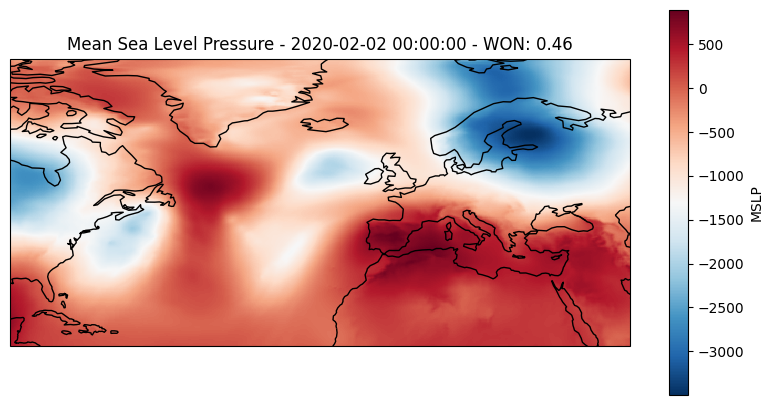

2020-02-03 00:00:00


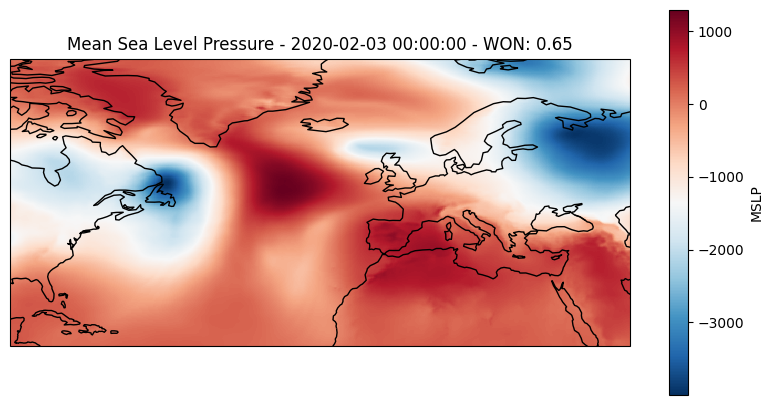

2020-02-04 00:00:00


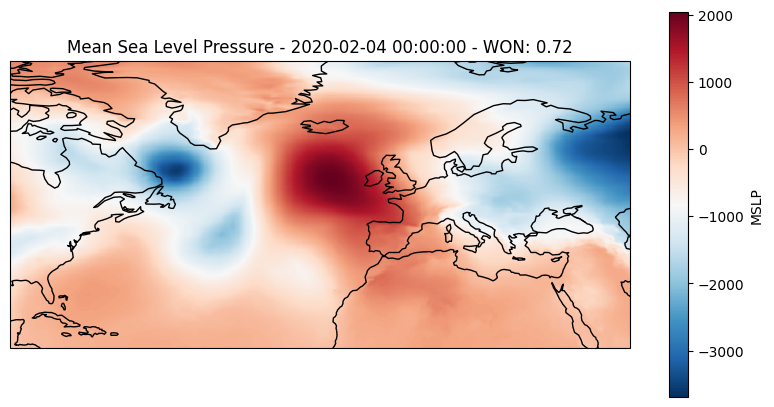

2020-02-08 00:00:00


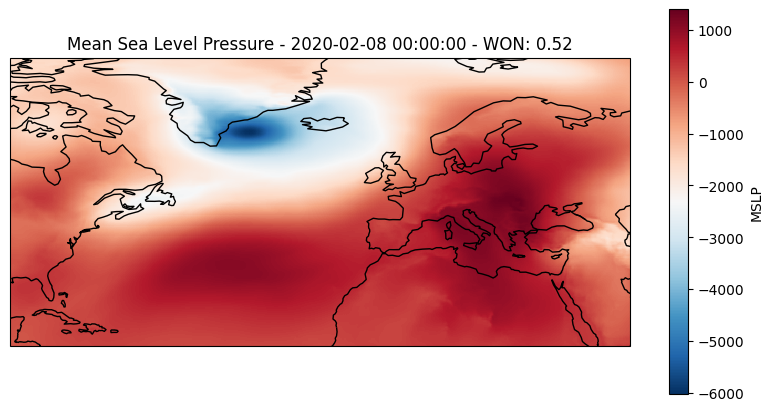

2020-02-09 00:00:00


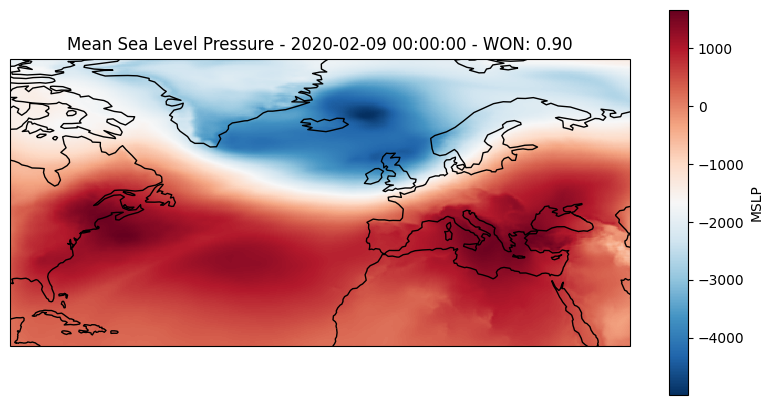

2020-02-13 00:00:00


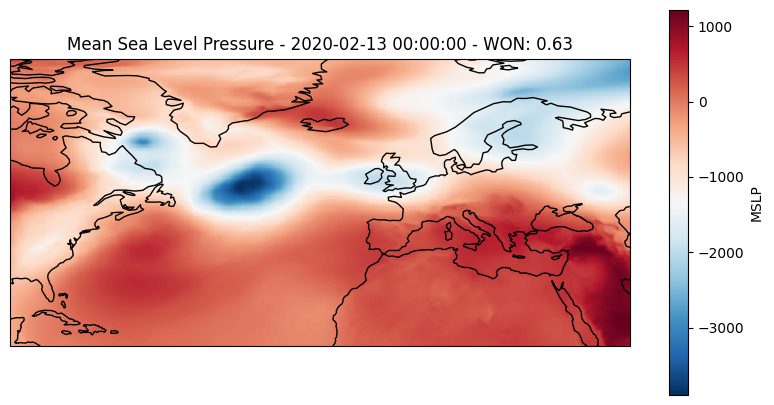

2020-02-15 00:00:00


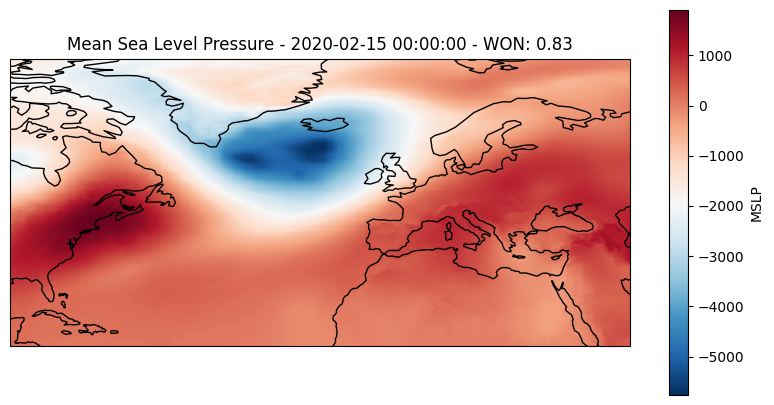

2020-02-19 00:00:00


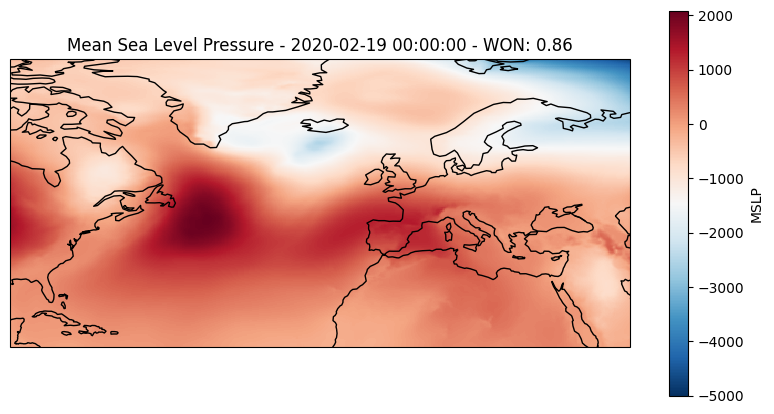

2020-02-20 00:00:00


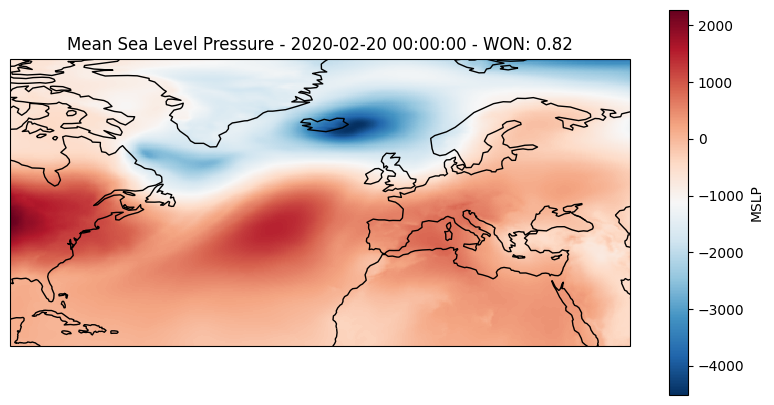

2020-02-23 00:00:00


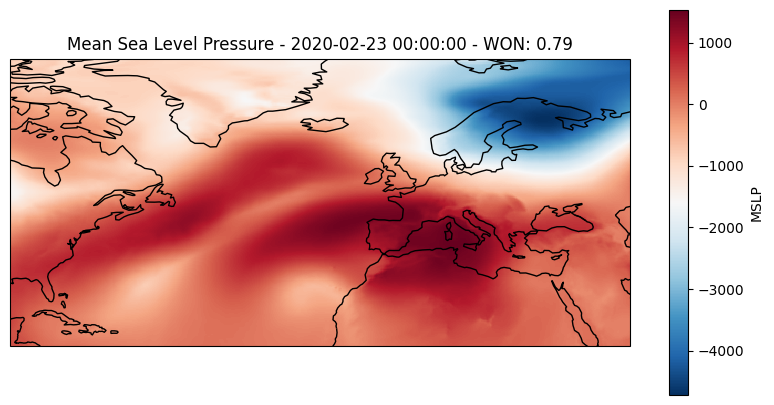

2020-02-24 00:00:00


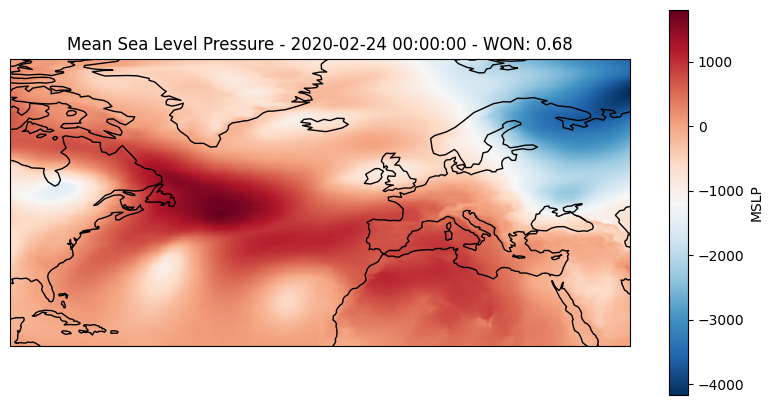

2020-02-25 00:00:00


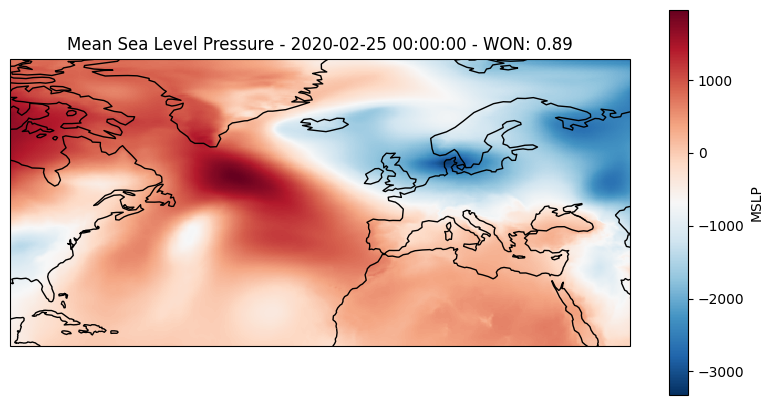

2020-02-26 00:00:00


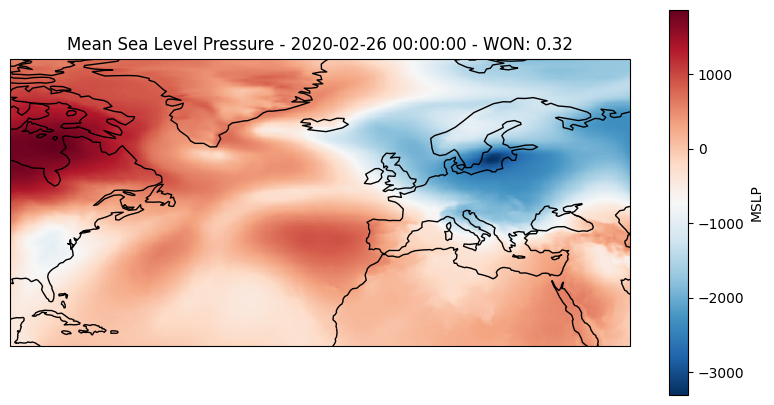

2020-02-27 00:00:00


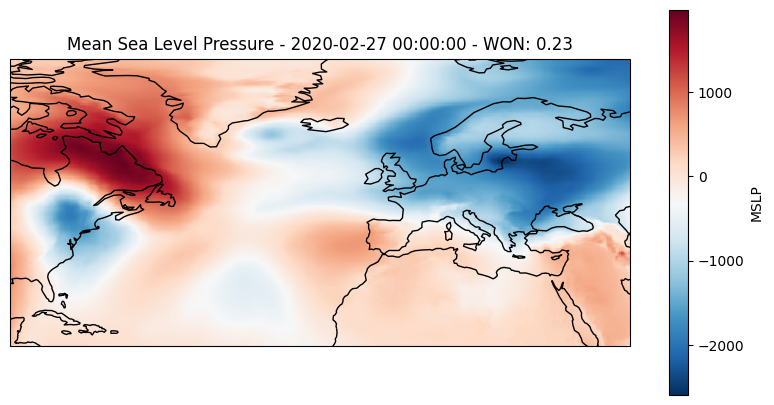

2020-02-28 00:00:00


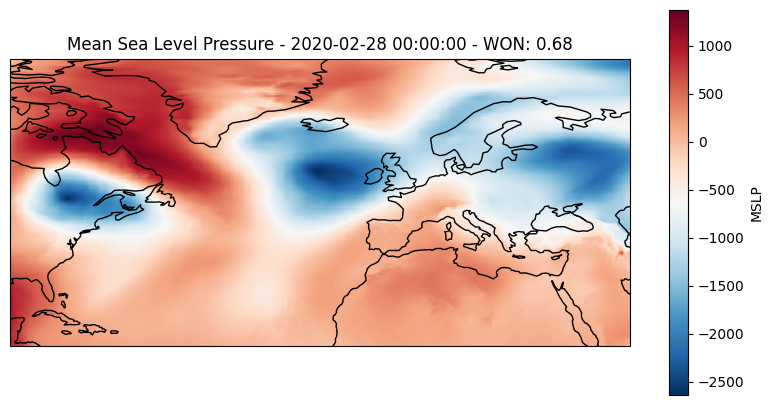

2020-02-29 00:00:00


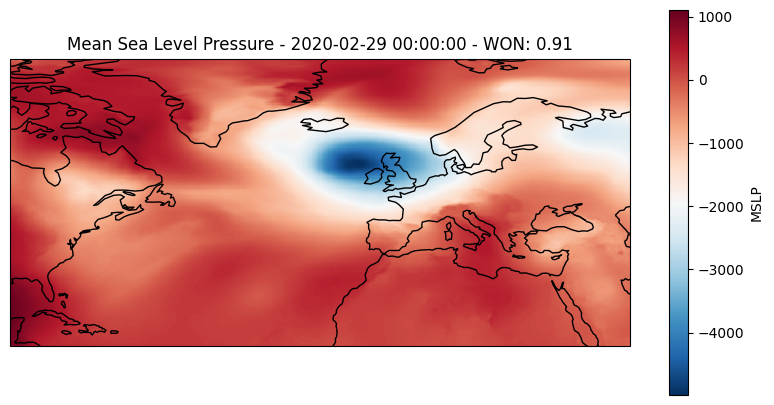

2020-12-26 00:00:00


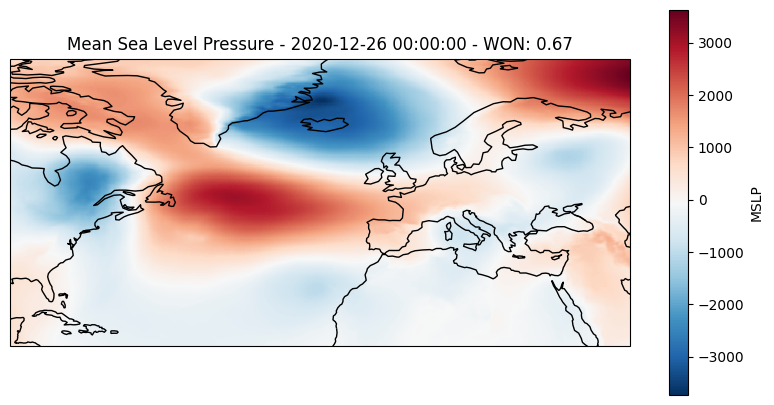

2021-01-22 00:00:00


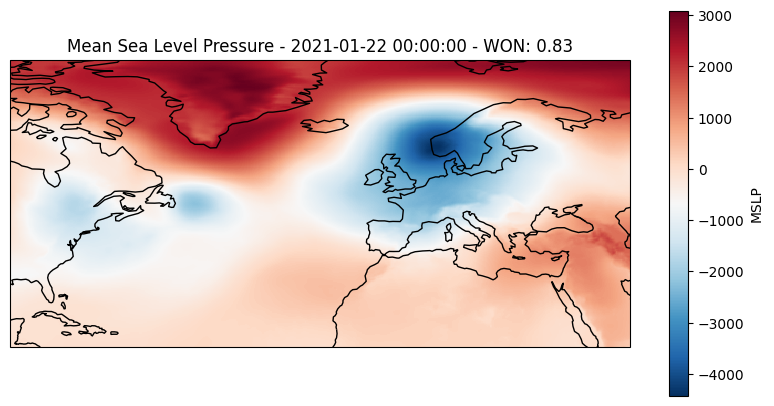

2021-12-01 00:00:00


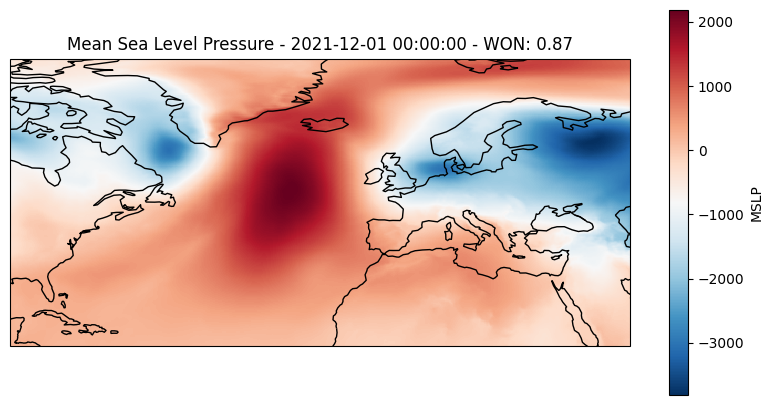

2021-12-02 00:00:00


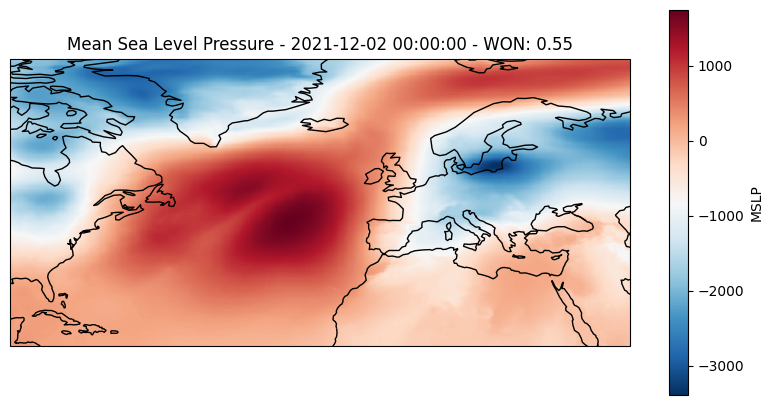

2021-12-03 00:00:00


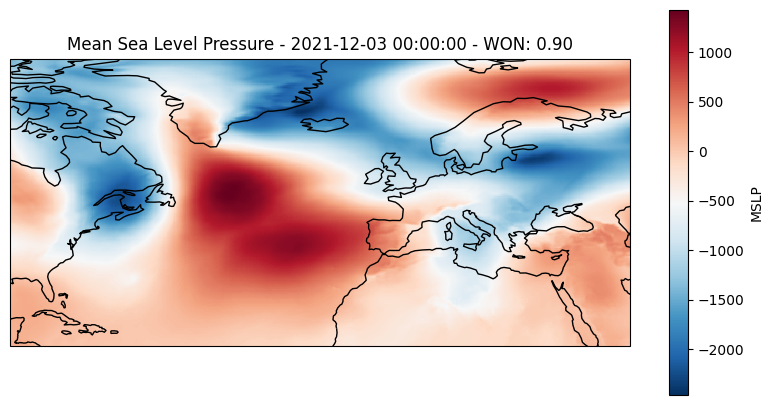

2022-01-02 00:00:00


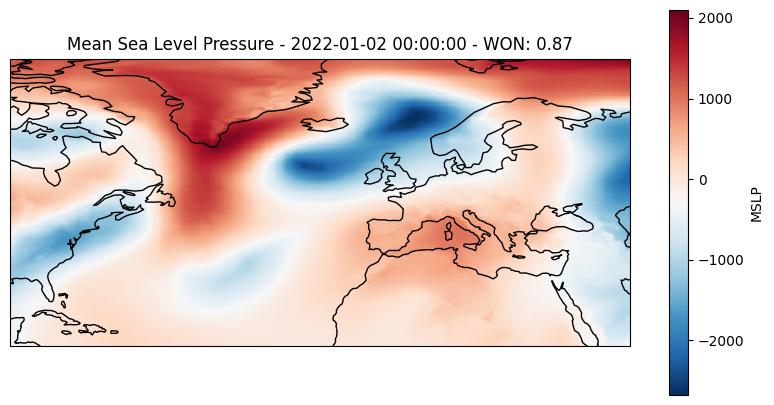

2022-01-03 00:00:00


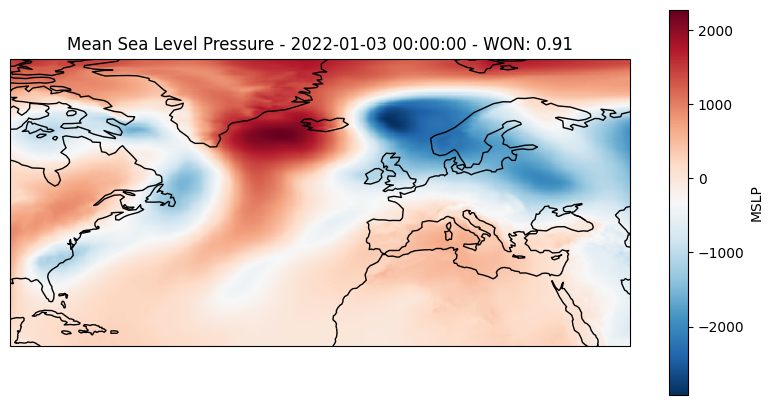

2022-01-04 00:00:00


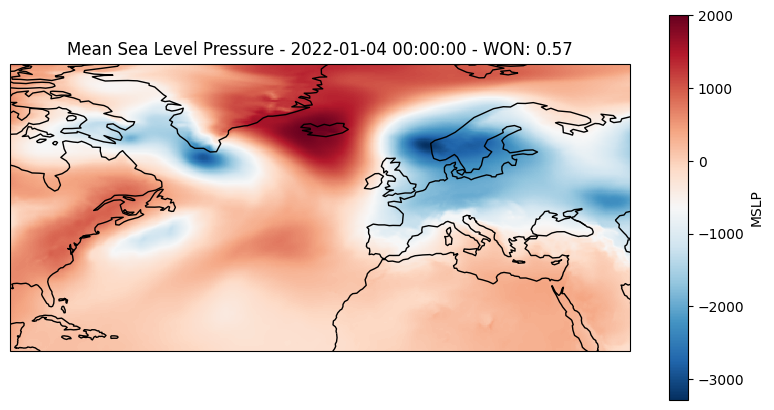

2022-01-05 00:00:00


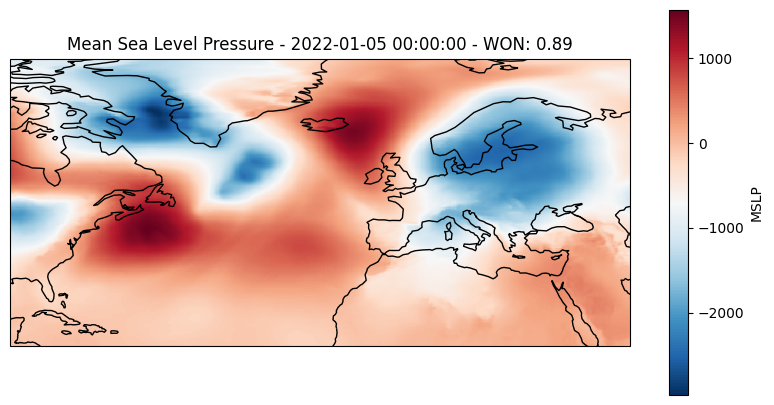

2022-01-06 00:00:00


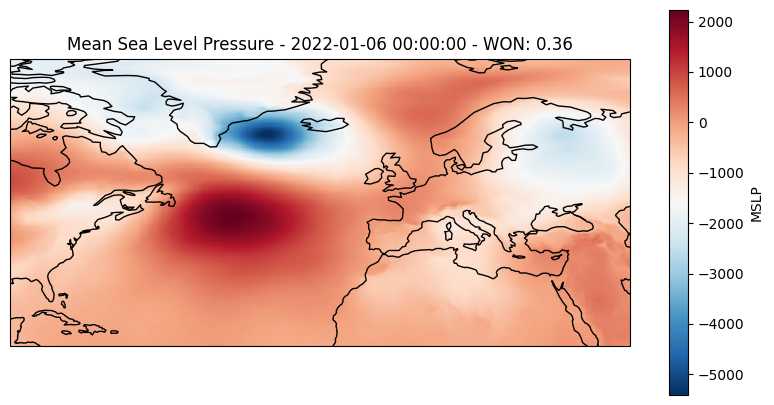

2022-01-07 00:00:00


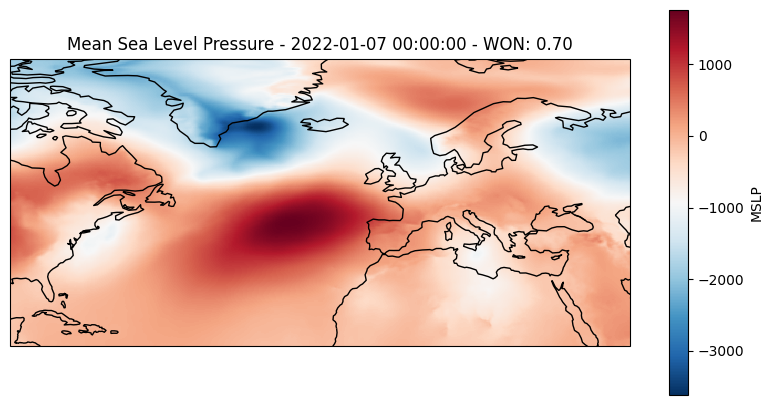

2022-01-08 00:00:00


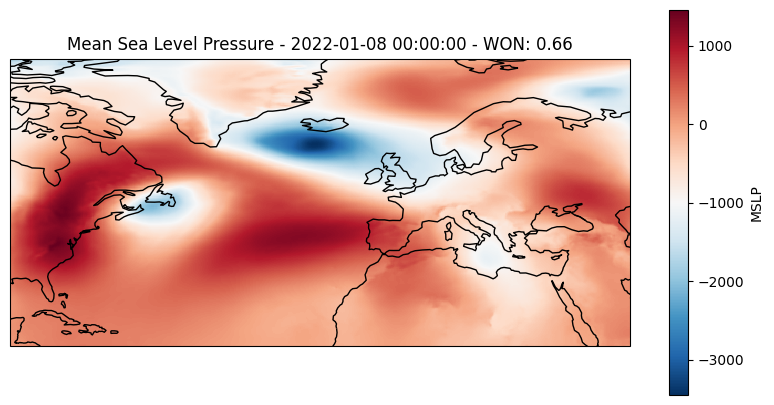

2022-01-13 00:00:00


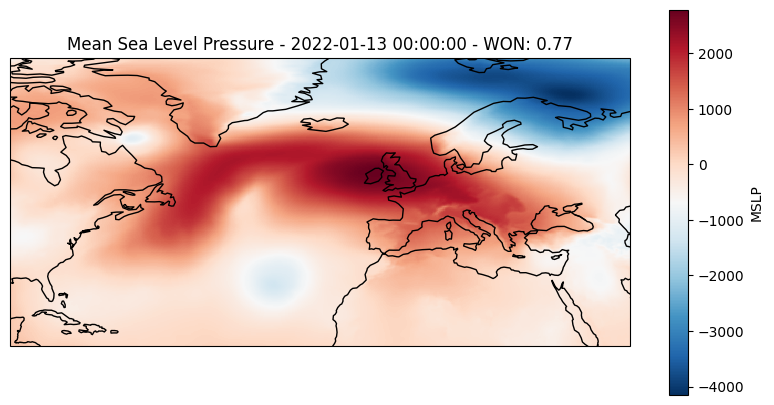

2022-01-14 00:00:00


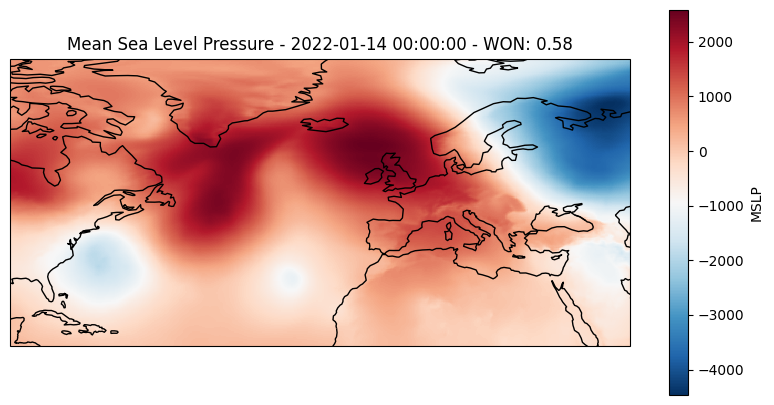

2022-01-16 00:00:00


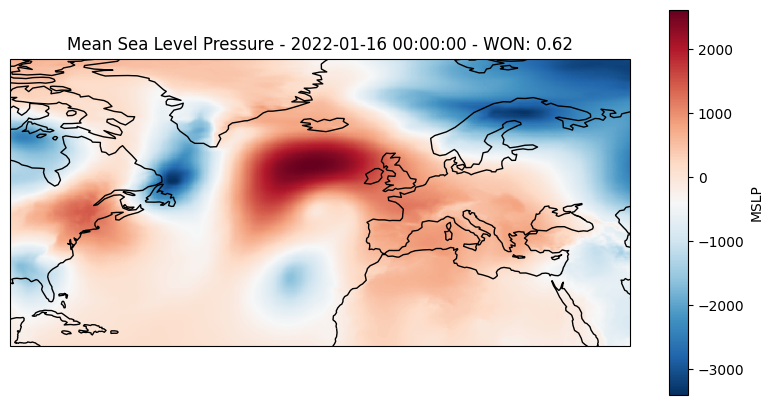

2022-01-17 00:00:00


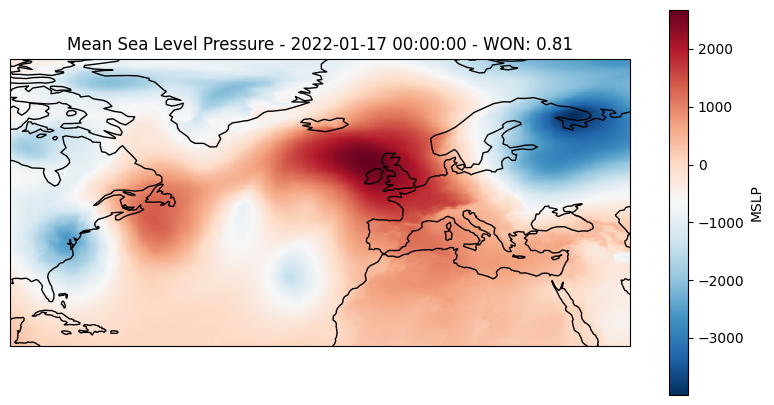

2022-01-19 00:00:00


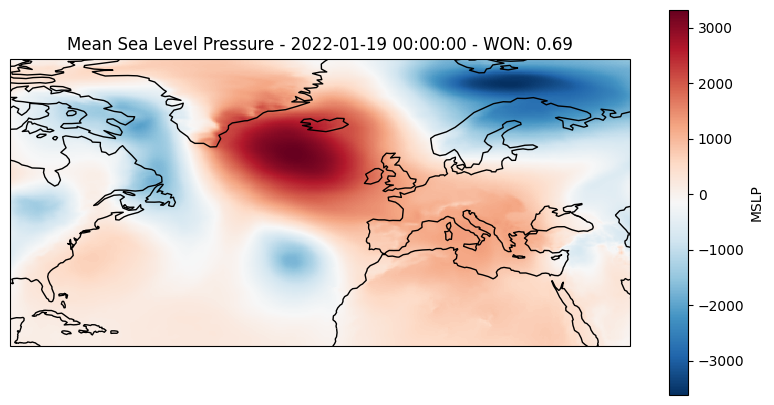

2022-01-30 00:00:00


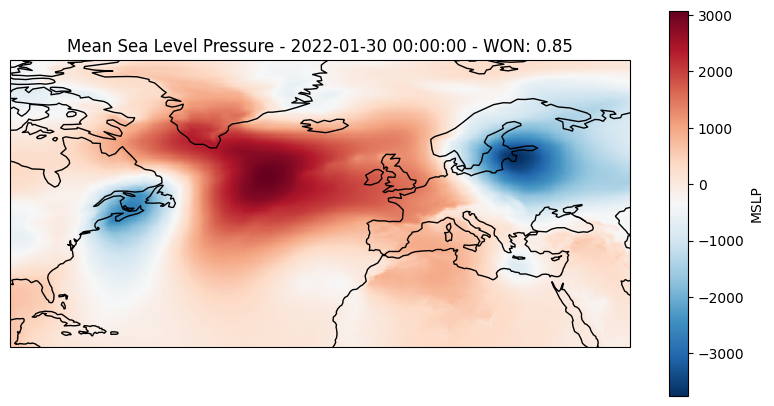

2022-01-31 00:00:00


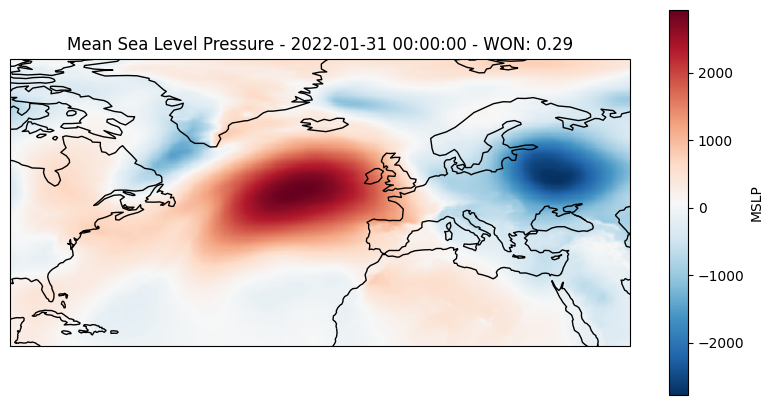

2022-02-01 00:00:00


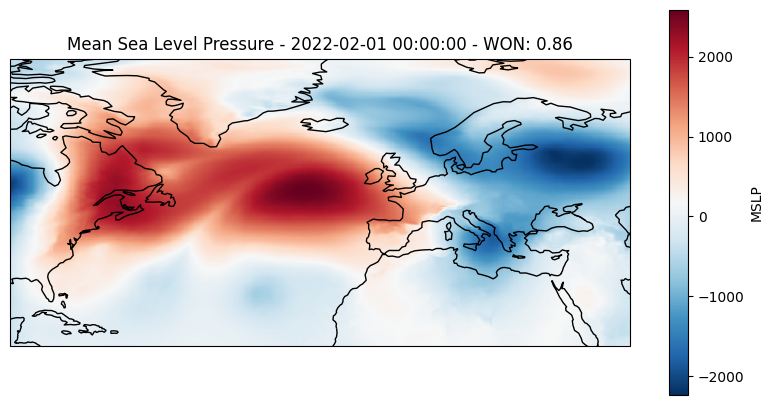

2022-02-02 00:00:00


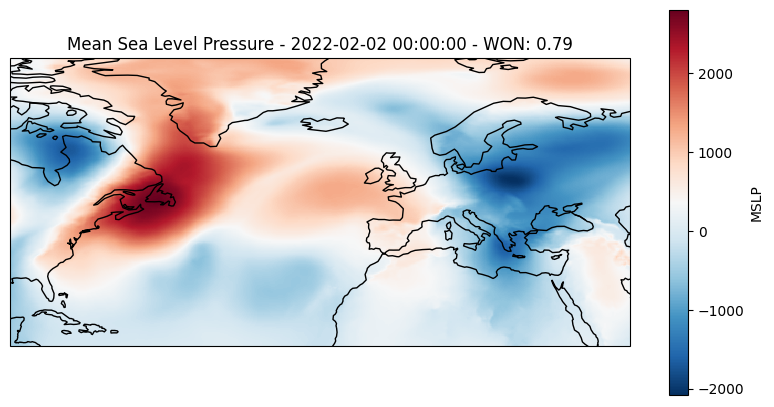

2022-02-03 00:00:00


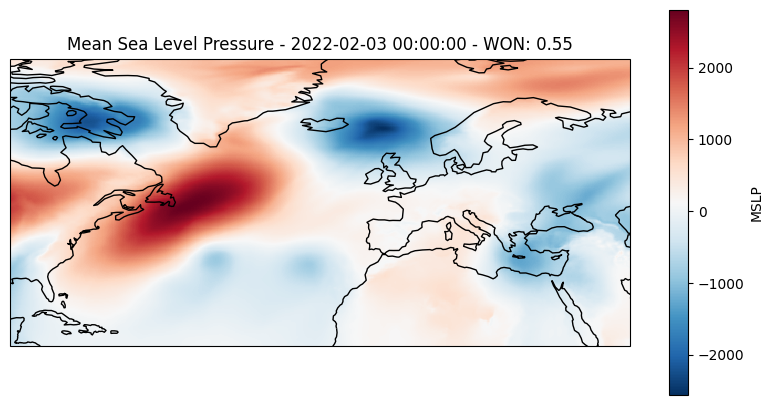

2022-02-04 00:00:00


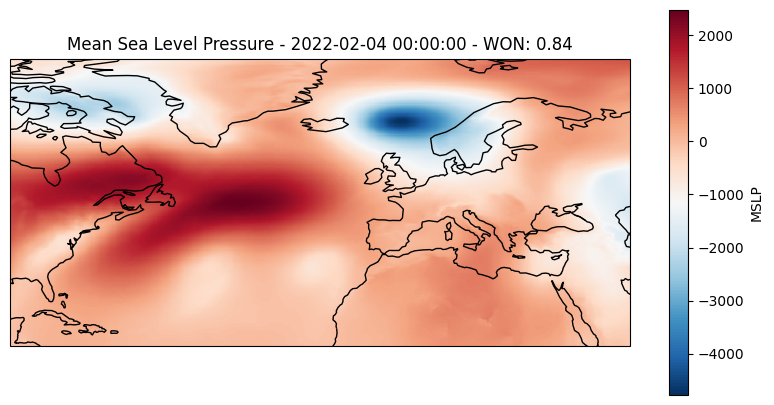

2022-02-07 00:00:00


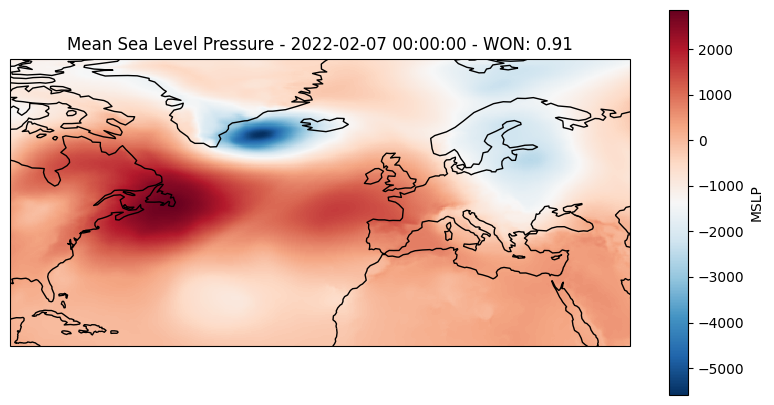

2022-02-08 00:00:00


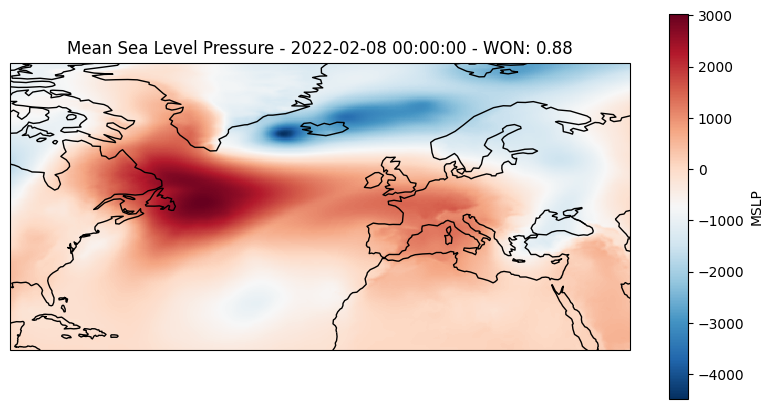

2022-02-09 00:00:00


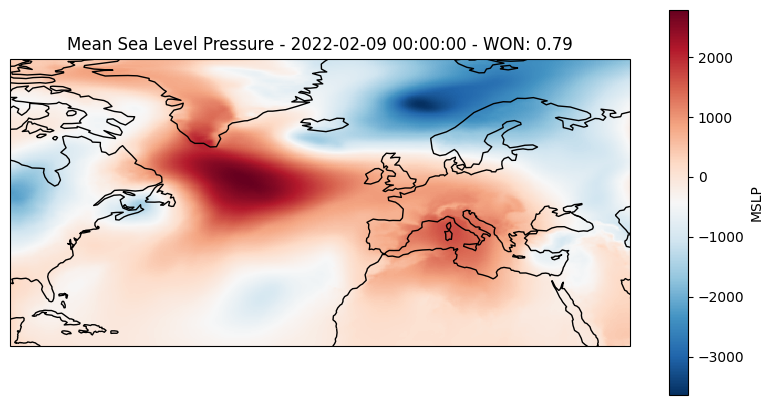

2022-02-10 00:00:00


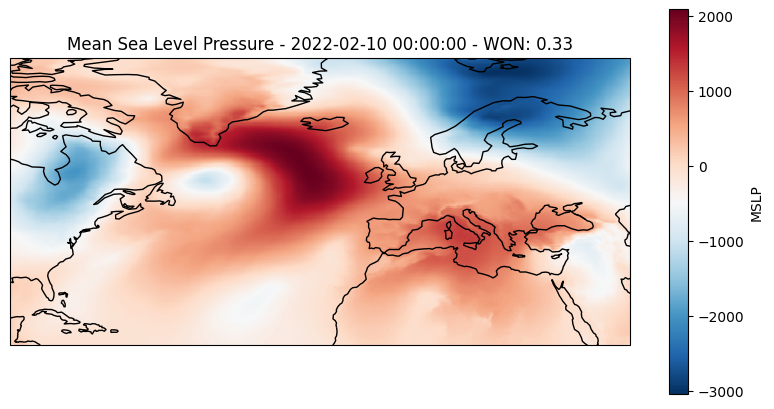

2022-02-11 00:00:00


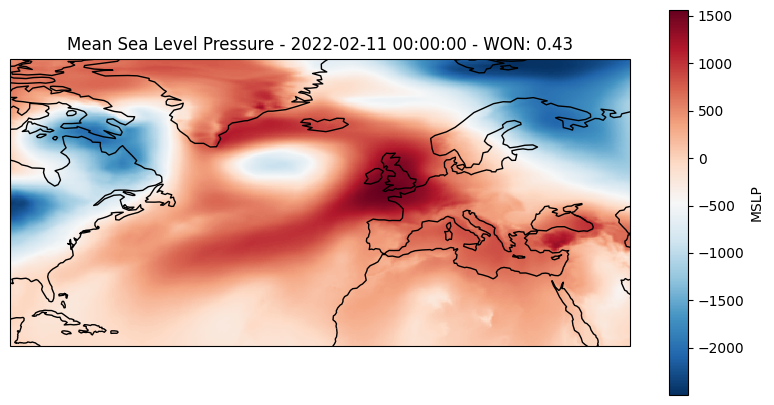

2022-02-12 00:00:00


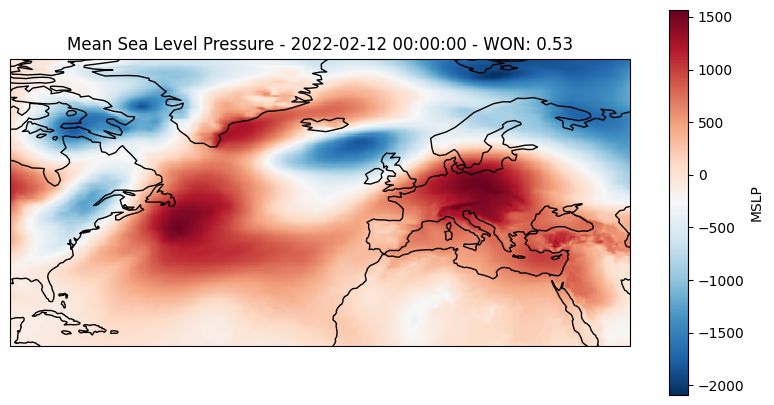

2022-02-13 00:00:00


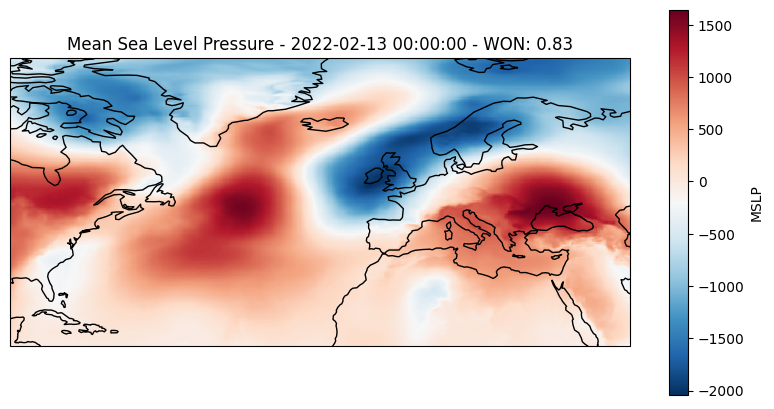

2022-02-14 00:00:00


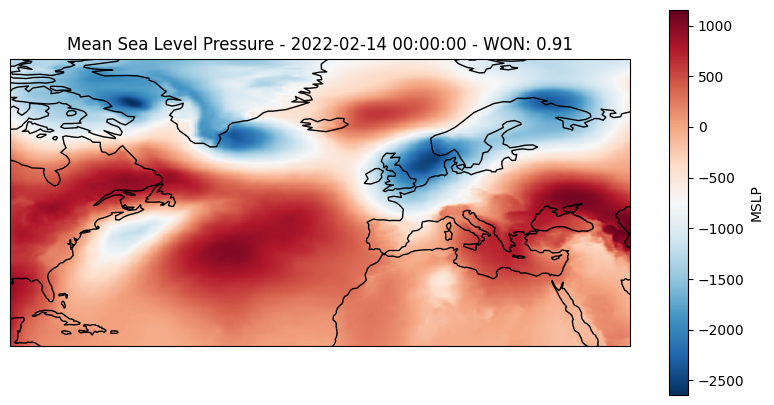

2022-02-15 00:00:00


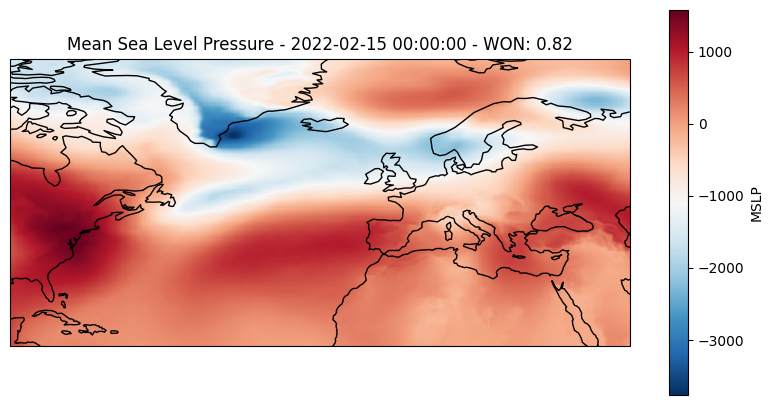

2022-02-16 00:00:00


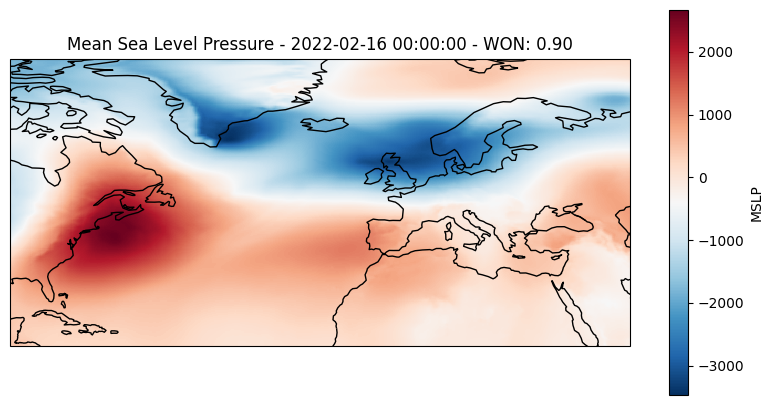

2022-02-18 00:00:00


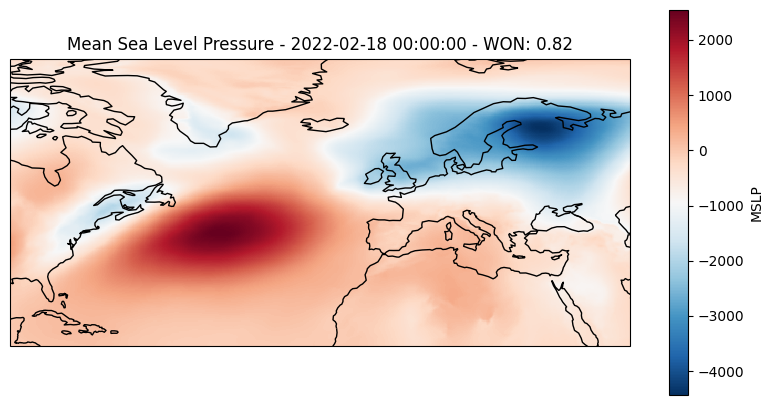

2022-02-19 00:00:00


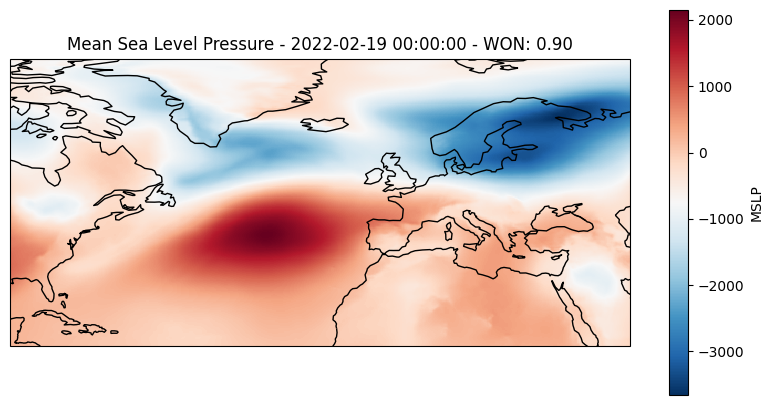

2022-02-20 00:00:00


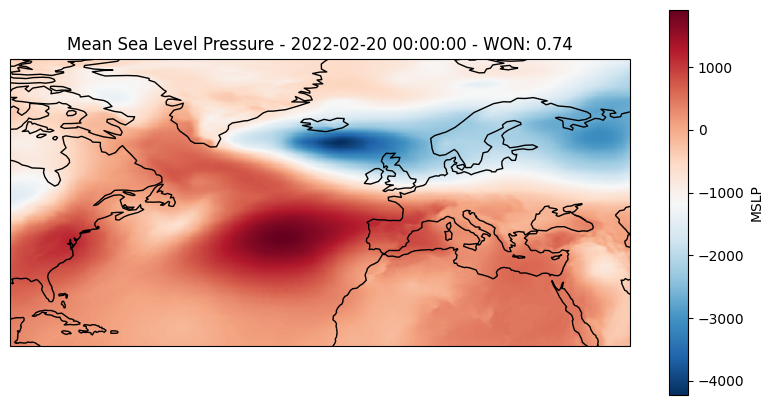

2022-02-22 00:00:00


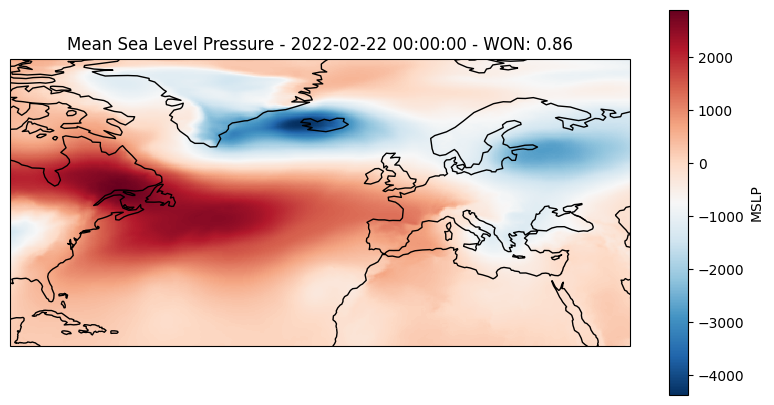

2022-02-23 00:00:00


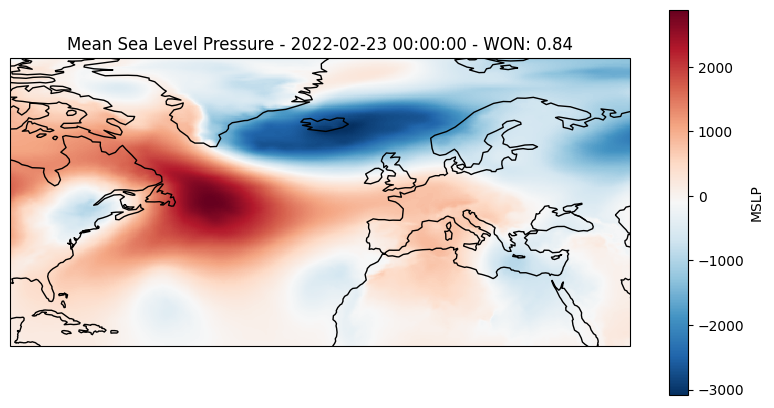

2022-02-24 00:00:00


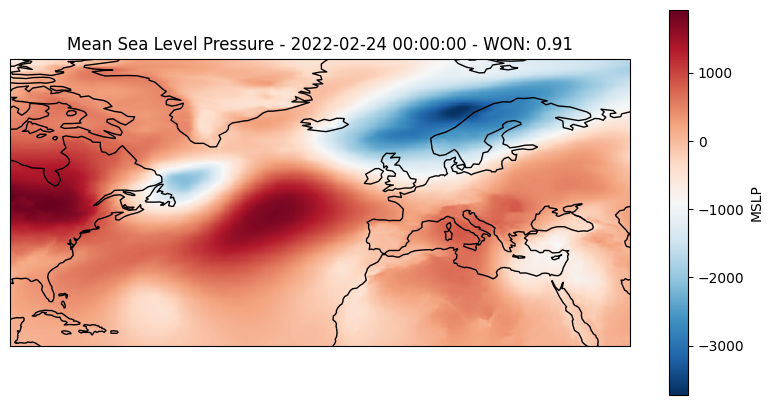

2022-02-25 00:00:00


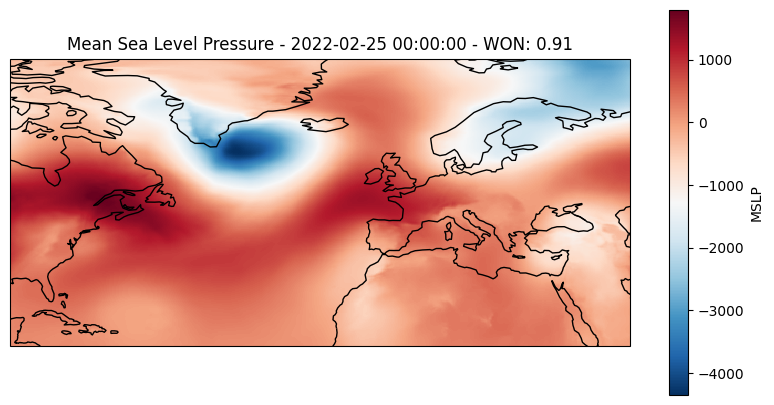

2022-12-22 00:00:00


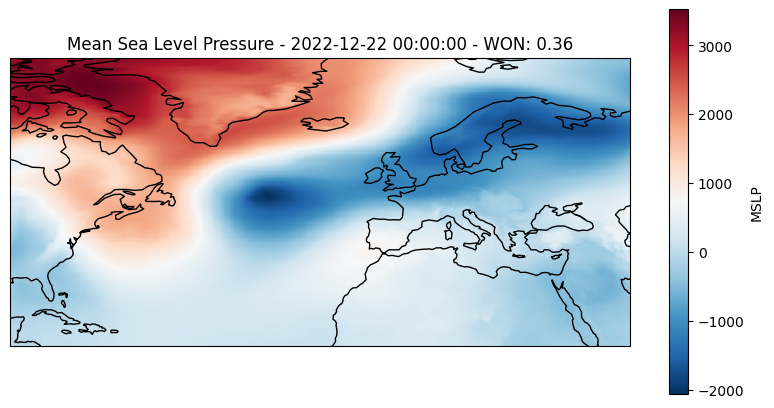

2022-12-23 00:00:00


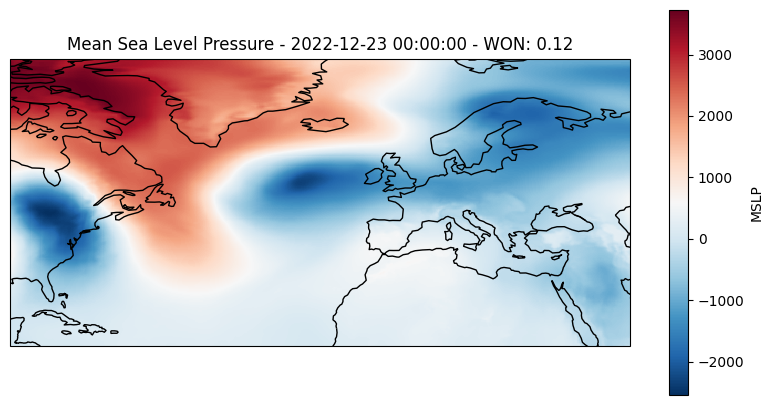

2022-12-27 00:00:00


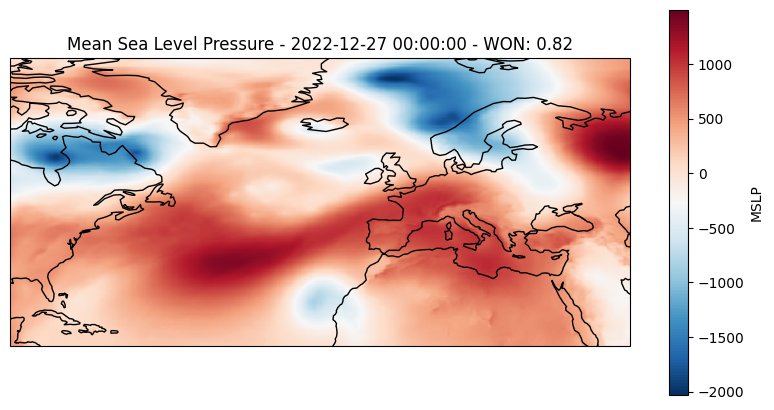

2022-12-30 00:00:00


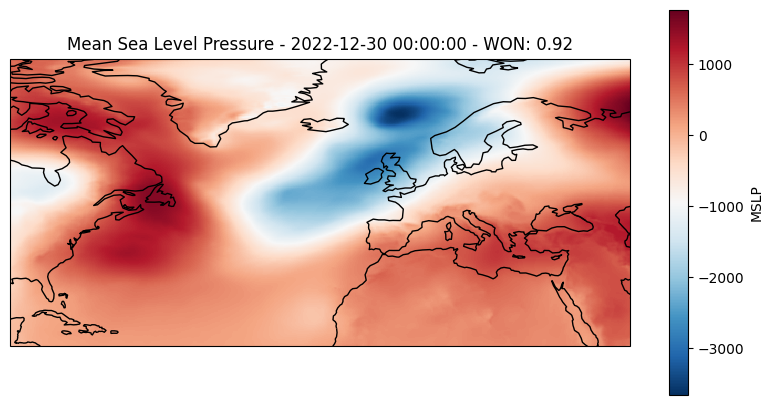

2022-12-31 00:00:00


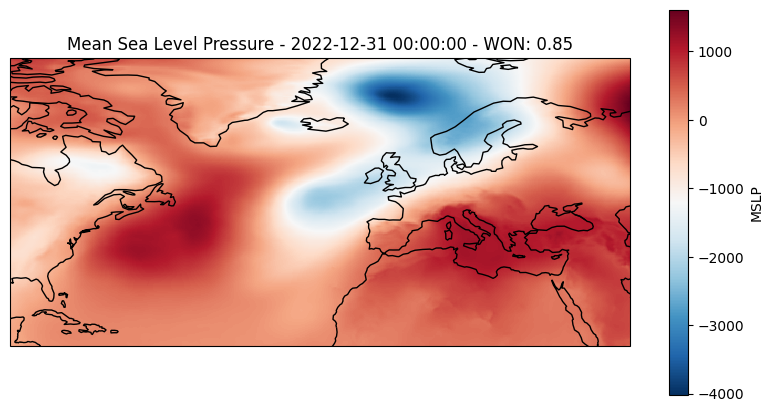

In [ ]:
# plot erstellen für alle zeitpunkte mit index > 0.5 und event = 0
time_false_positive = df_false_positives["time"]#df_false_positives["time"]
for tag in time_false_positive:
    print(tag)
    # aus ds_all den tag extrahieren und plotten
    won_an_dem_tag = df_false_positives[df_false_positives["time"] == tag]["WON"].values[0]
    ds_sel = ds_all.sel(time=tag)["mean_sea_level_pressure"]

    fig = plt.figure(figsize=(10,5))
    ax = plt.axes(projection=ccrs.PlateCarree())

    mesh = ax.pcolormesh(
        ds.longitude,
        ds.latitude,
        ds_sel,
        shading="auto",
        cmap="RdBu_r",
        transform=ccrs.PlateCarree()
    )

    ax.coastlines()
    # ax.set_global()
    ax.set_extent([-90, 50, 15, 80], crs=ccrs.PlateCarree())

    plt.colorbar(mesh, ax=ax, label="MSLP")
    plt.title(f"Mean Sea Level Pressure - {tag} - WON: {won_an_dem_tag:.2f}")

    saveas = Path(
        f"fig/quickplots/{energy_entry.name}/{extreme_event}/{var_name}/"
        f"False_Positive_Maps/{tag.date()}.png"
    )
    saveas.parent.mkdir(parents=True, exist_ok=True)

    plt.savefig(saveas, dpi=150, bbox_inches="tight")
    plt.show()

2016-01-03 00:00:00


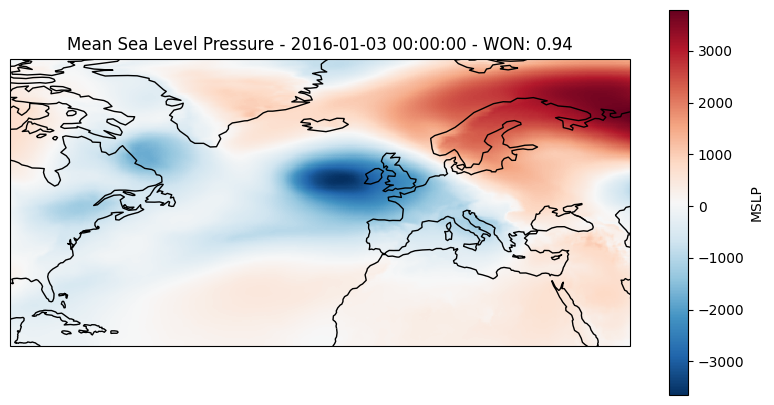

2021-01-13 00:00:00


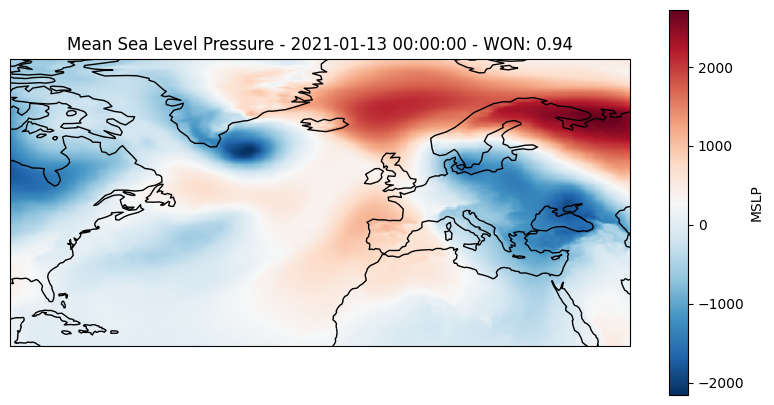

2021-02-07 00:00:00


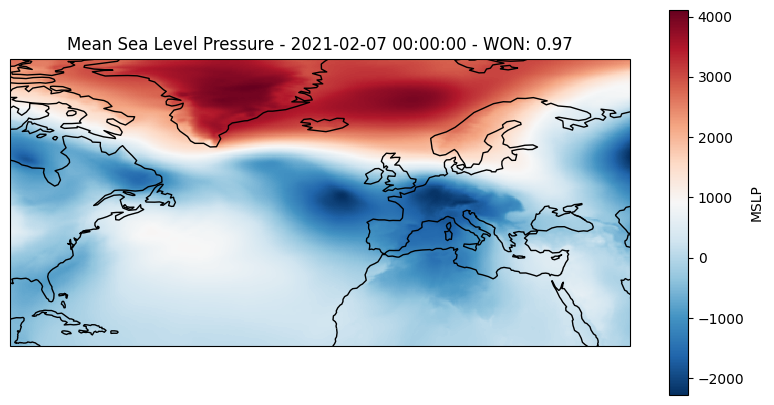

In [ ]:
# plot erstellen für alle zeitpunkte mit index > 0.5 und event = 0
time_false_negative = df_false_negative["time"]#df_false_positives["time"]
for tag in time_false_negative:
    print(tag)
    # aus ds_all den tag extrahieren und plotten
    won_an_dem_tag = df_false_negative[df_false_negative["time"] == tag]["WON"].values[0]
    ds_sel = ds_all.sel(time=tag)["mean_sea_level_pressure"]

    fig = plt.figure(figsize=(10,5))
    ax = plt.axes(projection=ccrs.PlateCarree())

    mesh = ax.pcolormesh(
        ds.longitude,
        ds.latitude,
        ds_sel,
        shading="auto",
        cmap="RdBu_r",
        transform=ccrs.PlateCarree()
    )

    ax.coastlines()
    # ax.set_global()
    ax.set_extent([-90, 50, 15, 80], crs=ccrs.PlateCarree())

    plt.colorbar(mesh, ax=ax, label="MSLP")
    plt.title(f"Mean Sea Level Pressure - {tag} - WON: {won_an_dem_tag:.2f}")

    saveas = Path(
        f"fig/quickplots/{energy_entry.name}/{extreme_event}/{var_name}/"
        f"False_Negative_Maps/{tag.date()}.png"
    )
    saveas.parent.mkdir(parents=True, exist_ok=True)

    plt.savefig(saveas, dpi=150, bbox_inches="tight")
    plt.show()

In [ ]:
df_false_positives[df_false_positives['WON'] > 0.7].time

32     2011-02-02
33     2011-02-03
35     2011-02-05
36     2011-02-06
38     2011-02-08
          ...    
1047   2022-02-24
1048   2022-02-25
1078   2022-12-27
1081   2022-12-30
1082   2022-12-31
Name: time, Length: 154, dtype: datetime64[us]

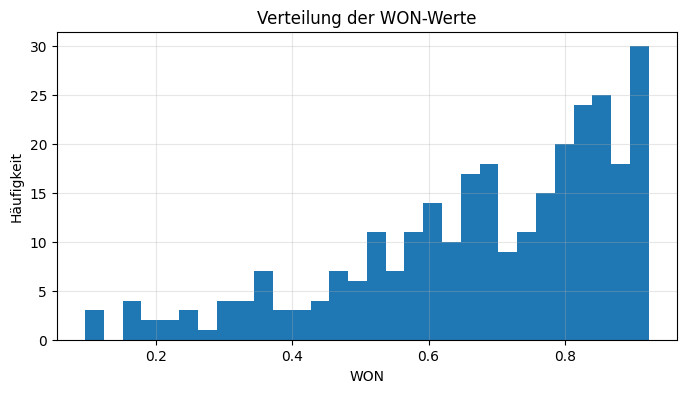

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(df_false_positives["WON"].dropna(), bins=30)
plt.xlabel("WON")
plt.ylabel("Häufigkeit")
plt.title("Verteilung der WON-Werte")
plt.grid(alpha=0.3)
plt.show()